# Proyecto 1: Análisis de señales ECG y detección de arritmias
**Bioseñales y Sistemas — Bioingeniería, Universidad de Antioquia — 2026-02**

Base de datos: Chapman University & Shaoxing People's Hospital [4], disponible en Figshare:
https://figshare.com/collections/ChapmanECG/4560497/1

**Organización del cuaderno**

| Sección | Contenido | Peso |
|---|---|---|
| 0 | Configuración (librerías y rutas) | — |
| 1 | Diagramas de flujo y metodologías de los 3 artículos | 20 % |
| 2 | Análisis estadístico de `Diagnostics.xlsx` | — |
| 3 | Fórmulas 1–4 (biespectro) y significado del biespectro | 20 % |
| 4 | Frecuencia de máxima potencia (fMP) | 15 % |
| 5 | Suma de frecuencias significativas en bicoherencia (sFSB) | 10 % |
| 6 | Rutina sobre toda la base → DataFrame | 10 % |
| 7 | Estadística descriptiva por arritmia | 5 % |
| 8 | Pruebas estadísticas | 5 % |
| 9 | Análisis de resultados y conclusiones | 15 % |

## 0. Configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.stats import chi2_contingency, fisher_exact
from scipy.stats import kruskal, skew
from scipy.stats import chi2 as dist_chi2
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import spearmanr
from scipy.stats import mannwhitneyu, normaltest
from itertools import combinations

# Rutas: ajústalas a donde guardaste los archivos descargados de Figshare
RUTA_DIAGNOSTICOS = "Diagnostics.xlsx"                            # archivo con etiquetas y datos clínicos
CARPETA_ECG       = os.path.join("ChapmanECG", "ECGDataDenoised")  # carpeta con los .csv de las señales
FS = 500                                                          # frecuencia de muestreo de la base (Hz)

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
print("Carpeta del notebook:       ", os.getcwd())
print("Diagnostics.xlsx encontrado:", os.path.exists(RUTA_DIAGNOSTICOS))
print("Carpeta ECG encontrada:     ", os.path.isdir(CARPETA_ECG))

Carpeta del notebook:        c:\Users\Valentina Garcia\OneDrive - Universidad de Antioquia\2026-2\Bioseñales\Laboratorio2026_2\Proyecto
Diagnostics.xlsx encontrado: True
Carpeta ECG encontrada:      True


---
# 1. Revisión de artículos: diagramas de flujo y metodologías

La siguiente función dibuja un diagrama de flujo vertical. Cada etapa es una tupla `(título, detalle, categoría)`, donde la categoría define el color:
- `datos` (gris): adquisición y organización de los datos
- `proc` (morado): procesamiento de la señal y extracción de características
- `modelo` (verde azulado): modelado, validación y evaluación

In [2]:
COLORES = {"datos": ("#F1EFE8", "#5F5E5A"),
           "proc":  ("#EEEDFE", "#534AB7"),
           "modelo":("#E1F5EE", "#0F6E56")}

def dibujar_flujo(etapas, titulo, ancho=6.5):
    n = len(etapas)
    alto_caja, sep = 0.9, 0.45
    fig, ax = plt.subplots(figsize=(ancho, n * (alto_caja + sep) * 0.75 + 0.8))
    y_total = n * (alto_caja + sep)
    ax.set_xlim(0, 10); ax.set_ylim(0, y_total + 0.4); ax.axis("off")
    for i, (tit, det, cat) in enumerate(etapas):
        y = y_total - (i + 1) * (alto_caja + sep) + sep
        relleno, borde = COLORES[cat]
        ax.add_patch(FancyBboxPatch((1, y), 8, alto_caja, boxstyle="round,pad=0.02,rounding_size=0.15",
                                    fc=relleno, ec=borde, lw=1.2))
        ax.text(5, y + alto_caja * 0.66, tit, ha="center", va="center", fontsize=10.5,
                fontweight="bold", color=borde)
        ax.text(5, y + alto_caja * 0.28, det, ha="center", va="center", fontsize=9, color="#2C2C2A")
        if i < n - 1:
            ax.annotate("", xy=(5, y - sep + 0.05), xytext=(5, y - 0.03),
                        arrowprops=dict(arrowstyle="-|>", color="#5F5E5A", lw=1.2))
    ax.set_title(titulo, fontsize=11.5, fontweight="bold")
    plt.tight_layout(); plt.show()

## 1.1 Artículo 1 — Gadaleta et al. [1]

Referencia completa en la lista final: [1].

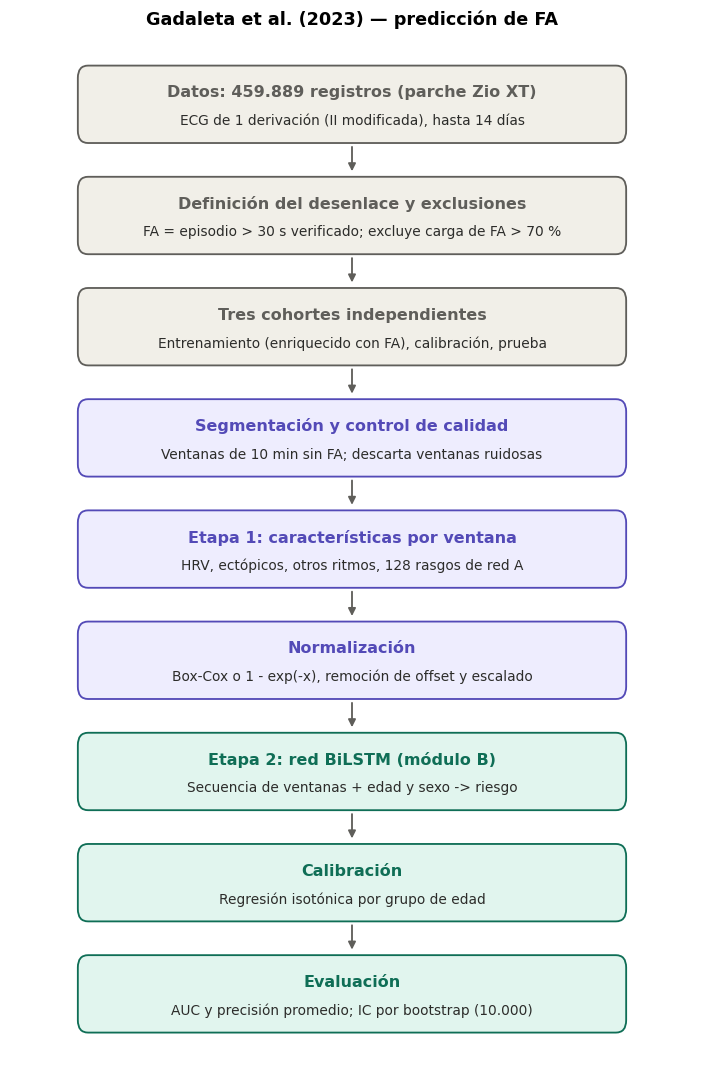

In [3]:
etapas_gadaleta = [
    ("Datos: 459.889 registros (parche Zio XT)", "ECG de 1 derivación (II modificada), hasta 14 días", "datos"),
    ("Definición del desenlace y exclusiones", "FA = episodio > 30 s verificado; excluye carga de FA > 70 %", "datos"),
    ("Tres cohortes independientes", "Entrenamiento (enriquecido con FA), calibración, prueba", "datos"),
    ("Segmentación y control de calidad", "Ventanas de 10 min sin FA; descarta ventanas ruidosas", "proc"),
    ("Etapa 1: características por ventana", "HRV, ectópicos, otros ritmos, 128 rasgos de red A", "proc"),
    ("Normalización", "Box-Cox o 1 - exp(-x), remoción de offset y escalado", "proc"),
    ("Etapa 2: red BiLSTM (módulo B)", "Secuencia de ventanas + edad y sexo -> riesgo", "modelo"),
    ("Calibración", "Regresión isotónica por grupo de edad", "modelo"),
    ("Evaluación", "AUC y precisión promedio; IC por bootstrap (10.000)", "modelo"),
]
dibujar_flujo(etapas_gadaleta, "Gadaleta et al. (2023) — predicción de FA")

**Explicación de la metodología**

Gadaleta et al. [1] proponen un modelo cuyo objetivo no es clasificar arritmias sino **predecir** si una persona presentará fibrilación auricular (FA) en una ventana de dos semanas, analizando únicamente tramos de ECG en los que la FA no aparece. La motivación clínica es que la FA paroxística es intermitente: un monitoreo puede salir negativo aunque el paciente sí la tenga.

1. **Datos.** Registros retrospectivos de un parche ambulatorio de una derivación (II modificada) de hasta 14 días, tomados entre 2019 y 2022. Un registro se considera positivo si contiene al menos un episodio de FA mayor a 30 s verificado por un técnico certificado. FA y flutter auricular se agrupan en una misma clase. Se excluyen pacientes con FA persistente o casi persistente (carga > 70 %).
2. **Cohortes.** Se separan sin solapamiento de individuos: entrenamiento (enriquecido con casos de FA para compensar el desbalance), calibración (prevalencia natural) y prueba (40.000 registros). Se entrena un modelo por grupo de edad (18–54, 55–64, 65–74, 75–84, 85–99) porque el riesgo basal cambia mucho con la edad.
3. **Segmentación y calidad.** La señal se divide en ventanas de 10 minutos; se descartan las que tienen frecuencia media < 20 lpm, más de 2 min de artefacto o muy pocos picos R para calcular la variabilidad.
4. **Etapa 1 – extracción de características por ventana:** métricas de variabilidad de la frecuencia cardíaca (HRV) a partir de los picos R, conteo de latidos ectópicos auriculares y ventriculares, presencia de otros ritmos anormales, y 128 características aprendidas por una red profunda (módulo A) cuyos pesos se congelan después de entrenarla.
5. **Normalización.** Las variables tienen escalas y distribuciones distintas: las de tipo exponencial (cargas de ritmo) se transforman con $1-e^{-x}$ y el resto con Box-Cox para acercarlas a una distribución normal.
6. **Etapa 2 – integración temporal.** La secuencia de vectores de las ventanas entra a una red LSTM bidireccional de dos capas (módulo B) junto con edad y sexo, que entrega un puntaje de riesgo.
7. **Calibración.** Como el entrenamiento se hizo con más FA de la real, el puntaje se convierte en probabilidad mediante regresión isotónica usando la cohorte de prevalencia natural.
8. **Evaluación.** AUC-ROC y precisión promedio, con intervalos de confianza del 95 % por bootstrap y comparación de modelos mediante bootstrap pareado.

**Resultados principales.** Con 1 día de ECG, el modelo con todas las características alcanza AUC = 0,80 frente a 0,67 del modelo con solo edad y sexo. El modelo con únicamente las características de la red profunda casi iguala al completo. El desempeño es mejor en menores de 65 años (AUC 0,86) que en mayores (0,72), y mejora con ventanas más largas y con mayor carga de FA [1].

**Relación con este proyecto.** Agrupa FA y flutter igual que Zheng et al. [2], muestra la importancia de la edad como variable de confusión y usa una sola derivación (II), la misma que se analizará en este proyecto.

## 1.2 Artículo 2 — Zheng et al. [2]

Referencia completa en la lista final: [2].

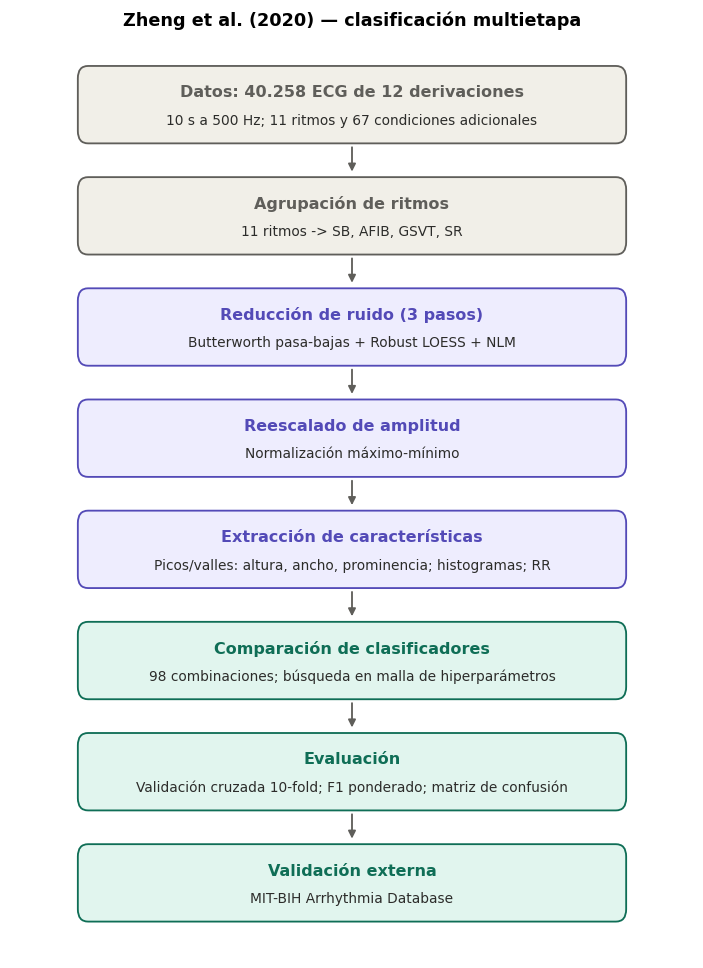

In [4]:
etapas_zheng = [
    ("Datos: 40.258 ECG de 12 derivaciones", "10 s a 500 Hz; 11 ritmos y 67 condiciones adicionales", "datos"),
    ("Agrupación de ritmos", "11 ritmos -> SB, AFIB, GSVT, SR", "datos"),
    ("Reducción de ruido (3 pasos)", "Butterworth pasa-bajas + Robust LOESS + NLM", "proc"),
    ("Reescalado de amplitud", "Normalización máximo-mínimo", "proc"),
    ("Extracción de características", "Picos/valles: altura, ancho, prominencia; histogramas; RR", "proc"),
    ("Comparación de clasificadores", "98 combinaciones; búsqueda en malla de hiperparámetros", "modelo"),
    ("Evaluación", "Validación cruzada 10-fold; F1 ponderado; matriz de confusión", "modelo"),
    ("Validación externa", "MIT-BIH Arrhythmia Database", "modelo"),
]
dibujar_flujo(etapas_zheng, "Zheng et al. (2020) — clasificación multietapa")

**Explicación de la metodología**

Zheng et al. [2] buscan la mejor "receta" completa (limpieza → características → clasificador) para clasificar el ritmo cardíaco, comparando de forma exhaustiva muchas combinaciones.

1. **Datos.** ECG de 12 derivaciones, 10 s a 500 Hz, de dos hospitales de Zhejiang (China), etiquetados por cardiólogos con 11 ritmos y 67 condiciones adicionales. Los grupos de edad más frecuentes fueron 51–60, 61–70 y 71–80 años.
2. **Agrupación de ritmos.** Por la baja frecuencia de algunos ritmos, y siguiendo criterio médico, los 11 ritmos se fusionan en 4 grupos:
   - **SB**: bradicardia sinusal.
   - **AFIB**: fibrilación auricular + flutter auricular (suelen coexistir).
   - **GSVT**: taquicardias supraventriculares (SVT, AT, AVNRT, AVRT) y marcapasos auricular migratorio.
   - **SR**: ritmo sinusal + irregularidad sinusal.
3. **Reducción de ruido en tres pasos:**
   - Filtro Butterworth pasa-bajas para eliminar ruido de alta frecuencia (> 50 Hz).
   - Robust LOESS (regresión local robusta) para eliminar la deriva de línea base (< 0,5 Hz, asociada a la respiración).
   - Non-Local Means (NLM): reconstruye cada muestra como un promedio ponderado de otras muestras cuyo "parche" vecino es parecido; aprovecha la casi periodicidad del ECG. El parámetro de suavizado se fija a partir de una estimación robusta de la desviación del ruido (MAD).

   *Esta es la limpieza que ya tienen los archivos de `ECGDataDenoised` [4], por lo que en este proyecto no es necesario repetirla.*
4. **Reescalado.** Normalización máximo-mínimo de la amplitud para reducir la variabilidad entre personas.
5. **Extracción de características (derivación II).** Se detectan picos y valles (máximos y mínimos locales), se separan en complejos QRS, picos no-QRS y valles, y se mide altura, ancho y prominencia. Se calculan cocientes entre pares (diferencia de altura, ancho o prominencia sobre diferencia de tiempo) y, como cada paciente tiene un número distinto de picos, estas distribuciones se resumen en histogramas de 100 intervalos. Se añaden media y varianza de los intervalos RR, número de latidos, edad y sexo. Se probaron 11 grupos de características (de 11 a 39.830 variables).
6. **Clasificación.** Se comparan 98 combinaciones de clasificadores (árboles, KNN, SVM, Random Forest, AdaBoost, Gradient Boosting, XGBoost, entre otros) y estrategias multiclase (uno-contra-todos, uno-contra-uno, códigos de corrección de errores), con búsqueda en malla de hiperparámetros.
7. **Evaluación.** Validación cruzada de 10 particiones (80 % / 20 %) y F1 ponderado por el número de casos de cada clase.

**Resultados principales.** XGBoost obtuvo F1 = 0,988 en pacientes sin condiciones cardíacas adicionales; Gradient Boosting obtuvo F1 = 0,97 en pacientes con condiciones adicionales (bloqueos de rama, extrasístoles), que reducen el desempeño. Usar 12 derivaciones mejora el F1 en 1,4 % frente a una sola. En la validación externa con MIT-BIH obtuvieron F1 = 0,992 [2].

**Relación con este proyecto.** Es el artículo de referencia de la base de datos usada; su agrupación en 4 clases es el criterio recomendado para seleccionar el subconjunto de datos del punto 2.

## 1.3 Artículo 3 — Liu et al. [3]

Referencia completa en la lista final: [3].

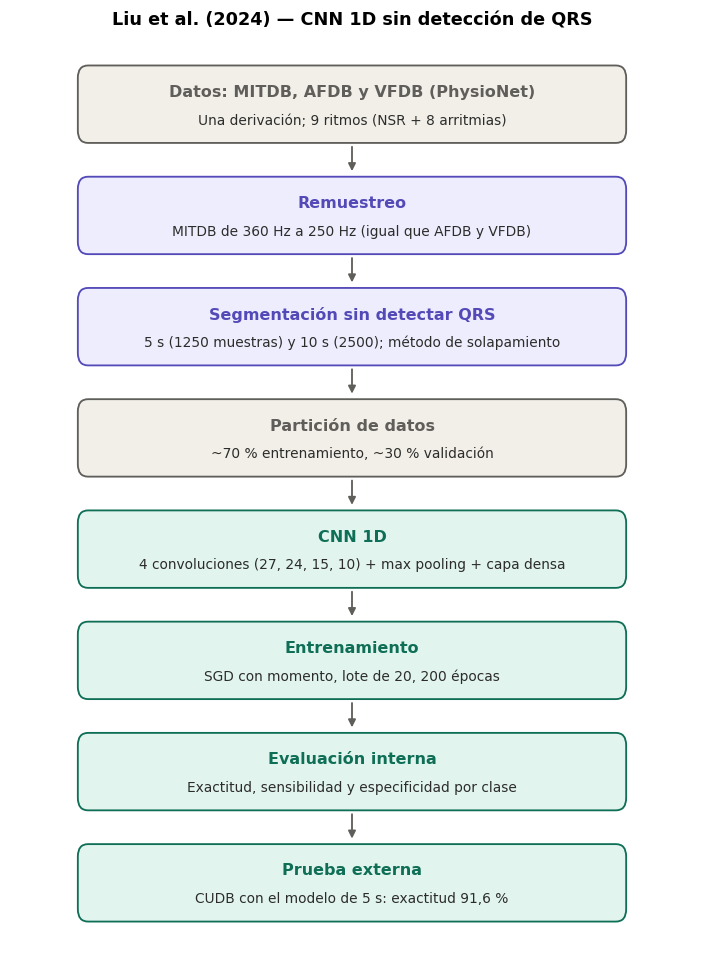

In [5]:
etapas_liu = [
    ("Datos: MITDB, AFDB y VFDB (PhysioNet)", "Una derivación; 9 ritmos (NSR + 8 arritmias)", "datos"),
    ("Remuestreo", "MITDB de 360 Hz a 250 Hz (igual que AFDB y VFDB)", "proc"),
    ("Segmentación sin detectar QRS", "5 s (1250 muestras) y 10 s (2500); método de solapamiento", "proc"),
    ("Partición de datos", "~70 % entrenamiento, ~30 % validación", "datos"),
    ("CNN 1D", "4 convoluciones (27, 24, 15, 10) + max pooling + capa densa", "modelo"),
    ("Entrenamiento", "SGD con momento, lote de 20, 200 épocas", "modelo"),
    ("Evaluación interna", "Exactitud, sensibilidad y especificidad por clase", "modelo"),
    ("Prueba externa", "CUDB con el modelo de 5 s: exactitud 91,6 %", "modelo"),
]
dibujar_flujo(etapas_liu, "Liu et al. (2024) — CNN 1D sin detección de QRS")

**Explicación de la metodología**

Los métodos clásicos de detección automática de arritmias dependen de localizar primero el complejo QRS; si esa detección falla (por ruido o por morfologías muy anormales, como en la fibrilación ventricular), todo el análisis posterior falla. Liu et al. [3] eliminan ese paso: alimenta segmentos de duración fija de una sola derivación directamente a una red neuronal convolucional unidimensional (CNN 1D), que aprende por sí misma los patrones que distinguen cada ritmo.

1. **Datos.** Se extraen 9 ritmos de tres bases de PhysioNet usando el paquete WFDB: MIT-BIH Arrhythmia Database (MITDB), Atrial Fibrillation Database (AFDB) y MIT-BIH Ventricular Fibrillation Database (VFDB). Los ritmos son: ritmo sinusal normal (NSR), fibrilación auricular (AFIB), flutter auricular (AFL), Wolff-Parkinson-White (WPW), bloqueo AV Mobitz II (MII), bradicardia sinusal (SB), taquicardia ventricular (VT), fibrilación ventricular (VF) y flutter ventricular (VFL).
2. **Remuestreo.** MITDB está a 360 Hz y las otras dos a 250 Hz, así que se submuestrea MITDB a 250 Hz para que todas las señales sean comparables.
3. **Segmentación.** Se cortan segmentos de 5 s (1250 muestras) y de 10 s (2500 muestras) sin buscar latidos. Para los ritmos con pocos datos se usa un "método de solapamiento", que genera muestras nuevas uniendo segmentos consecutivos (una forma de aumento de datos).
4. **Partición.** Para 5 s: 5734 muestras de entrenamiento y 2568 de validación (8302 en total); para 10 s: 5934 y 2525 (8459 en total). Es decir, aproximadamente 70 % / 30 %, con clases casi balanceadas (≈ 700–1000 muestras por ritmo).
5. **Arquitectura.** Cuatro capas convolucionales con filtros de tamaño 27, 24, 15 y 10, cada una seguida de max pooling de tamaño 2, y al final capas totalmente conectadas que entregan la clase. Por ejemplo, para la entrada de 5 s, la primera convolución produce un mapa de 1224 × 3 (1250 − 27 + 1 = 1224 posiciones, 3 filtros).
6. **Entrenamiento.** Descenso de gradiente estocástico con momento (SGDM), lote de 20 muestras, 200 épocas, con GPU.
7. **Evaluación interna.** Exactitud, sensibilidad y especificidad por clase, y matrices de confusión.
8. **Prueba externa.** Se aplica el modelo de 5 s a la base Creighton University Ventricular Tachyarrhythmia Database (CUDB), sin solapamiento, para estimar el desempeño con datos nunca vistos.

**Resultados principales.**
- Modelo de 10 s: exactitud por clase entre 95,3 % y 99,8 %. Las sensibilidades más bajas fueron las de NSR (78,8 %) y VF (70,9 %); casi todos los VF mal clasificados se confundieron con VT.
- Modelo de 5 s: sensibilidades entre 89,4 % (VT, que se confunde sobre todo con VF) y 100 %, y especificidades entre 98,7 % y 100 %. Los autores reportan que no hay diferencias estadísticamente significativas entre ambos modelos, por lo que prefieren el de 5 s porque permite una detección más rápida.
- Prueba externa (CUDB): exactitud promedio de 91,6 %; el error más frecuente fue clasificar AFIB como AFL [3].

**Relación con este proyecto.** Usa una sola derivación y segmentos de 10 s (igual que la base Chapman) y representa el enfoque de aprendizaje profundo con características aprendidas, en contraste con las características diseñadas de Zheng et al. [2]. También muestra que confusiones entre ritmos de morfología parecida (VT/VF, AFIB/AFL) son el principal reto, lo que justifica agrupar AFIB y AFL como hacen Zheng et al. [2].

## 1.4 Comparación de los tres enfoques

| Aspecto | Gadaleta et al. [1] | Zheng et al. [2] | Liu et al. [3] |
|---|---|---|---|
| Objetivo | Predecir FA futura | Clasificar 4 grupos de ritmo | Clasificar 9 ritmos |
| Datos | 459.889 registros (Zio XT) | 40.258 pacientes (Shaoxing y Ningbo) | MITDB, AFDB y VFDB (PhysioNet) |
| Derivaciones | 1 (II modificada) | 12 (y II por separado) | 1 |
| Frecuencia de muestreo | — | 500 Hz | 250 Hz (MITDB remuestreada) |
| Duración de la señal | 10 min a 24 h | 10 s | 5 s y 10 s |
| Preprocesamiento | Exclusión de ventanas ruidosas; Box-Cox | Butterworth + LOESS + NLM; reescalado | Remuestreo; segmentación con solapamiento |
| Características | HRV + ectópicos + aprendidas (DL) | Diseñadas (picos, valles, RR) | Aprendidas (CNN) |
| Clasificador | BiLSTM | XGBoost / Gradient Boosting | CNN 1D |
| Validación | Cohortes independientes + bootstrap | Validación cruzada 10-fold + MIT-BIH | ~70/30 + prueba externa CUDB |
| Resultado principal | AUC = 0,80 | F1 ponderado = 0,988 | Exactitud por clase 95,3–99,8 %; CUDB 91,6 % |

---
# 2. Análisis estadístico de `Diagnostics.xlsx`

## 2.1 Carga y revisión de la base de datos

La base de datos fue publicada por Zheng et al. [4] y contiene ECG de 12 derivaciones de 10 646 pacientes, registrados durante 10 s a 500 Hz en el Shaoxing People's Hospital (China). El archivo `Diagnostics.xlsx` tiene una fila por paciente con su ritmo cardíaco (`Rhythm`), condiciones adicionales (`Beat`), edad, sexo y mediciones automáticas del electrocardiógrafo (frecuencias, duraciones, ejes). La columna `FileName` corresponde al nombre del archivo `.csv` de la señal en la carpeta `ECGDataDenoised`.

Los conteos obtenidos (5956 hombres y 4690 mujeres) coinciden con los reportados por los autores [4], lo que confirma que el archivo se cargó completo.

In [6]:
# Leer el archivo de Excel y guardarlo en un DataFrame llamado "diag"
diag = pd.read_excel(RUTA_DIAGNOSTICOS)

print("Dimensiones (filas, columnas):", diag.shape)
print()
diag.info()        # tipo de dato y cantidad de valores no nulos por columna
diag.head()        # primeras 5 filas

Dimensiones (filas, columnas): (10646, 16)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10646 entries, 0 to 10645
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   FileName         10646 non-null  object
 1   Rhythm           10646 non-null  object
 2   Beat             10646 non-null  object
 3   PatientAge       10646 non-null  int64 
 4   Gender           10646 non-null  object
 5   VentricularRate  10646 non-null  int64 
 6   AtrialRate       10646 non-null  int64 
 7   QRSDuration      10646 non-null  int64 
 8   QTInterval       10646 non-null  int64 
 9   QTCorrected      10646 non-null  int64 
 10  RAxis            10646 non-null  int64 
 11  TAxis            10646 non-null  int64 
 12  QRSCount         10646 non-null  int64 
 13  QOnset           10646 non-null  int64 
 14  QOffset          10646 non-null  int64 
 15  TOffset          10646 non-null  int64 
dtypes: int64(12), object(4)
memory u

,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


In [7]:
# 1) ¿Hay datos faltantes?
print("Valores faltantes por columna:")
print(diag.isna().sum(), "\n")

# 2) ¿Hay pacientes repetidos? (cada FileName debe ser único)
print("Registros duplicados:", diag["FileName"].duplicated().sum(), "\n")

# 3) Categorías de sexo
print("Sexo:")
print(diag["Gender"].value_counts(), "\n")

# 4) Resumen de la edad
print("Edad:")
print(diag["PatientAge"].describe().round(2))

Valores faltantes por columna:
FileName           0
Rhythm             0
Beat               0
PatientAge         0
Gender             0
VentricularRate    0
AtrialRate         0
QRSDuration        0
QTInterval         0
QTCorrected        0
RAxis              0
TAxis              0
QRSCount           0
QOnset             0
QOffset            0
TOffset            0
dtype: int64 

Registros duplicados: 0 

Sexo:
Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64 

Edad:
count    10646.00
mean        59.19
std         18.03
min          4.00
25%         49.00
50%         62.00
75%         72.00
max         98.00
Name: PatientAge, dtype: float64


In [8]:
# Significado de las siglas de la columna Rhythm [4]
NOMBRES_RITMO = {
    "SB":    "Bradicardia sinusal",
    "SR":    "Ritmo sinusal",
    "AFIB":  "Fibrilación auricular",
    "ST":    "Taquicardia sinusal",
    "AF":    "Flutter auricular",
    "SA":    "Irregularidad sinusal (arritmia sinusal)",
    "SVT":   "Taquicardia supraventricular",
    "AT":    "Taquicardia auricular",
    "AVNRT": "Taquicardia por reentrada nodal AV",
    "AVRT":  "Taquicardia por reentrada AV",
    "SAAWR": "Marcapasos auricular migratorio",
}

# Tabla de frecuencias absolutas (n) y relativas (%)
frec_ritmo = diag["Rhythm"].value_counts().rename_axis("Ritmo").to_frame("n")
frec_ritmo["Nombre"] = frec_ritmo.index.map(NOMBRES_RITMO)
frec_ritmo["%"] = (100 * frec_ritmo["n"] / len(diag)).round(2)
frec_ritmo = frec_ritmo[["Nombre", "n", "%"]]
frec_ritmo

,Nombre,n,%
Ritmo,,,
SB,Bradicardia sinusal,3889,36.53
SR,Ritmo sinusal,1826,17.15
AFIB,Fibrilación auricular,1780,16.72
ST,Taquicardia sinusal,1568,14.73
SVT,Taquicardia supraventricular,587,5.51
AF,Flutter auricular,445,4.18
SA,Irregularidad sinusal (arritmia sinusal),399,3.75
AT,Taquicardia auricular,121,1.14
AVNRT,Taquicardia por reentrada nodal AV,16,0.15


## 2.2 ¿Hay arritmias más prevalentes en un sexo?

*Con el fin de evaluar si alguna arritmia es más frecuente en hombres o en mujeres, se comparó la distribución de ritmos entre sexos.*

En la base hay más hombres (5956) que mujeres (4690). Por eso no se pueden comparar los conteos directamente: se calcula el **porcentaje de cada ritmo dentro de cada sexo**, es decir, qué fracción de las mujeres tiene cada ritmo y qué fracción de los hombres lo tiene.

Para saber si las diferencias son reales o producto del azar se usan dos pasos:

1. **Prueba global (chi-cuadrado de independencia).** Hipótesis nula H₀: la distribución de ritmos es la misma en ambos sexos. La prueba requiere que las frecuencias esperadas sean mayores o iguales a 5 en todas las celdas [5], por lo que se excluyen los tres ritmos con muy pocos casos (AVNRT, AVRT y SAAWR). El tamaño del efecto se mide con la **V de Cramér**: menos de 0,1 es despreciable, de 0,1 a 0,3 es pequeño, de 0,3 a 0,5 es moderado y más de 0,5 es grande [6].
2. **Prueba por ritmo.** Para cada ritmo se compara "tiene este ritmo / no lo tiene" entre mujeres y hombres (tabla 2 × 2). Se usa chi-cuadrado, o la prueba exacta de Fisher cuando alguna frecuencia esperada es menor que 5 [5]. Como se hacen 11 pruebas a la vez, aumenta la probabilidad de falsos positivos, por lo que el valor p se ajusta con la **corrección de Bonferroni**, que multiplica cada p por el número de pruebas [7].

In [9]:
# Orden de los ritmos: del más frecuente al menos frecuente
orden_ritmos = diag["Rhythm"].value_counts().index

# Tabla de contingencia: filas = ritmo, columnas = sexo
tabla_sexo = pd.crosstab(diag["Rhythm"], diag["Gender"]).loc[orden_ritmos, ["FEMALE", "MALE"]]
tabla_sexo.columns = ["Mujeres", "Hombres"]

# Porcentaje dentro de cada sexo (cada columna suma 100 %)
pct_sexo = (100 * tabla_sexo / tabla_sexo.sum()).round(2)

# Unir conteos y porcentajes en una sola tabla
resumen_sexo = pd.concat({"n": tabla_sexo, "% dentro del sexo": pct_sexo}, axis=1)
resumen_sexo

n         % dentro del sexo        
       Mujeres Hombres           Mujeres Hombres
Rhythm                                          
SB        1408    2481             30.02   41.66
SR        1024     802             21.83   13.47
AFIB       739    1041             15.76   17.48
ST         769     799             16.40   13.42
SVT        308     279              6.57    4.68
AF         188     257              4.01    4.31
SA         176     223              3.75    3.74
AT          57      64              1.22    1.07
AVNRT       12       4              0.26    0.07
AVRT         3       5              0.06    0.08
SAAWR        6       1              0.13    0.02

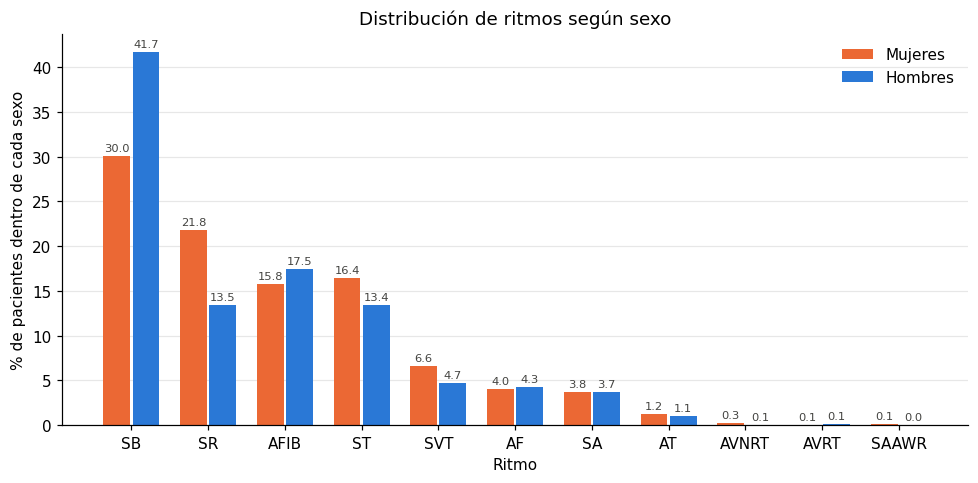

In [10]:
COLOR_SEXO = {"Mujeres": "#eb6834", "Hombres": "#2a78d6"}   # paleta apta para daltonismo

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(pct_sexo))     # una posición por ritmo
w = 0.38                         # ancho de cada barra

for i, sexo in enumerate(["Mujeres", "Hombres"]):
    barras = ax.bar(x + (i - 0.5) * w, pct_sexo[sexo], width=w - 0.03,
                    color=COLOR_SEXO[sexo], label=sexo)
    ax.bar_label(barras, fmt="%.1f", fontsize=7.5, padding=2, color="#444441")

ax.set_xticks(x, pct_sexo.index)
ax.set_ylabel("% de pacientes dentro de cada sexo")
ax.set_xlabel("Ritmo")
ax.set_title("Distribución de ritmos según sexo")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [11]:
# Se excluyen los ritmos con muy pocos casos para cumplir el supuesto de chi-cuadrado
RITMOS_RAROS = ["AVNRT", "AVRT", "SAAWR"]
tabla_global = tabla_sexo.drop(index=RITMOS_RAROS)

chi2, p, gl, esperados = chi2_contingency(tabla_global)

# V de Cramér: tamaño del efecto (0 = sin asociación, 1 = asociación perfecta)
n = tabla_global.values.sum()
v_cramer = np.sqrt(chi2 / (n * (min(tabla_global.shape) - 1)))

print(f"Chi-cuadrado = {chi2:.2f}, gl = {gl}, p = {p:.2e}")
print(f"Celdas con frecuencia esperada < 5: {(esperados < 5).sum()}")
print(f"V de Cramér = {v_cramer:.3f}")

Chi-cuadrado = 242.81, gl = 7, p = 9.38e-49
Celdas con frecuencia esperada < 5: 0
V de Cramér = 0.151


In [12]:
filas = []
k = len(orden_ritmos)   # número de pruebas (11) para la corrección de Bonferroni

for ritmo in orden_ritmos:
    # Tabla 2x2: ¿tiene este ritmo? (sí/no) vs sexo
    es_ritmo = diag["Rhythm"] == ritmo
    t2 = pd.crosstab(es_ritmo, diag["Gender"])[["FEMALE", "MALE"]]

    _, p_chi, _, esp = chi2_contingency(t2)
    if esp.min() < 5:                                   # pocos casos -> prueba exacta de Fisher
        prueba, p_val = "Fisher", fisher_exact(t2.values)[1]
    else:
        prueba, p_val = "Chi-cuadrado", p_chi

    filas.append({"Ritmo": ritmo,
                  "% mujeres": pct_sexo.loc[ritmo, "Mujeres"],
                  "% hombres": pct_sexo.loc[ritmo, "Hombres"],
                  "Prueba": prueba,
                  "p": p_val,
                  "p Bonferroni": min(p_val * k, 1.0)})

pruebas_sexo = pd.DataFrame(filas).set_index("Ritmo")
pruebas_sexo["Mayor en"] = np.where(pruebas_sexo["% mujeres"] > pruebas_sexo["% hombres"],
                                    "Mujeres", "Hombres")
pruebas_sexo["¿Significativo?"] = np.where(pruebas_sexo["p Bonferroni"] < 0.05, "Sí", "No")
pruebas_sexo.style.format({"p": "{:.2e}", "p Bonferroni": "{:.2e}"})

,% mujeres,% hombres,Prueba,p,p Bonferroni,Mayor en,¿Significativo?
Ritmo,,,,,,,
SB,30.020000,41.660000,Chi-cuadrado,4.51e-35,4.96e-34,Hombres,Sí
SR,21.830000,13.470000,Chi-cuadrado,7.82e-30,8.60e-29,Mujeres,Sí
AFIB,15.760000,17.480000,Chi-cuadrado,1.95e-02,2.14e-01,Hombres,No
ST,16.400000,13.420000,Chi-cuadrado,1.85e-05,2.04e-04,Mujeres,Sí
SVT,6.570000,4.680000,Chi-cuadrado,2.88e-05,3.17e-04,Mujeres,Sí
AF,4.010000,4.310000,Chi-cuadrado,4.62e-01,1.00e+00,Hombres,No
SA,3.750000,3.740000,Chi-cuadrado,1.00e+00,1.00e+00,Mujeres,No
AT,1.220000,1.070000,Chi-cuadrado,5.56e-01,1.00e+00,Mujeres,No
AVNRT,0.260000,0.070000,Chi-cuadrado,2.49e-02,2.74e-01,Mujeres,No


### Interpretación

- **Sí existe asociación entre ritmo y sexo** (χ² = 242,8; gl = 7; p < 0,001), aunque el tamaño del efecto es pequeño (V de Cramér = 0,15) [6]. La diferencia es real, pero el sexo por sí solo explica poco de qué ritmo tiene un paciente.
- **Más frecuente en hombres:** bradicardia sinusal (41,7 % vs. 30,0 %).
- **Más frecuentes en mujeres:** ritmo sinusal (21,8 % vs. 13,5 %), taquicardia sinusal (16,4 % vs. 13,4 %) y taquicardia supraventricular (6,6 % vs. 4,7 %).
- **Fibrilación auricular:** algo más frecuente en hombres (17,5 % vs. 15,8 %; p = 0,019 sin corregir), pero deja de ser significativa tras la corrección de Bonferroni. Como esta corrección es conservadora [7], el resultado debe leerse como una tendencia y no como ausencia de efecto.
- AVNRT, AVRT y SAAWR tienen tan pocos casos (16, 8 y 7) que no se puede concluir nada.

**Comparación con la literatura.** Bernal y Moro [8] reportan que las mujeres tienen una frecuencia cardíaca en reposo de 3 a 5 lpm mayor que los hombres, presente a todas las edades y no explicada solo por el tono autonómico. Esto es consistente con que la bradicardia sinusal sea más común en hombres y la taquicardia sinusal en mujeres en esta base. Los mismos autores describen que la taquicardia por reentrada nodal, el tipo más común de taquicardia supraventricular, es unas dos veces más frecuente en mujeres [8], lo que concuerda con el mayor porcentaje de SVT en mujeres. Por último, el estudio de Framingham encontró que la fibrilación auricular es cerca de 1,5 veces más común en hombres [9], lo que coincide con la tendencia observada.

**Limitación.** Los hombres de la base son en promedio unos 2 años mayores que las mujeres (60,1 vs. 58,1 años). Como la edad también influye en el ritmo, parte de la diferencia podría deberse a la edad y no al sexo. Esto se revisa en la sección 2.3.

## 2.3 ¿Hay arritmias más prevalentes para una edad?

*Con el fin de identificar qué arritmias predominan en cada etapa de la vida, se analizó la relación entre la edad y el ritmo.*

Se analiza la relación entre edad y ritmo desde dos ángulos:

1. **Edad dentro de cada ritmo.** Se describe la edad de los pacientes de cada ritmo (media, desviación estándar, mediana y rango intercuartílico) y se compara entre ritmos. La edad tiene una distribución asimétrica (cola hacia las edades bajas), así que se usa la prueba no paramétrica de **Kruskal-Wallis** [10], que compara rangos en lugar de medias y no supone normalidad. H₀: la distribución de edad es la misma en todos los ritmos. Como medida de tamaño del efecto se reporta **épsilon cuadrado** (ε²), que indica qué fracción de la variabilidad de los rangos de edad se explica por el ritmo [11]. Se excluyen AVNRT, AVRT y SAAWR por tener muy pocos casos.
2. **Ritmo dentro de cada grupo de edad.** Se agrupan los pacientes por décadas, con los mismos cortes que reportan Zheng et al. [4], y se calcula el porcentaje de cada ritmo dentro de cada grupo. La asociación se evalúa con chi-cuadrado de independencia; se acepta que hasta el 20 % de las celdas tenga frecuencia esperada menor que 5, siempre que ninguna sea menor que 1 [5].

In [13]:
# Grupos de edad: menores de edad aparte, y luego por décadas como en Zheng et al. [4]
CORTES    = [0, 17, 30, 40, 50, 60, 70, 80, 120]
ETIQUETAS = ["<18", "18–30", "31–40", "41–50", "51–60", "61–70", "71–80", ">80"]
diag["GrupoEdad"] = pd.cut(diag["PatientAge"], bins=CORTES, labels=ETIQUETAS)
# pd.cut usa intervalos (a, b]: por ejemplo, (50, 60] = de 51 a 60 años

frec_edad = diag["GrupoEdad"].value_counts().reindex(ETIQUETAS).to_frame("n")
frec_edad["%"] = (100 * frec_edad["n"] / len(diag)).round(2)

print(f"Asimetría de la edad: {skew(diag['PatientAge']):.2f}")
frec_edad

Asimetría de la edad: -0.61


,n,%
GrupoEdad,,
<18,265,2.49
18–30,635,5.96
31–40,690,6.48
41–50,1368,12.85
51–60,2110,19.82
61–70,2596,24.38
71–80,1799,16.90
>80,1183,11.11


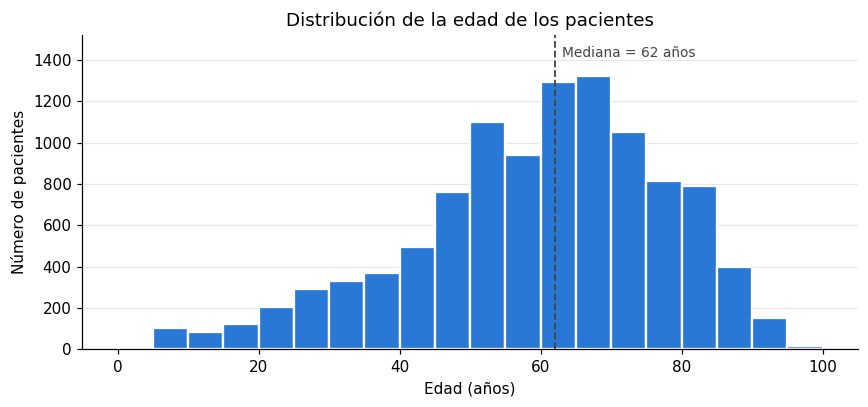

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.8))
conteos, _, _ = ax.hist(diag["PatientAge"], bins=range(0, 101, 5),
                        color="#2a78d6", edgecolor="white", linewidth=1.5)

mediana = diag["PatientAge"].median()
ax.axvline(mediana, color="#444441", ls="--", lw=1.2)
ax.set_ylim(0, conteos.max() * 1.15)                  # espacio arriba para la etiqueta
ax.text(mediana + 1, conteos.max() * 1.07, f"Mediana = {mediana:.0f} años",
        fontsize=9, color="#444441")

ax.set_xlabel("Edad (años)"); ax.set_ylabel("Número de pacientes")
ax.set_title("Distribución de la edad de los pacientes")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [15]:
desc_edad = (diag.groupby("Rhythm")["PatientAge"]
             .agg(n="count", media="mean", DE="std", mediana="median",
                  Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75),
                  mín="min", máx="max")
             .loc[orden_ritmos].round(1))
desc_edad

,n,media,DE,mediana,Q1,Q3,mín,máx
Rhythm,,,,,,,,
SB,3889,58.3,14.0,60.0,50.0,68.0,10,98
SR,1826,54.4,16.3,55.0,44.0,66.0,4,95
AFIB,1780,73.4,11.1,75.0,67.0,82.0,30,98
ST,1568,54.6,21.1,57.0,40.0,70.0,4,96
SVT,587,55.6,18.5,56.0,42.0,69.0,4,96
AF,445,71.1,13.5,72.0,63.0,81.0,21,97
SA,399,34.7,23.0,29.0,14.5,52.5,4,93
AT,121,65.7,19.3,71.0,60.0,77.0,8,94
AVNRT,16,57.9,17.3,59.0,51.0,66.0,27,84


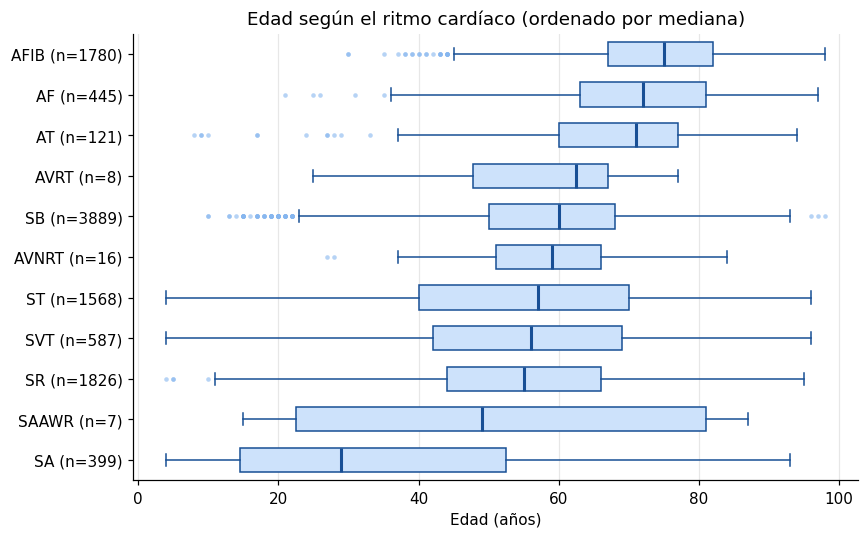

In [16]:
# Ordenar los ritmos por mediana de edad para que el patrón se vea claro
orden_mediana = diag.groupby("Rhythm")["PatientAge"].median().sort_values().index
datos_box = [diag.loc[diag["Rhythm"] == r, "PatientAge"] for r in orden_mediana]
etiq_box  = [f"{r} (n={len(d)})" for r, d in zip(orden_mediana, datos_box)]

fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot(datos_box, vert=False, widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor="#184f95"),
           medianprops=dict(color="#184f95", lw=2),
           whiskerprops=dict(color="#184f95"), capprops=dict(color="#184f95"),
           flierprops=dict(marker="o", markersize=3, markerfacecolor="#86b6ef",
                           markeredgecolor="none", alpha=0.6))
ax.set_yticks(range(1, len(etiq_box) + 1), etiq_box)
ax.set_xlabel("Edad (años)")
ax.set_title("Edad según el ritmo cardíaco (ordenado por mediana)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()

In [17]:
RITMOS_RAROS = ["AVNRT", "AVRT", "SAAWR"]
ritmos_test  = [r for r in orden_ritmos if r not in RITMOS_RAROS]
grupos_edad  = [diag.loc[diag["Rhythm"] == r, "PatientAge"] for r in ritmos_test]

H, p_kw = kruskal(*grupos_edad)
n_kw = sum(len(g) for g in grupos_edad)
epsilon2 = H / (n_kw - 1)        # épsilon cuadrado [11]

p_txt = "< 1e-300" if p_kw == 0 else f"= {p_kw:.2e}"   # p tan pequeño que Python lo redondea a 0
print(f"Kruskal-Wallis: H = {H:.2f}, gl = {len(grupos_edad) - 1}, p {p_txt}")
print(f"Épsilon cuadrado = {epsilon2:.3f}")

Kruskal-Wallis: H = 2221.95, gl = 7, p < 1e-300
Épsilon cuadrado = 0.209


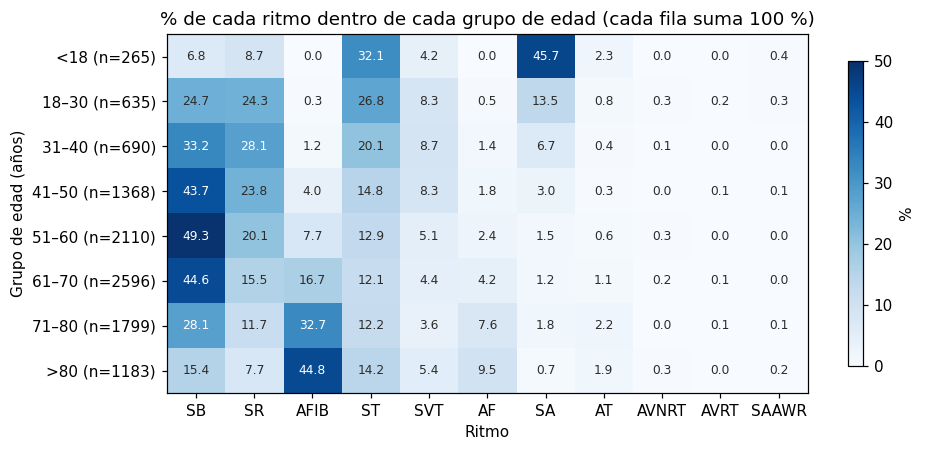

Chi-cuadrado = 3980.5, gl = 49, p < 1e-300
Celdas con esperado < 5: 1 de 64 (1.6 %); mínimo esperado = 3.01
V de Cramér = 0.231


In [18]:
tabla_edad = pd.crosstab(diag["GrupoEdad"], diag["Rhythm"])[list(orden_ritmos)]
pct_edad = 100 * tabla_edad.div(tabla_edad.sum(axis=1), axis=0)   # cada fila suma 100 %

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(pct_edad.values, cmap="Blues", aspect="auto", vmin=0, vmax=50)
for i in range(pct_edad.shape[0]):
    for j in range(pct_edad.shape[1]):
        v = pct_edad.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8,
                color="white" if v > 28 else "#2C2C2A")
ax.set_xticks(range(pct_edad.shape[1]), pct_edad.columns)
ax.set_yticks(range(pct_edad.shape[0]),
              [f"{g} (n={n})" for g, n in zip(pct_edad.index, tabla_edad.sum(axis=1))])
ax.set_xlabel("Ritmo"); ax.set_ylabel("Grupo de edad (años)")
ax.set_title("% de cada ritmo dentro de cada grupo de edad (cada fila suma 100 %)")
fig.colorbar(im, ax=ax, label="%", shrink=0.85)
plt.tight_layout(); plt.show()

# Chi-cuadrado sin los ritmos raros
tabla_edad_test = tabla_edad.drop(columns=RITMOS_RAROS)
chi2_e, p_e, gl_e, esp_e = chi2_contingency(tabla_edad_test)
v_e = np.sqrt(chi2_e / (tabla_edad_test.values.sum() * (min(tabla_edad_test.shape) - 1)))
p_txt = "< 1e-300" if p_e == 0 else f"= {p_e:.2e}"
print(f"Chi-cuadrado = {chi2_e:.1f}, gl = {gl_e}, p {p_txt}")
print(f"Celdas con esperado < 5: {(esp_e < 5).sum()} de {esp_e.size} "
      f"({100 * (esp_e < 5).mean():.1f} %); mínimo esperado = {esp_e.min():.2f}")
print(f"V de Cramér = {v_e:.3f}")

### Interpretación

- **La edad está claramente asociada al ritmo** (Kruskal-Wallis: H = 2222, gl = 7, p < 0,001; ε² = 0,21). El ritmo explica cerca del 21 % de la variabilidad en los rangos de edad, un efecto mayor que el del sexo (sección 2.2). El chi-cuadrado por grupos de edad lo confirma (χ² = 3980,5; gl = 49; p < 0,001; V de Cramér = 0,23); solo 1 de 64 celdas tiene frecuencia esperada menor que 5, lo que cumple el criterio de [5].
- **Arritmias de edades avanzadas:** la fibrilación auricular (mediana 75 años) y el flutter auricular (mediana 72 años) son las de mayor edad. La FA pasa de 0 % en menores de 18 años a 44,8 % en mayores de 80, donde es el ritmo más frecuente. La taquicardia auricular también se concentra en mayores (mediana 71 años).
- **Arritmia de edades jóvenes:** la irregularidad sinusal (SA) tiene la mediana más baja (29 años) y es el ritmo más frecuente en menores de 18 años (45,7 %).
- **Bradicardia sinusal:** predomina en la edad media; es el ritmo más frecuente entre los 41 y 70 años y alcanza el 49,3 % en el grupo de 51–60.
- **Taquicardia sinusal:** es el segundo ritmo más frecuente en menores de 18 años (32,1 %) y disminuye con la edad.

**Comparación con la literatura.** El aumento de la FA con la edad coincide con el estudio ATRIA, en el que la prevalencia de FA diagnosticada pasó de 0,1 % en menores de 55 años a 9,0 % en mayores de 80 [12]. Las prevalencias de esta base son mucho mayores porque se trata de pacientes hospitalarios a quienes se les indicó un ECG, no de población general. La alta frecuencia de irregularidad sinusal en jóvenes es esperable, porque la arritmia sinusal respiratoria es más marcada en niños y adultos jóvenes que en personas mayores [14].

**Hallazgo importante sobre los menores de 18 años.** En los niños la frecuencia cardíaca normal es más alta que en los adultos: por ejemplo, la mediana a los 2 años es de 113 lpm [13], que con criterios de adulto (más de 100 lpm) se clasificaría como taquicardia. El 32,1 % de "taquicardia sinusal" en menores de 18 años probablemente refleja frecuencias normales para su edad etiquetadas con umbrales de adulto, y no una arritmia real. Esto sugiere excluir a los menores de 18 años del subconjunto de trabajo (sección 2.4).

## 2.4 Selección del subconjunto de datos para entrenar algoritmos

Los algoritmos de aprendizaje necesitan la mayor cantidad posible de datos **comparables**, es decir, señales cuyas etiquetas signifiquen lo mismo para todos los pacientes y cuyas clases tengan suficientes ejemplos. Con base en el análisis descriptivo se toman tres decisiones:

**1. Rango de edad: 18 años o más.** Los diagnósticos de bradicardia sinusal (< 60 lpm) y taquicardia sinusal (> 100 lpm) se basan en umbrales de frecuencia cardíaca de adultos, pero la frecuencia normal en niños es más alta [13]. En la sección 2.3 se observó que el 32,1 % de los menores de 18 años tiene etiqueta de taquicardia sinusal, lo que probablemente refleja frecuencias normales para su edad y no una arritmia. Incluirlos introduciría etiquetas no comparables. No se fija un límite superior, porque los adultos mayores concentran la fibrilación auricular, que es una de las clases de mayor interés clínico. La relevancia de la edad también la reconocen Gadaleta et al. [1], quienes entrenan un modelo distinto por cada grupo de edad.

**2. Agrupación de ritmos.** Se sigue la agrupación de Zheng et al. [2], [4], que une ritmos clínicamente equivalentes o muy poco frecuentes:
- **SB:** bradicardia sinusal.
- **AFIB:** fibrilación auricular + flutter auricular (AF), que suelen coexistir y comparten tratamiento [2]. Liu et al. [3] también reportan que su modelo confunde con frecuencia estos dos ritmos.
- **GSVT:** taquicardia supraventricular + taquicardia auricular + AVNRT + AVRT + marcapasos auricular migratorio. Así se resuelve el problema de AVNRT, AVRT y SAAWR, que por separado tienen menos de 20 casos.
- **SR:** ritmo sinusal + irregularidad sinusal.

Las fuentes no indican en qué grupo va la **taquicardia sinusal (ST)**. De forma provisional se mantiene como un quinto grupo, en espera de confirmación del profesor. Este criterio se controla con el parámetro `ST_EN_GSVT`.

**3. Pacientes con condiciones cardíacas adicionales.** Zheng et al. [2] encontraron que condiciones como bloqueos de rama y extrasístoles reducen la exactitud de la clasificación. Sin embargo, excluirlas reduciría la base a la mitad y dejaría solo 500 casos de AFIB, porque la mayoría de pacientes con fibrilación tiene otras condiciones. Por eso se conservan todos los pacientes, y la columna `Beat` queda disponible para análisis de sensibilidad. Este criterio se controla con el parámetro `SOLO_SIN_CONDICIONES`.

In [19]:
# ---------------- PARÁMETROS DEL SUBCONJUNTO (modificar aquí) ----------------
EDAD_MINIMA          = 18      # provisional: pendiente de confirmar con el profesor
ST_EN_GSVT           = False   # provisional: ¿taquicardia sinusal dentro de GSVT o aparte?
SOLO_SIN_CONDICIONES = False   # True = solo pacientes con Beat == "NONE"
# -------------------------------------------------------------------------------

# Agrupación de ritmos según Zheng et al. [2], [4]
GRUPO_RITMO = {
    "SB": "SB",
    "AFIB": "AFIB", "AF": "AFIB",
    "SVT": "GSVT", "AT": "GSVT", "AVNRT": "GSVT", "AVRT": "GSVT", "SAAWR": "GSVT",
    "SR": "SR", "SA": "SR",
    "ST": "GSVT" if ST_EN_GSVT else "ST",
}
diag["Grupo"] = diag["Rhythm"].map(GRUPO_RITMO)

# Verificación: ningún ritmo debe quedar sin grupo
assert diag["Grupo"].notna().all(), "Hay ritmos sin grupo asignado"

# Aplicar filtros
filtro = diag["PatientAge"] >= EDAD_MINIMA
if SOLO_SIN_CONDICIONES:
    filtro &= diag["Beat"] == "NONE"
subconj = diag[filtro].copy()

print(f"Pacientes en la base completa: {len(diag)}")
print(f"Pacientes en el subconjunto:   {len(subconj)}  "
      f"({100 * len(subconj) / len(diag):.1f} %)")
print(f"Excluidos:                     {len(diag) - len(subconj)}")

Pacientes en la base completa: 10646
Pacientes en el subconjunto:   10381  (97.5 %)
Excluidos:                     265


In [20]:
ORDEN_GRUPOS = [g for g in ["SB", "SR", "AFIB", "GSVT", "ST"] if g in subconj["Grupo"].unique()]

resumen_grupos = pd.DataFrame({
    "n": subconj["Grupo"].value_counts(),
    "%": (100 * subconj["Grupo"].value_counts(normalize=True)).round(2),
    "n sin condiciones adicionales": subconj.loc[subconj["Beat"] == "NONE", "Grupo"].value_counts(),
    "Edad mediana": subconj.groupby("Grupo")["PatientAge"].median(),
    "% mujeres": (100 * subconj.groupby("Grupo")["Gender"]
                  .apply(lambda s: (s == "FEMALE").mean())).round(1),
}).loc[ORDEN_GRUPOS]
resumen_grupos

,n,%,n sin condiciones adicionales,Edad mediana,% mujeres
Grupo,,,,,
SB,3871,37.29,2188,60.0,36.2
SR,2081,20.05,1526,54.0,55.1
AFIB,2225,21.43,500,74.0,41.7
GSVT,721,6.95,405,59.0,51.6
ST,1483,14.29,585,59.0,48.9


### Respuesta: ¿qué rango de edades y arritmias usar para entrenar?

Se propone entrenar con **pacientes de 18 años o más** (10 381 pacientes, el 97,5 % de la base) y con **los ritmos agrupados según Zheng et al. [2], [4]**: SB, SR, AFIB, GSVT y, de forma provisional, ST como grupo independiente.

**Ventajas de esta selección:**
- Se eliminan etiquetas no comparables (frecuencias pediátricas evaluadas con umbrales de adulto) [13].
- Ninguna clase queda con muy pocos casos: la más pequeña (GSVT) tiene 721 pacientes, frente a los 7 a 16 que tenían AVNRT, AVRT o SAAWR por separado.
- La agrupación tiene sentido clínico y es la misma usada en la literatura sobre esta base, lo que permite comparar resultados [2].

**Limitaciones que hay que tener en cuenta:**
- **Desbalance de clases.** SB tiene 3871 pacientes y GSVT solo 721, más de 5 veces menos. Esto tiene tres implicaciones:
  1. **En un clasificador**, el modelo tiende a favorecer la clase mayoritaria: un modelo que dijera "SB" para todos los pacientes acertaría el 37 % de las veces sin haber aprendido nada. Por eso la exactitud global es engañosa, y conviene usar métricas como el F1 ponderado [2] o la sensibilidad por clase, además de técnicas como pesos por clase o remuestreo.
  2. **En la estadística descriptiva**, los grupos pequeños tienen estimaciones menos precisas (sus medianas y percentiles varían más de una muestra a otra), y los resúmenes globales de toda la base quedan dominados por los grupos grandes.
  3. **En las pruebas estadísticas**, la potencia para detectar diferencias es menor en las comparaciones que incluyen grupos pequeños. Por eso, en el punto 8 se usan pruebas basadas en rangos, que no exigen tamaños iguales, y se reporta el tamaño del efecto (δ de Cliff), que no depende del número de pacientes.
- **Confusión por edad:** los grupos tienen edades distintas (AFIB tiene una mediana de 74 años frente a 54 en SR). Al comparar características de las señales entre grupos (puntos 7 y 8), parte de las diferencias podría deberse a la edad y no a la arritmia. Este posible efecto se evalúa en la sección 8.8.
- **Condiciones adicionales:** cerca de la mitad de los pacientes tiene otras condiciones registradas en `Beat`, lo que puede alterar la morfología del ECG [2].

## 2.5 ¿Los resultados coinciden con lo reportado en la literatura?

*Con el fin de verificar que la base sea representativa y que los hallazgos sean consistentes con estudios previos, se compararon los resultados con la literatura.*

La comparación se hace en dos niveles:

1. **Con la fuente de los datos.** La base pública (10 646 pacientes) fue publicada por Zheng et al. [4] y proviene del mismo hospital que el conjunto de 40 258 pacientes analizado por Zheng et al. [2]. La Tabla 6 de [2] reporta, para cada ritmo, la frecuencia, la edad media ± DE y el número de hombres. Si la base pública es representativa, sus estadísticas por ritmo deberían parecerse a las de esa tabla.
2. **Con la epidemiología de las arritmias.** Se resume si las tendencias de sexo y edad encontradas en las secciones 2.2 y 2.3 coinciden con estudios de otras poblaciones.

En [2] algunos ritmos tienen otro nombre: flutter auricular = AFL (aquí `AF`), irregularidad sinusal = SI (aquí `SA`) y marcapasos auricular migratorio = WAP (aquí `SAAWR`).

In [21]:
# Valores copiados de la Tabla 6 de Zheng et al. [2]
ref_zheng = pd.DataFrame({
    "n":          [15528, 7291, 7028, 6208, 1725, 1773, 542, 133, 16, 7, 7],
    "Edad media": [58.40, 54.38, 73.07, 54.24, 71.57, 37.30, 55.44, 65.92, 57.88, 56.43, 51.14],
    "Edad DE":    [14.02, 16.17, 11.27, 21.41, 13.23, 22.98, 18.41, 18.70, 17.34, 17.89, 31.83],
    "n hombres":  [9844, 4107, 4051, 3208, 1001, 979, 289, 69, 12, 5, 6],
}, index=["SB", "SR", "AFIB", "ST", "AF", "SA", "SVT", "AT", "AVNRT", "AVRT", "SAAWR"])
ref_zheng["%"] = 100 * ref_zheng["n"] / ref_zheng["n"].sum()
ref_zheng["% hombres"] = 100 * ref_zheng["n hombres"] / ref_zheng["n"]

# Las mismas estadísticas calculadas con nuestra base
nuestro = diag.groupby("Rhythm").agg(
    n=("PatientAge", "size"),
    **{"Edad media": ("PatientAge", "mean"),
       "Edad DE":    ("PatientAge", "std"),
       "% hombres":  ("Gender", lambda s: 100 * (s == "MALE").mean())})
nuestro["%"] = 100 * nuestro["n"] / len(diag)
nuestro = nuestro.loc[ref_zheng.index]

# Tabla comparativa con las diferencias (esta base − referencia)
cols = ["%", "Edad media", "Edad DE", "% hombres"]
comparacion = pd.concat({"Esta base [4]": nuestro[cols],
                         "Zheng et al. [2]": ref_zheng[cols]}, axis=1)
for c in ["%", "Edad media", "% hombres"]:
    comparacion[("Diferencia", c)] = (comparacion[("Esta base [4]", c)]
                                      - comparacion[("Zheng et al. [2]", c)])
comparacion.round(2)

Esta base [4]                              Zheng et al. [2]             \
                  % Edad media Edad DE % hombres                % Edad media   
SB            36.53      58.34   13.95     63.80            38.57      58.40   
SR            17.15      54.35   16.33     43.92            18.11      54.38   
AFIB          16.72      73.36   11.14     58.48            17.46      73.07   
ST            14.73      54.57   21.06     50.96            15.42      54.24   
AF             4.18      71.07   13.50     57.75             4.28      71.57   
SA             3.75      34.75   23.03     55.89             4.40      37.30   
SVT            5.51      55.62   18.53     47.53             1.35      55.44   
AT             1.14      65.72   19.30     52.89             0.33      65.92   
AVNRT          0.15      57.88   17.34     25.00             0.04      57.88   
AVRT           0.08      57.50   16.84     62.50             0.02      56.43   
SAAWR          0.07      51.14   31.83     14.29             0.02      51.14   

                        Diferencia                       
      Edad DE % hombres          % Edad media % hombres  
SB      14.02     63.40      -2.04      -0.06      0.40  
SR      16.17     56.33      -0.96      -0.03    -12.41  
AFIB    11.27     57.64      -0.74       0.29      0.84  
ST      21.41     51.68      -0.69       0.33     -0.72  
AF      13.23     58.03      -0.10      -0.50     -0.28  
SA      22.98     55.22      -0.66      -2.55      0.67  
SVT     18.41     53.32       4.17       0.18     -5.79  
AT      18.70     51.88       0.81      -0.20      1.01  
AVNRT   17.34     75.00       0.11      -0.01    -50.00  
AVRT    17.89     71.43       0.06       1.07     -8.93  
SAAWR   31.83     85.71       0.05       0.00    -71.43

In [22]:
# El texto de [2] dice que hay 22 599 hombres. ¿Coincide con la suma de su propia tabla?
TOTAL_HOMBRES_REPORTADO = 22599
suma_tabla = ref_zheng["n hombres"].sum()
print(f"Total de hombres reportado en el texto de [2]:  {TOTAL_HOMBRES_REPORTADO}")
print(f"Suma de la columna de hombres de la Tabla 6:    {suma_tabla}")
print(f"Diferencia:                                      {suma_tabla - TOTAL_HOMBRES_REPORTADO}\n")

# Hipótesis: en algunos ritmos la tabla reporta mujeres en lugar de hombres
SOSPECHOSOS = ["SR", "SVT", "AVNRT", "SAAWR"]
corregido = ref_zheng["n hombres"].copy()
corregido[SOSPECHOSOS] = ref_zheng.loc[SOSPECHOSOS, "n"] - ref_zheng.loc[SOSPECHOSOS, "n hombres"]
print(f"Suma tras intercambiar hombres/mujeres en {SOSPECHOSOS}: {corregido.sum()}\n")

pd.DataFrame({
    "% hombres Tabla 6 [2]":   ref_zheng.loc[SOSPECHOSOS, "% hombres"],
    "% hombres corregido [2]": 100 * corregido[SOSPECHOSOS] / ref_zheng.loc[SOSPECHOSOS, "n"],
    "% hombres esta base [4]": nuestro.loc[SOSPECHOSOS, "% hombres"],
}).round(2)

Total de hombres reportado en el texto de [2]:  22599
Suma de la columna de hombres de la Tabla 6:    23571
Diferencia:                                      972

Suma tras intercambiar hombres/mujeres en ['SR', 'SVT', 'AVNRT', 'SAAWR']: 22599



,% hombres Tabla 6 [2],% hombres corregido [2],% hombres esta base [4]
SR,56.33,43.67,43.92
SVT,53.32,46.68,47.53
AVNRT,75.00,25.00,25.00
SAAWR,85.71,14.29,14.29


In [23]:
pct_grupos = 100 * diag["GrupoEdad"].value_counts(normalize=True)
pd.DataFrame({
    "Esta base":        pct_grupos[["51–60", "61–70", "71–80"]].round(2),
    "Zheng et al. [4]": [19.82, 24.38, 16.90],
    "Zheng et al. [2]": [19.8, 24.0, 17.3],
})

,Esta base,Zheng et al. [4],Zheng et al. [2]
GrupoEdad,,,
51–60,19.82,19.82,19.8
61–70,24.38,24.38,24.0
71–80,16.90,16.90,17.3


### Interpretación

**1. Coincidencia con la fuente de los datos.** Los resultados coinciden muy bien con lo reportado por los autores de la base:
- El número de hombres y mujeres (5956 y 4690) y los porcentajes de los grupos de edad más frecuentes (19,82 %, 24,38 % y 16,90 %) son idénticos a los de Zheng et al. [4].
- Frente al conjunto de 40 258 pacientes de [2], el orden de prevalencia de los ritmos es el mismo (SB > SR > AFIB > ST) y las edades medias por ritmo difieren menos de 1 año, salvo en la irregularidad sinusal (2,6 años). La base pública es, por lo tanto, representativa del conjunto más grande.

**2. Error detectado en la Tabla 6 de [2].** Los porcentajes de hombres de SR, SVT, AVNRT y WAP en esa tabla parecen contradecir los de esta base. Para AVNRT y WAP se trata de los mismos pacientes (mismo n, misma edad media y misma DE), pero los porcentajes son complementarios (75 % vs. 25 %; 85,71 % vs. 14,29 %). La propia tabla de [2] es inconsistente: su columna de hombres suma 23 571, mientras que el texto reporta 22 599 hombres. Si en esos cuatro ritmos se intercambian hombres y mujeres, la suma da exactamente 22 599, y los porcentajes corregidos coinciden con los de esta base (por ejemplo, SR: 43,67 % vs. 43,92 %). Se concluye que el error está en la tabla publicada y no en el archivo `Diagnostics.xlsx`. Esto respalda los resultados de la sección 2.2: el ritmo sinusal y la taquicardia supraventricular sí son más frecuentes en mujeres.

**3. Diferencia no explicada en SVT.** La base pública tiene 587 casos de SVT (5,5 %), más que los 542 (1,3 %) del conjunto de 40 258 pacientes, lo que no sería posible si fuera un subconjunto exacto. Algo similar ocurre con AVRT (8 vs. 7). Una posible explicación es que algunas etiquetas se revisaron entre una publicación y otra. Esto no afecta el análisis, porque SVT queda dentro del grupo GSVT.

**4. Coincidencia con la epidemiología.**

| Hallazgo en esta base | Literatura | ¿Coincide? |
|---|---|---|
| SB más frecuente en hombres; ST y SR más frecuentes en mujeres | Las mujeres tienen una frecuencia cardíaca en reposo de 3 a 5 lpm mayor que los hombres [8] | Sí |
| SVT más frecuente en mujeres | La taquicardia por reentrada nodal es cerca de 2 veces más frecuente en mujeres [8] | Sí |
| AFIB algo más frecuente en hombres (tendencia, no significativa tras Bonferroni) | La FA es cerca de 1,5 veces más común en hombres [9] | Parcialmente |
| AFIB aumenta con la edad (0 % en < 18 años, 44,8 % en > 80 años) | La prevalencia de FA pasa de 0,1 % en < 55 años a 9,0 % en ≥ 80 años [12] | Sí (tendencia) |
| SA es la arritmia de menor edad (mediana 29 años) | La arritmia sinusal respiratoria es más marcada en niños y adultos jóvenes [14] | Sí |
| 32,1 % de "taquicardia sinusal" en < 18 años | La frecuencia cardíaca normal en niños es mayor que en adultos [13] | Sí (explica el hallazgo) |

Las **tendencias** coinciden con la literatura, pero las **prevalencias absolutas** son mucho mayores. Por ejemplo, 16,7 % de FA en esta base frente a 0,95 % en la población general de ATRIA [12]. Esto se debe a que se trata de pacientes de un hospital a quienes se les indicó un ECG, es decir, una población con mayor probabilidad de tener enfermedad cardíaca, y no de una muestra de la población general. Por eso los porcentajes de esta base no deben usarse como estimaciones de prevalencia poblacional.

## 2.6 ¿Qué otros análisis se proponen desde la base de datos?

Se desarrollan dos análisis que responden a limitaciones encontradas en las secciones anteriores y que son útiles para los puntos siguientes del proyecto. Al final se listan otras propuestas.

### 2.6.1 Consistencia entre la etiqueta del ritmo y la frecuencia cardíaca

*Con el fin de evaluar la calidad de las etiquetas diagnósticas, se comparó cada ritmo con la frecuencia cardíaca medida por el equipo.*

Las etiquetas de la base fueron asignadas por médicos [4]. Una forma sencilla de evaluar su calidad es comparar el ritmo etiquetado con la frecuencia ventricular medida por el electrocardiógrafo (`VentricularRate`). Por definición clásica, la bradicardia sinusal tiene menos de 60 lpm, la taquicardia sinusal más de 100 lpm [15] y el ritmo sinusal normal entre 60 y 100 lpm. Si las etiquetas son coherentes, casi todos los pacientes de cada ritmo deberían caer en el rango esperado.

Este análisis también es importante para el punto 4: la frecuencia de máxima potencia del ECG debería estar relacionada con la frecuencia cardíaca, por lo que la columna `VentricularRate` servirá luego como referencia para validar ese cálculo.

In [24]:
def clasificar_fc(fc):
    """Clasifica una frecuencia cardíaca (lpm) en tres rangos clínicos."""
    if fc < 60:
        return "< 60 lpm"
    if fc <= 100:
        return "60–100 lpm"
    return "> 100 lpm"

subconj["RangoFC"] = subconj["VentricularRate"].apply(clasificar_fc)

# % de pacientes de cada ritmo en cada rango (cada fila suma 100 %)
consist = pd.crosstab(subconj["Rhythm"], subconj["RangoFC"], normalize="index") * 100
consist = consist[["< 60 lpm", "60–100 lpm", "> 100 lpm"]].round(1)
consist.insert(0, "FC mediana (lpm)", subconj.groupby("Rhythm")["VentricularRate"].median())
consist.insert(0, "n", subconj["Rhythm"].value_counts())
display(consist.sort_values("FC mediana (lpm)"))

# % de bradicardias que cumplen el umbral más estricto de la guía de 2018 (< 50 lpm) [16]
sb = subconj.loc[subconj["Rhythm"] == "SB", "VentricularRate"]
print(f"SB con FC < 60 lpm: {100 * (sb < 60).mean():.1f} %")
print(f"SB con FC < 50 lpm: {100 * (sb < 50).mean():.1f} %")

RangoFC,n,FC mediana (lpm),< 60 lpm,60–100 lpm,> 100 lpm
Rhythm,,,,,
SB,3871,56.0,99.5,0.5,0.0
SAAWR,6,64.5,33.3,66.7,0.0
SA,278,70.0,3.2,96.4,0.4
SR,1803,74.0,0.1,99.8,0.1
AFIB,1780,91.0,5.2,59.9,34.9
ST,1483,108.0,0.1,0.1,99.7
AT,115,113.0,2.6,26.1,71.3
AF,445,115.0,3.6,33.0,63.4
AVRT,8,161.5,0.0,0.0,100.0


SB con FC < 60 lpm: 99.5 %
SB con FC < 50 lpm: 9.4 %


**Interpretación.** Las etiquetas son muy coherentes con la frecuencia cardíaca: el 99,5 % de las bradicardias sinusales tiene menos de 60 lpm, el 99,7 % de las taquicardias sinusales más de 100 lpm y el 99,8 % de los ritmos sinusales entre 60 y 100 lpm. Las taquicardias supraventriculares (SVT, AVNRT, AVRT) tienen todas más de 100 lpm, con medianas entre 160 y 175 lpm, como se espera de ritmos por reentrada [15]. Esto da confianza en la calidad de las etiquetas de [4].

En la fibrilación y el flutter auricular la frecuencia es muy variable (60 % y 33 % entre 60 y 100 lpm, respectivamente), porque estas arritmias se definen por la **actividad auricular** (ausencia de onda P, ondas f o F) y no por la frecuencia ventricular, que depende de la conducción por el nodo AV [15]. Por eso, para distinguir estas arritmias no basta con la frecuencia cardíaca, y se necesitan características de la forma o del espectro de la señal, como las que se calculan en los puntos 3 a 5.

**Observación sobre el umbral de bradicardia.** La base usa el umbral clásico de 60 lpm. Sin embargo, la guía de 2018 de ACC/AHA/HRS define la bradicardia sinusal como una frecuencia menor de 50 lpm [16], y con ese criterio solo el 9,4 % de los casos etiquetados como SB lo serían. Muchos de estos pacientes (frecuencia entre 50 y 59 lpm) probablemente no tienen una alteración clínicamente relevante, lo que puede explicar por qué SB es el ritmo "anormal" más frecuente de la base (sección 2.1).

### 2.6.2 ¿Las diferencias por sexo se mantienen al controlar por la edad?

*Con el fin de determinar si las diferencias por sexo se deben realmente al sexo y no a la edad, se repitió el análisis ajustando por edad.*

En la sección 2.2 se encontraron diferencias por sexo, pero se señaló una limitación: los hombres de la base son en promedio unos 2 años mayores, y la edad está fuertemente asociada al ritmo (sección 2.3). Para separar el efecto del sexo del de la edad se estratifica por grupo de edad y se aplica la **prueba de Cochran-Mantel-Haenszel (CMH)** [5], [17]. Esta prueba compara hombres y mujeres **dentro de cada grupo de edad** y combina los resultados en una sola prueba. H₀: dentro de cada grupo de edad, el sexo no está asociado al ritmo.

Como medida de efecto se usa la **razón de odds (OR)** de tener el ritmo en hombres frente a mujeres:
- OR > 1: el ritmo es más frecuente en hombres.
- OR < 1: el ritmo es más frecuente en mujeres.
- OR = 1: no hay diferencia.

Se compara el OR **crudo** (sin ajustar) con el OR **ajustado por edad** (estimador de Mantel-Haenszel). Si son parecidos, la diferencia por sexo no se debe a la edad. Se usa el subconjunto de 18 años o más con los grupos definidos en la sección 2.4, y se corrige por Bonferroni (5 pruebas) [7].

Para cada grupo de edad *k* se arma una tabla 2 × 2:

|  | Tiene el ritmo | No lo tiene |
|---|---|---|
| Hombres | a | b |
| Mujeres | c | d |

- OR ajustado: $OR_{MH} = \dfrac{\sum_k a_k d_k / n_k}{\sum_k b_k c_k / n_k}$
- Estadístico: $\chi^2_{MH} = \dfrac{\left(\left|\sum_k (a_k - E[a_k])\right| - 0{,}5\right)^2}{\sum_k \mathrm{Var}(a_k)}$, con 1 grado de libertad, donde
  - $E[a_k] = \dfrac{(a_k+b_k)(a_k+c_k)}{n_k}$
  - $\mathrm{Var}(a_k) = \dfrac{(a_k+b_k)(c_k+d_k)(a_k+c_k)(b_k+d_k)}{n_k^2(n_k-1)}$

In [25]:
def tabla_2x2(df, grupo):
    """Devuelve (a, b, c, d) de la tabla 2x2 sexo vs. tener el grupo de ritmo."""
    hombre = df["Gender"] == "MALE"
    tiene  = df["Grupo"] == grupo
    a = ( hombre &  tiene).sum()     # hombres con el ritmo
    b = ( hombre & ~tiene).sum()     # hombres sin el ritmo
    c = (~hombre &  tiene).sum()     # mujeres con el ritmo
    d = (~hombre & ~tiene).sum()     # mujeres sin el ritmo
    return a, b, c, d

def mantel_haenszel(df, grupo, estrato="GrupoEdad"):
    """OR ajustado de Mantel-Haenszel y prueba CMH con corrección de continuidad [5], [17]."""
    num_or = den_or = suma_a_menos_E = suma_var = 0.0
    for _, d_k in df.groupby(estrato, observed=True):
        a, b, c, d = tabla_2x2(d_k, grupo)
        n = a + b + c + d
        num_or += a * d / n
        den_or += b * c / n
        suma_a_menos_E += a - (a + b) * (a + c) / n
        suma_var += (a + b) * (c + d) * (a + c) * (b + d) / (n**2 * (n - 1))
    chi2_mh = (abs(suma_a_menos_E) - 0.5) ** 2 / suma_var
    return num_or / den_or, chi2_mh, dist_chi2.sf(chi2_mh, df=1)

def or_crudo(df, grupo):
    a, b, c, d = tabla_2x2(df, grupo)
    return (a * d) / (b * c)

# Quitar del subconjunto la categoría vacía "<18"
subconj["GrupoEdad"] = subconj["GrupoEdad"].cat.remove_unused_categories()

filas = []
for g in ORDEN_GRUPOS:
    or_mh, chi2_mh, p_mh = mantel_haenszel(subconj, g)
    filas.append({"Grupo": g,
                  "OR crudo": or_crudo(subconj, g),
                  "OR ajustado por edad": or_mh,
                  "χ² MH": chi2_mh,
                  "p": p_mh,
                  "p Bonferroni": min(p_mh * len(ORDEN_GRUPOS), 1.0)})

mh = pd.DataFrame(filas).set_index("Grupo")
mh["Más frecuente en"] = np.where(mh["OR ajustado por edad"] > 1, "Hombres", "Mujeres")
mh["¿Significativo?"] = np.where(mh["p Bonferroni"] < 0.05, "Sí", "No")
mh.style.format({"OR crudo": "{:.2f}", "OR ajustado por edad": "{:.2f}", "χ² MH": "{:.1f}",
                 "p": "{:.2e}", "p Bonferroni": "{:.2e}"})

,OR crudo,OR ajustado por edad,χ² MH,p,p Bonferroni,Más frecuente en,¿Significativo?
Grupo,,,,,,,
SB,1.67,1.76,172.3,2.33e-39,1.17e-38,Hombres,Sí
SR,0.57,0.60,104.9,1.28e-24,6.40e-24,Mujeres,Sí
AFIB,1.13,1.01,0.0,8.46e-01,1.00e+00,Hombres,No
GSVT,0.72,0.74,15.3,9.19e-05,4.59e-04,Mujeres,Sí
ST,0.80,0.82,12.2,4.75e-04,2.37e-03,Mujeres,Sí


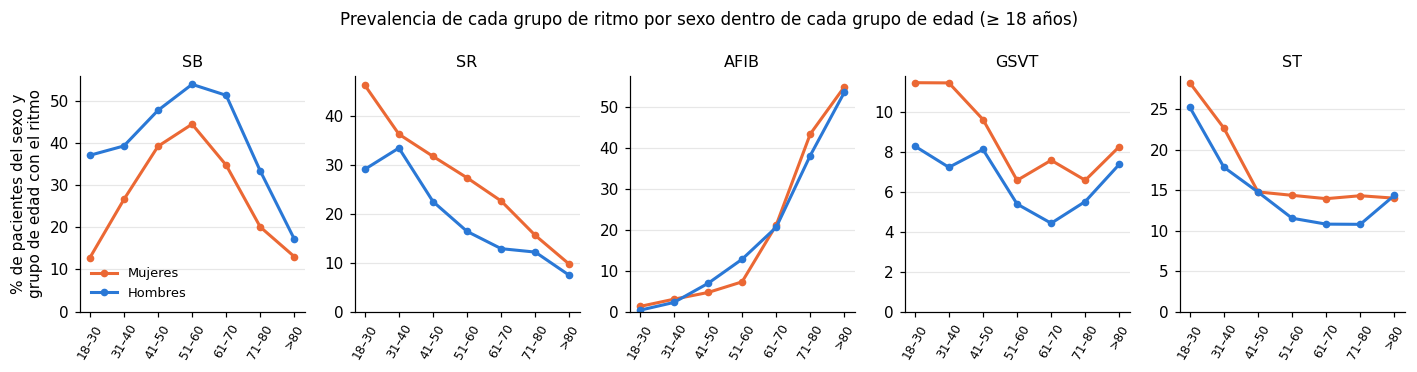

In [26]:
COLOR_SEXO = {"FEMALE": "#eb6834", "MALE": "#2a78d6"}
ETIQ_SEXO  = {"FEMALE": "Mujeres", "MALE": "Hombres"}

fig, axes = plt.subplots(1, len(ORDEN_GRUPOS), figsize=(13, 3.4))
for ax, g in zip(axes, ORDEN_GRUPOS):
    # % de pacientes con el ritmo, por grupo de edad y sexo
    pct = (subconj.assign(tiene=subconj["Grupo"] == g)
           .pivot_table(index="GrupoEdad", columns="Gender", values="tiene",
                        aggfunc="mean", observed=True) * 100)
    x = np.arange(len(pct))
    for sexo in ["FEMALE", "MALE"]:
        ax.plot(x, pct[sexo], marker="o", markersize=4, lw=2,
                color=COLOR_SEXO[sexo], label=ETIQ_SEXO[sexo])
    ax.set_title(g, fontsize=10.5)
    ax.set_xticks(x, pct.index, rotation=60, fontsize=8)
    ax.set_ylim(0, None)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

axes[0].set_ylabel("% de pacientes del sexo y\ngrupo de edad con el ritmo")
axes[0].legend(frameon=False, fontsize=8.5)
fig.suptitle("Prevalencia de cada grupo de ritmo por sexo dentro de cada grupo de edad (≥ 18 años)",
             fontsize=11)
plt.tight_layout(); plt.show()

**Interpretación.** Al controlar por la edad, las diferencias por sexo de la sección 2.2 se mantienen en SB, SR, GSVT y ST. Los OR ajustados son muy parecidos a los crudos, y en las gráficas la diferencia aparece en todos los grupos de edad. Por ejemplo, la bradicardia sinusal tiene un 76 % más de odds en hombres (OR ajustado = 1,76) y el ritmo sinusal es más frecuente en mujeres (OR ajustado = 0,60). Por lo tanto, estas diferencias no se deben a que los hombres de la base sean algo mayores.

La **fibrilación auricular** es la excepción. Su OR crudo (1,13) baja a 1,01 al ajustar por edad y deja de ser significativo (p = 0,85). La gráfica muestra que la FA es algo más frecuente en hombres entre los 41 y 60 años, pero en mujeres a partir de los 71 años. Esto coincide con lo descrito por Bernal y Moro [8], quienes señalan que las tasas de FA de ambos sexos convergen después de los 70 años. Como en la base hay muchos pacientes mayores, el efecto global del sexo se diluye.

### 2.6.3 Otros análisis propuestos

1. **Condiciones cardíacas adicionales (columna `Beat`).** Describir qué condiciones (bloqueos de rama, extrasístoles, hipertrofia, etc.) acompañan a cada ritmo y evaluar si alteran las características de la señal, ya que Zheng et al. [2] reportan que reducen la exactitud de la clasificación.
2. **Comparación de las mediciones del ECG entre ritmos** (duración del QRS, intervalo QT corregido, ejes eléctricos), para identificar qué variables clínicas ya disponibles distinguen mejor cada grupo.
3. **Validación del punto 4 con la frecuencia cardíaca.** Correlacionar la frecuencia de máxima potencia de cada señal con `VentricularRate`, para comprobar que el cálculo espectral tiene sentido fisiológico.
4. **Submuestra emparejada por edad y sexo.** Como los grupos difieren en edad (sección 2.4), comparar las características de las señales (puntos 7 y 8) en una submuestra en la que cada grupo tenga la misma distribución de edad y sexo, para que las diferencias encontradas se deban a la arritmia y no a la edad.
5. **Modelo de regresión logística multinomial** con edad, sexo y su interacción como predictores del grupo de ritmo, para cuantificar el efecto de cada variable en un solo modelo.

---
# 3. Biespectro: fórmulas 1 a 4

Kotriwar et al. [18] analizan ECG de 60 s mediante espectro de potencia y análisis espectral de orden superior (biespectro y bicoherencia). Antes de calcular los espectros, preprocesan la señal en dos pasos: eliminan la tendencia con un polinomio (fórmula 1) y llevan la amplitud al rango [0, 1] (fórmula 2). Luego calculan el biespectro (fórmula 3) y su versión normalizada, la bicoherencia (fórmula 4).

## 3.1 Lectura de las señales

Cada archivo de `ECGDataDenoised` contiene un registro de 10 s muestreado a 500 Hz (5000 muestras) con las 12 derivaciones en columnas, en microvoltios [4]. Los archivos **no tienen encabezado**, así que los nombres de las derivaciones se asignan al leerlos. El orden estándar se verifica con la ley de Einthoven, según la cual la derivación II es la suma de I y III.

Se trabaja con la **derivación II**, que es la usada habitualmente para analizar el ritmo y la que usan Zheng et al. [2] para extraer sus características. Para probar las fórmulas se usan dos registros de ejemplo: uno de ritmo sinusal (SR) y uno de fibrilación auricular (AFIB).

In [27]:
DERIVACIONES = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]

def cargar_ecg(nombre_archivo, carpeta=CARPETA_ECG):
    """Lee un registro (sin encabezado) y devuelve un DataFrame con las 12 derivaciones en µV."""
    ruta = os.path.join(carpeta, nombre_archivo + ".csv")
    return pd.read_csv(ruta, header=None, names=DERIVACIONES)

def cargar_derivacion(nombre_archivo, derivacion="II", carpeta=CARPETA_ECG):
    """Devuelve una sola derivación como arreglo de numpy."""
    return cargar_ecg(nombre_archivo, carpeta)[derivacion].to_numpy(dtype=float)

EJEMPLOS = {"SR": "MUSE_20180209_172046_21000", "AFIB": "MUSE_20180113_171327_27000"}

# Verificaciones sobre el registro SR
ecg_sr = cargar_ecg(EJEMPLOS["SR"])
print("Dimensiones:", ecg_sr.shape)
print("Duración:", len(ecg_sr) / FS, "s")
print("Valores faltantes:", ecg_sr.isna().sum().sum())

# Ley de Einthoven: II = I + III -> la correlación debe ser cercana a 1
I, II, III = ecg_sr["I"], ecg_sr["II"], ecg_sr["III"]
print(f"Correlación entre II e (I + III): {np.corrcoef(II, I + III)[0, 1]:.3f}")

# Datos clínicos de los dos ejemplos
display(diag.set_index("FileName").loc[list(EJEMPLOS.values()),
                                       ["Rhythm", "VentricularRate", "PatientAge", "Gender"]])

Dimensiones: (5000, 12)
Duración: 10.0 s
Valores faltantes: 0
Correlación entre II e (I + III): 0.994


,Rhythm,VentricularRate,PatientAge,Gender
FileName,,,,
MUSE_20180209_172046_21000,SR,63,46,MALE
MUSE_20180113_171327_27000,AFIB,117,85,MALE


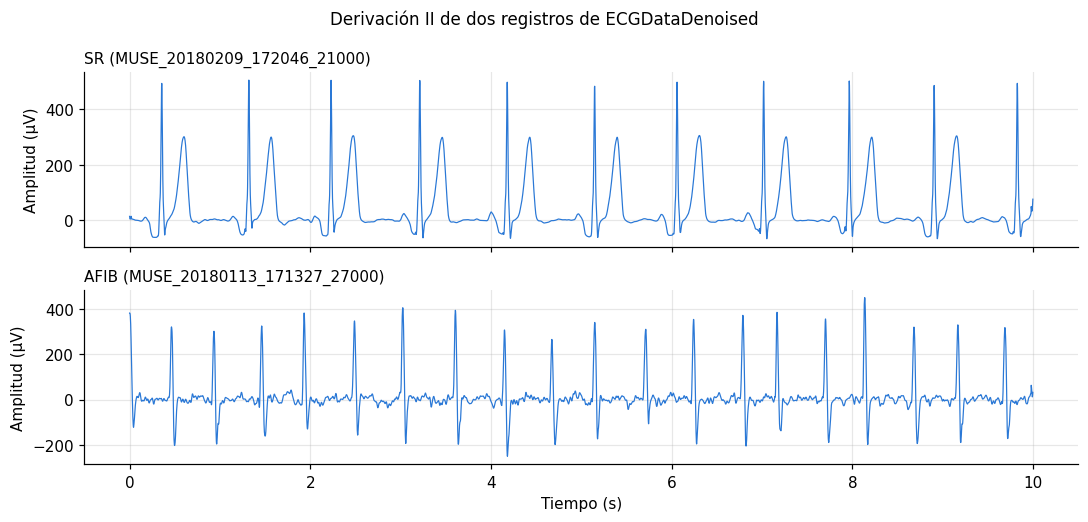

In [28]:
senales = {ritmo: cargar_derivacion(archivo) for ritmo, archivo in EJEMPLOS.items()}
t = np.arange(len(senales["SR"])) / FS     # eje de tiempo en segundos

fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
for ax, (ritmo, x) in zip(axes, senales.items()):
    ax.plot(t, x, color="#2a78d6", lw=0.8)
    ax.set_title(f"{ritmo} ({EJEMPLOS[ritmo]})", fontsize=10, loc="left")
    ax.set_ylabel("Amplitud (µV)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
axes[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Derivación II de dos registros de ECGDataDenoised", fontsize=11)
plt.tight_layout(); plt.show()

## 3.2 Fórmula 1: eliminación de la tendencia

Las señales de ECG pueden tener una tendencia lenta (deriva de la línea de base) causada por la respiración, el movimiento o el equipo de registro. Kotriwar et al. [18] la estiman ajustando un polinomio de grado *n* a la señal y restándolo. Para elegir el grado definen la **desviación** entre la señal original $x^{(0)}$ y la señal sin tendencia $x^{(n)}$:

$$\delta(n) = \frac{1}{k}\sum_{i=1}^{k}\left(x^{(0)}(i) - x^{(n)}(i)\right)^2 \tag{1}$$

donde *k* es el número de muestras. Como $x^{(0)} - x^{(n)}$ es la tendencia que se quitó, δ(n) es la potencia media de esa tendencia. Los autores reportan que δ(n) se estabiliza para *n* > 20 y por eso usan *n* = 20 [18].

**Detalle de implementación.** Ajustar un polinomio de grado 20 directamente sobre el índice de las muestras (0 a 4999) es numéricamente inestable: `np.polyfit` lanza la advertencia *"Polyfit may be poorly conditioned"*, porque eleva números como 4999 a la potencia 20. Por eso se usa `np.polynomial.Polynomial.fit`, que reescala internamente el eje al intervalo [−1, 1] antes de ajustar.

SR: δ(1) = 1511.2 µV²,  δ(20) = 1887.8 µV²,  δ(20)/δ(1) = 1.25
AFIB: δ(1) = 74.9 µV²,  δ(20) = 224.8 µV²,  δ(20)/δ(1) = 3.00


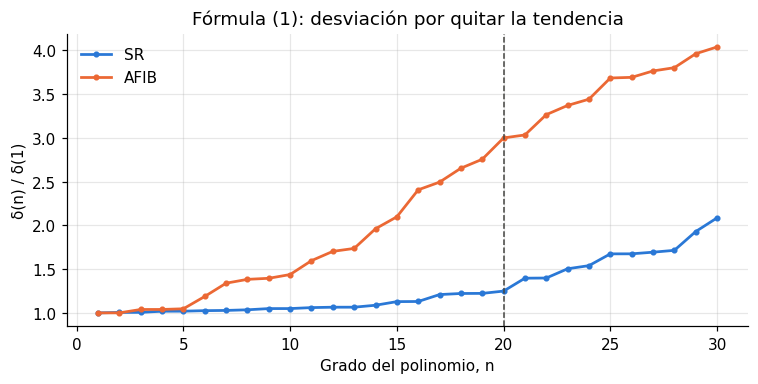

In [29]:
def quitar_tendencia(x, grado):
    """Ajusta un polinomio de grado `grado` y lo resta. Devuelve (señal sin tendencia, tendencia)."""
    t = np.arange(len(x))
    tendencia = np.polynomial.Polynomial.fit(t, x, deg=grado)(t)   # ajuste numéricamente estable
    return x - tendencia, tendencia

def desviacion_tendencia(x, grado):
    """Fórmula (1) de [18]: δ(n) = (1/k) Σ (x0(i) - xn(i))²."""
    x_n, _ = quitar_tendencia(x, grado)
    return np.mean((x - x_n) ** 2)

GRADOS = np.arange(1, 31)

fig, ax = plt.subplots(figsize=(7, 3.6))
for (ritmo, x), color in zip(senales.items(), ["#2a78d6", "#eb6834"]):
    d = np.array([desviacion_tendencia(x, n) for n in GRADOS])
    ax.plot(GRADOS, d / d[0], marker="o", markersize=3, lw=1.8, color=color, label=ritmo)
    print(f"{ritmo}: δ(1) = {d[0]:.1f} µV²,  δ(20) = {d[19]:.1f} µV²,  δ(20)/δ(1) = {d[19] / d[0]:.2f}")

ax.axvline(20, color="#444441", ls="--", lw=1)          # grado usado por [18]
ax.set_xlabel("Grado del polinomio, n"); ax.set_ylabel("δ(n) / δ(1)")
ax.set_title("Fórmula (1): desviación por quitar la tendencia")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

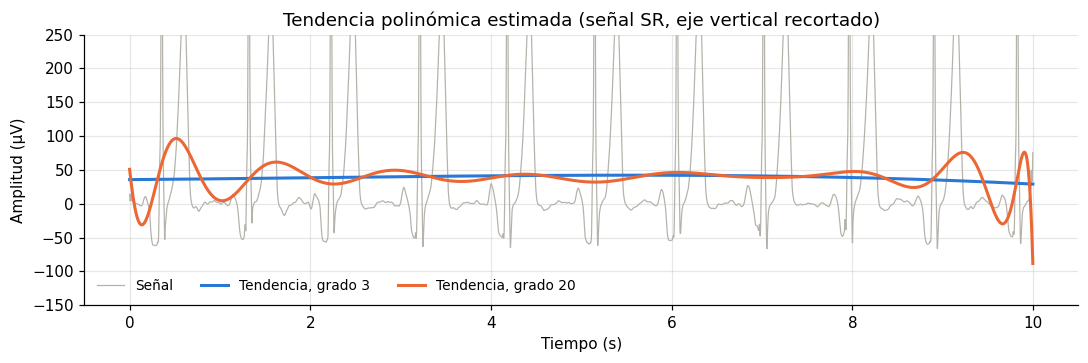

Grado  1: potencia conservada entre 0 y 2,5 Hz = 100.0 %
Grado  3: potencia conservada entre 0 y 2,5 Hz =  99.7 %
Grado  5: potencia conservada entre 0 y 2,5 Hz =  99.1 %
Grado 10: potencia conservada entre 0 y 2,5 Hz =  97.6 %
Grado 20: potencia conservada entre 0 y 2,5 Hz =  87.3 %


In [30]:
x = senales["SR"]

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t, x, color="#B4B2A9", lw=0.8, label="Señal")
for g, color in [(3, "#2a78d6"), (20, "#eb6834")]:
    _, tend = quitar_tendencia(x, g)
    ax.plot(t, tend, color=color, lw=2, label=f"Tendencia, grado {g}")
ax.set_ylim(-150, 250)                                     # recorte para ver la tendencia
ax.set_xlabel("Tiempo (s)"); ax.set_ylabel("Amplitud (µV)")
ax.set_title("Tendencia polinómica estimada (señal SR, eje vertical recortado)")
ax.legend(frameon=False, ncol=3, fontsize=9)
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Potencia de baja frecuencia (0–2,5 Hz, donde está la frecuencia cardíaca) que sobrevive
f = np.fft.rfftfreq(len(x), d=1 / FS)
banda = (f > 0) & (f < 2.5)
P_orig = np.abs(np.fft.rfft(x - x.mean())) ** 2
for g in [1, 3, 5, 10, 20]:
    x_n, _ = quitar_tendencia(x, g)
    P = np.abs(np.fft.rfft(x_n - x_n.mean())) ** 2
    print(f"Grado {g:2d}: potencia conservada entre 0 y 2,5 Hz = "
          f"{100 * P[banda].sum() / P_orig[banda].sum():5.1f} %")

**Interpretación.** En estas señales δ(n) no se estabiliza en *n* = 20, como reportan Kotriwar et al. [18], sino que sigue creciendo. Hay dos razones:

1. **Las señales ya no tienen deriva de línea de base.** Los archivos de `ECGDataDenoised` ya pasaron por un filtro Robust LOESS que elimina esa deriva [4]. Por eso, con grado bajo, δ(n) refleja casi solo el nivel medio de la señal. Por ejemplo, en el registro SR la media de la derivación II es ≈ 38,9 µV, y 38,9² ≈ 1513 µV² ≈ δ(1).
2. **Las señales son 6 veces más cortas.** Un polinomio de grado 20 sobre 10 s es mucho más flexible que sobre los 60 s usados en [18]. Puede oscilar lo suficiente como para seguir parte del propio ECG: su tendencia llega a ~0,8 Hz, muy cerca de la frecuencia cardíaca (~1 Hz). Al restarla se pierde el 12,7 % de la potencia entre 0 y 2,5 Hz y aparecen deformaciones en los bordes del registro. Es decir, el aumento de δ(n) con el grado no significa que se esté quitando más tendencia, sino que se está quitando señal.

**Decisión (provisional).** Se usa un polinomio de **grado 3**, que elimina el nivel medio y cualquier deriva lenta residual conservando el 99,7 % de la potencia de baja frecuencia. Esta elección se controla con el parámetro `GRADO_TENDENCIA`.

## 3.3 Fórmula 2: compresión de la amplitud

Para comparar señales de distintos pacientes sin que influya la amplitud absoluta (que depende, por ejemplo, de la contextura del paciente o de la posición de los electrodos), Kotriwar et al. [18] llevan cada señal al rango [0, 1] mediante una normalización mínimo-máximo:

$$c(t_k) = \frac{x(t_k) - x_{\min}}{x_{\max} - x_{\min}} \tag{2}$$

donde $x_{\min}$ y $x_{\max}$ son el mínimo y el máximo de la señal sin tendencia. En el artículo, el lado izquierdo aparece como $s(t_k)$ y el numerador como $c(t_k)$, aunque el texto define $c(t_k)$ como la señal comprimida; aquí se escribe la forma coherente con el texto. Es la misma normalización que usan Zheng et al. [2] para reducir la variabilidad de amplitud entre personas.

SR: mínimo = 0.000, máximo = 1.000, media = 0.187
AFIB: mínimo = 0.000, máximo = 1.000, media = 0.369


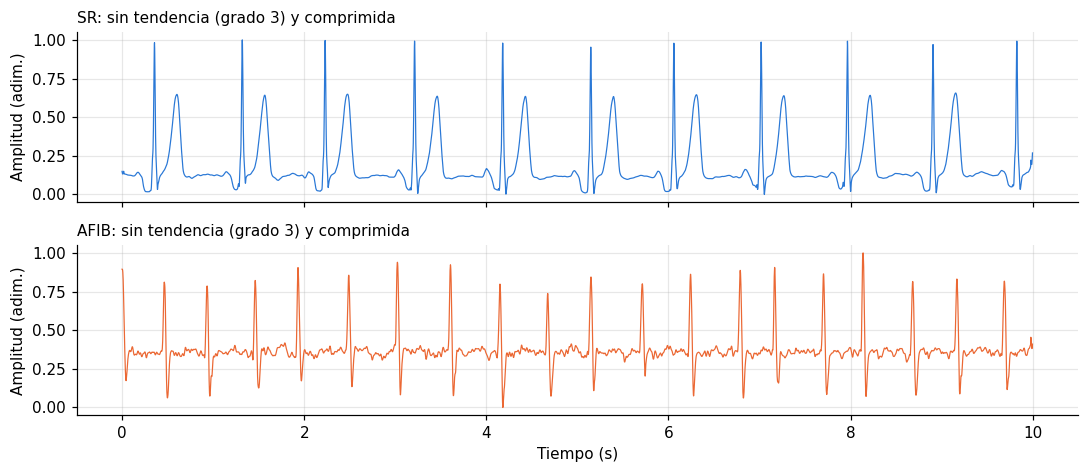

In [31]:
GRADO_TENDENCIA = 3      # provisional; el artículo usa 20 (ver sección 3.2)

def compresion(x):
    """Fórmula (2) de [18]: normalización mínimo-máximo al rango [0, 1]."""
    return (x - x.min()) / (x.max() - x.min())

def preprocesar(x, grado=GRADO_TENDENCIA):
    """Preprocesamiento de [18]: quitar tendencia (fórmula 1) y comprimir (fórmula 2)."""
    x_n, _ = quitar_tendencia(x, grado)
    return compresion(x_n)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.4), sharex=True)
for ax, (ritmo, x), color in zip(axes, senales.items(), ["#2a78d6", "#eb6834"]):
    s = preprocesar(x)
    ax.plot(t, s, color=color, lw=0.8)
    ax.set_title(f"{ritmo}: sin tendencia (grado {GRADO_TENDENCIA}) y comprimida", fontsize=10, loc="left")
    ax.set_ylabel("Amplitud (adim.)"); ax.set_ylim(-0.05, 1.05)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
    print(f"{ritmo}: mínimo = {s.min():.3f}, máximo = {s.max():.3f}, media = {s.mean():.3f}")
axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

## 3.4 Fórmulas 3 y 4: biespectro y bicoherencia

El espectro de potencia indica cuánta energía hay en cada frecuencia, pero descarta la información de fase. El **biespectro** es un espectro de tercer orden que conserva la fase: mide si tres componentes de frecuencia $f_1$, $f_2$ y $f_1 + f_2$ están **acoplados en fase**, es decir, si la fase de $f_1 + f_2$ es igual a la suma de las fases de $f_1$ y $f_2$ de forma sistemática [19]. Kotriwar et al. [18] lo estiman dividiendo la señal en *N* segmentos, calculando la transformada de Fourier $X_j(f)$ de cada uno y promediando el triple producto:

$$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2) \tag{3}$$

donde $^*$ es el conjugado complejo. Si en cada segmento la fase del triple producto es la misma (fases acopladas), los términos se suman en la misma dirección y $|b|$ es grande. Si la fase cambia al azar de un segmento a otro, los términos se cancelan.

Como $|b|$ depende de la amplitud de la señal, se normaliza para obtener la **bicoherencia**, que va de 0 (sin acoplamiento) a 1 (acoplamiento perfecto) [18]:

$$B(f_1, f_2) = \frac{\left|\sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)\right|}{\sum_{j=1}^{N} \left|X_j(f_1)\,X_j(f_2)\,X_j^*(f_1 + f_2)\right|} \tag{4}$$

**Detalles de implementación:**
- **Región de cálculo.** Por las simetrías del biespectro de una señal real, basta calcularlo en el triángulo $f_2 > 0$, $f_1 \ge f_2$, $f_1 + f_2 \le f_{\max}$ [18], [19]. Siguiendo a [18], se usa $f_{\max}$ = 20 Hz, porque allí está casi toda la potencia del ECG.
- **Segmentos.** El artículo usa segmentos de 8192 muestras sobre señales de 60 s [18], pero aquí las señales tienen solo 5000 muestras. Se usan segmentos de 500 muestras (1 s), con lo que *N* = 10 y la resolución en frecuencia es $\Delta f = f_s / L$ = 1 Hz. Con un solo segmento, la fórmula (4) da siempre 1, porque el numerador y el denominador son iguales.
- **Umbral de significancia.** Un valor de bicoherencia se considera significativo si supera $\sqrt{9.2/(2N)}$, que corresponde al nivel de 99 % para bicoherencia nula [21]. El artículo lo describe como "80 %" [18], pero el umbral de 80 % sería $\sqrt{3.2/(2N)}$ [21].

In [32]:
LONG_SEGMENTO = 500     # muestras por segmento (1 s) -> N = 10, resolución 1 Hz (provisional)
FMAX_BIS      = 20.0    # frecuencia máxima analizada (Hz), como en [18]

def segmentar(x, L):
    """Divide la señal en N segmentos consecutivos de L muestras (descarta el sobrante)."""
    N = len(x) // L
    return x[:N * L].reshape(N, L)

def biespectro_bicoherencia(x, fs=FS, L=LONG_SEGMENTO, fmax=FMAX_BIS):
    """
    Fórmulas (3) y (4) de [18].
    Devuelve: f (frecuencias, Hz), b (biespectro complejo), B (bicoherencia), N (segmentos).
    b[i, j] y B[i, j] corresponden al par (f1 = f[i], f2 = f[j]); fuera de la región válida valen NaN.
    """
    segmentos = segmentar(np.asarray(x, dtype=float), L)
    N = segmentos.shape[0]

    X = np.fft.rfft(segmentos, axis=1)          # transformada de cada segmento: matriz N x (L/2 + 1)
    f = np.fft.rfftfreq(L, d=1 / fs)            # frecuencias correspondientes: 0, 1, 2, ... Hz

    K = int(round(fmax * L / fs)) + 1           # número de frecuencias entre 0 y fmax
    idx = np.arange(K)
    idx_suma = idx[:, None] + idx[None, :]      # índice de f1 + f2 para cada par (i, j)

    # Triple producto X(f1)·X(f2)·X*(f1+f2) para todos los pares y segmentos: arreglo N x K x K
    producto = X[:, :K, None] * X[:, None, :K] * np.conj(X[:, idx_suma])

    b = producto.sum(axis=0)                            # fórmula (3): suma sobre los segmentos
    B = np.abs(b) / np.abs(producto).sum(axis=0)        # fórmula (4)

    # Conservar solo la región triangular: f2 > 0, f1 >= f2, f1 + f2 <= fmax
    f = f[:K]
    F1, F2 = np.meshgrid(f, f, indexing="ij")
    region = (F2 > 0) & (F1 >= F2) & (F1 + F2 <= fmax)
    return f, np.where(region, b, np.nan), np.where(region, B, np.nan), N

def umbral_bicoherencia(N):
    """Umbral de significancia (99 %) para N segmentos [21]."""
    return np.sqrt(9.2 / (2 * N))

print(f"Segmento = {LONG_SEGMENTO} muestras ({LONG_SEGMENTO / FS:.1f} s) -> "
      f"N = {5000 // LONG_SEGMENTO}, Δf = {FS / LONG_SEGMENTO:.1f} Hz, "
      f"umbral = {umbral_bicoherencia(5000 // LONG_SEGMENTO):.3f}")

Segmento = 500 muestras (1.0 s) -> N = 10, Δf = 1.0 Hz, umbral = 0.678


### Validación con señales sintéticas

*Con el fin de comprobar que el código calcula correctamente la bicoherencia antes de aplicarlo al ECG, se probó con señales cuyo resultado se conoce.*

Antes de aplicar las fórmulas al ECG se comprueba que funcionen en un caso cuya respuesta se conoce. Se construyen señales con tres cosenos de 3 Hz, 7 Hz y 10 Hz (= 3 + 7), cuyas fases cambian al azar de un segmento a otro:
- **Fases acopladas:** la fase de 10 Hz es siempre la suma de las fases de 3 y 7 Hz, como ocurre cuando un sistema no lineal cuadrático genera la componente de 10 Hz. La bicoherencia en (7, 3) debe ser cercana a 1.
- **Fases no acopladas:** la fase de 10 Hz es independiente. Las tres frecuencias tienen la misma potencia que antes, pero la bicoherencia debe ser baja.

Esta prueba muestra la diferencia entre el espectro de potencia (idéntico en los dos casos) y la bicoherencia (que distingue ambos casos). También se evalúa con ruido blanco puro qué fracción de pares supera el umbral sin que exista ningún acoplamiento.

In [33]:
rng = np.random.default_rng(seed=0)      # semilla fija para que los resultados sean reproducibles
N_PRUEBA, f1_p, f2_p = 10, 7.0, 3.0
t_seg = np.arange(LONG_SEGMENTO) / FS

def senal_sintetica(acoplada):
    partes = []
    for _ in range(N_PRUEBA):                               # un segmento a la vez
        fase1, fase2, fase3 = rng.uniform(0, 2 * np.pi, size=3)
        if acoplada:
            fase3 = fase1 + fase2                           # acoplamiento cuadrático de fase
        partes.append(np.cos(2 * np.pi * f1_p * t_seg + fase1)
                      + np.cos(2 * np.pi * f2_p * t_seg + fase2)
                      + np.cos(2 * np.pi * (f1_p + f2_p) * t_seg + fase3))
    x = np.concatenate(partes)
    return x + 0.5 * rng.standard_normal(len(x))            # se agrega ruido

for acoplada in [True, False]:
    f, b, B, N = biespectro_bicoherencia(senal_sintetica(acoplada))
    i1, i2 = np.argmin(np.abs(f - f1_p)), np.argmin(np.abs(f - f2_p))
    estado = "acopladas   " if acoplada else "no acopladas"
    print(f"Fases {estado}: B(7 Hz, 3 Hz) = {B[i1, i2]:.3f}   |b| = {np.abs(b[i1, i2]):.0f}   "
          f"(umbral = {umbral_bicoherencia(N):.3f})")

Fases acopladas   : B(7 Hz, 3 Hz) = 0.999   |b| = 154333808   (umbral = 0.678)
Fases no acopladas: B(7 Hz, 3 Hz) = 0.132   |b| = 20240683   (umbral = 0.678)


In [34]:
REPETICIONES = 300
tasas = []
for _ in range(REPETICIONES):
    ruido = rng.standard_normal(N_PRUEBA * LONG_SEGMENTO)
    _, _, B_r, N = biespectro_bicoherencia(ruido)
    valores = B_r[~np.isnan(B_r)]
    tasas.append(np.mean(valores > umbral_bicoherencia(N)))

print(f"Pares por señal: {valores.size}")
print(f"Ruido blanco: {100 * np.mean(tasas):.1f} % de los pares supera el umbral (se esperaría ~1 %)")

Pares por señal: 100
Ruido blanco: 6.2 % de los pares supera el umbral (se esperaría ~1 %)


SR: N = 10 segmentos, resolución = 1.0 Hz, umbral = 0.678
      pares en la región = 100, pares significativos = 92 (92 %)
      máximo de |b| en (f1, f2) = (1 Hz, 1 Hz)
AFIB: N = 10 segmentos, resolución = 1.0 Hz, umbral = 0.678
      pares en la región = 100, pares significativos = 61 (61 %)
      máximo de |b| en (f1, f2) = (9 Hz, 4 Hz)


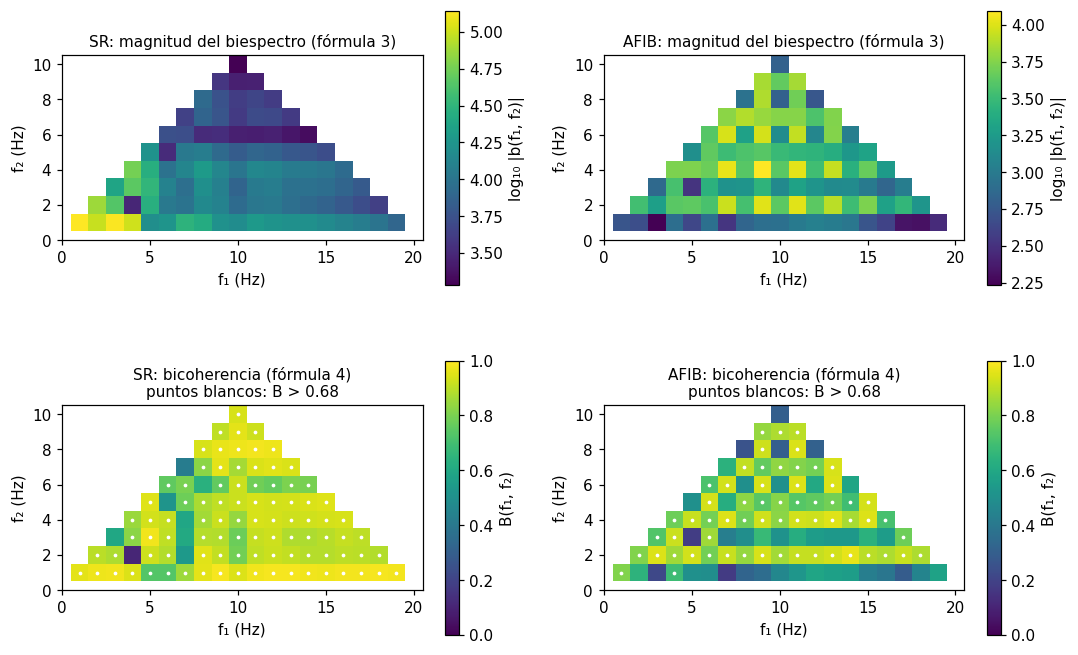

In [35]:
resultados = {}
for ritmo, x in senales.items():
    s = preprocesar(x)                                   # fórmulas (1) y (2)
    f, b, B, N = biespectro_bicoherencia(s)              # fórmulas (3) y (4)
    resultados[ritmo] = (f, b, B, N)

    valores = B[~np.isnan(B)]
    u = umbral_bicoherencia(N)
    i, j = np.unravel_index(np.nanargmax(np.abs(b)), b.shape)
    print(f"{ritmo}: N = {N} segmentos, resolución = {FS / LONG_SEGMENTO:.1f} Hz, umbral = {u:.3f}")
    print(f"      pares en la región = {valores.size}, pares significativos = {(valores > u).sum()} "
          f"({100 * np.mean(valores > u):.0f} %)")
    print(f"      máximo de |b| en (f1, f2) = ({f[i]:.0f} Hz, {f[j]:.0f} Hz)")

# Mapas: fila superior = |b| (fórmula 3), fila inferior = B (fórmula 4)
fig, axes = plt.subplots(2, 2, figsize=(10, 6.6))
extent = [f[0] - 0.5, f[-1] + 0.5, f[0] - 0.5, f[-1] + 0.5]
F1, F2 = np.meshgrid(f, f, indexing="ij")
for col, ritmo in enumerate(resultados):
    f, b, B, N = resultados[ritmo]

    ax = axes[0, col]
    im = ax.imshow(np.log10(np.abs(b)).T, origin="lower", extent=extent, cmap="viridis", aspect="equal")
    fig.colorbar(im, ax=ax, shrink=0.8, label="log₁₀ |b(f₁, f₂)|")
    ax.set_title(f"{ritmo}: magnitud del biespectro (fórmula 3)", fontsize=10)

    ax = axes[1, col]
    im = ax.imshow(B.T, origin="lower", extent=extent, cmap="viridis", vmin=0, vmax=1, aspect="equal")
    sig = B > umbral_bicoherencia(N)
    ax.scatter(F1[sig], F2[sig], s=6, c="white", linewidths=0)      # pares significativos
    fig.colorbar(im, ax=ax, shrink=0.8, label="B(f₁, f₂)")
    ax.set_title(f"{ritmo}: bicoherencia (fórmula 4)\npuntos blancos: B > {umbral_bicoherencia(N):.2f}",
                 fontsize=10)

for ax in axes.flat:
    ax.set_xlabel("f₁ (Hz)"); ax.set_ylabel("f₂ (Hz)")
    ax.set_xlim(0, 20.5); ax.set_ylim(0, 10.5)
plt.tight_layout(); plt.show()

### Interpretación

**Validación.** Con señales sintéticas, la bicoherencia vale 0,999 cuando las fases están acopladas y 0,132 cuando no lo están, aunque en ambos casos la potencia en cada frecuencia es la misma. Esto confirma que las fórmulas (3) y (4) están bien implementadas y que la bicoherencia detecta algo que el espectro de potencia no puede ver: la relación de fase entre frecuencias.

**Registro SR (63 lpm ≈ 1,05 Hz).** El máximo del biespectro está en (1 Hz, 1 Hz), la frecuencia del pulso, y **todos** los pares de la fila $f_2$ = 1 Hz son significativos. Es decir, la frecuencia del pulso está acoplada en fase con prácticamente todas sus armónicas hasta 20 Hz. Esto concuerda con lo que reportan Kotriwar et al. [18] para sujetos sanos. La explicación es que un latido regular es una forma de onda que se repite: sus componentes de Fourier son armónicas de $f_0$ con relaciones de fase fijas, determinadas por la forma del complejo P-QRS-T. Además, el biespectro no cambia si la señal se desplaza en el tiempo, porque un retardo τ multiplica el triple producto por $e^{-j2\pi(f_1+f_2-f_1-f_2)\tau} = 1$. Por eso no importa en qué momento del latido empieza cada segmento [19].

**Registro AFIB (117 lpm ≈ 1,95 Hz).** El porcentaje de pares significativos baja de 92 % a 61 %, y el máximo del biespectro se desplaza a frecuencias más altas, (9 Hz, 4 Hz), donde está la energía de los complejos QRS. La fila de 1 Hz casi no tiene pares significativos (3 de 19), pero la de 2 Hz, que corresponde a la frecuencia ventricular de este paciente, sí está acoplada (17 de 19). Esto sugiere que el acoplamiento depende de la frecuencia del pulso de cada paciente, que en la FA es más alta y además irregular, por lo que el acoplamiento se reparte de forma menos ordenada. Con solo dos señales esto es una observación, no una conclusión; la comparación entre grupos se hará en los puntos 7 y 8.

**Limitaciones de la estimación con señales de 10 s:**
- **Resolución de 1 Hz.** Frecuencias de pulso de 63 y 80 lpm (1,05 y 1,33 Hz) caen en la misma casilla de 1 Hz. Para mejorar la resolución habría que usar segmentos más largos, pero eso reduce *N* y vuelve el umbral mayor que 1 (con *N* ≤ 4 nada puede ser significativo).
- **Falsos positivos.** Con ruido blanco puro, el 6,2 % de los pares supera el umbral, y no el 1 % esperado. Esto ocurre porque el umbral $\sqrt{9.2/(2N)}$ fue derivado para la normalización clásica de Kim y Powers [20], [21], mientras que la fórmula (4) normaliza de otra manera. Por lo tanto, parte de los pares "significativos" pueden serlo por azar, y los conteos del punto 5 deben compararse entre grupos, no interpretarse en valor absoluto.

## 3.5 Significado y utilidad del biespectro

**Qué es.** El espectro de potencia es la transformada de Fourier de la autocorrelación (un estadístico de segundo orden). Describe completamente a una señal gaussiana y lineal, pero pierde toda la información de fase. El **biespectro** es la transformada de Fourier bidimensional del cumulante de tercer orden de la señal [19]:

$$B(f_1, f_2) = E\left[X(f_1)\,X(f_2)\,X^*(f_1 + f_2)\right]$$

y su versión normalizada, la **bicoherencia**, toma valores entre 0 y 1 e indica qué fracción de la energía en el par de frecuencias está acoplada en fase [18], [20].

**Qué significa un valor alto.** Indica **acoplamiento cuadrático de fase**: la componente de frecuencia $f_1 + f_2$ no es independiente, sino que se genera a partir de $f_1$ y $f_2$ por una interacción no lineal. En un sistema lineal las frecuencias no interactúan entre sí, por lo que su biespectro es nulo [19], [20].

**Propiedades útiles:**
1. **Es nulo para procesos gaussianos**, así que en teoría suprime el ruido aditivo gaussiano y permite detectar señales no gaussianas inmersas en ruido [19].
2. **Conserva la información de fase** que el espectro de potencia pierde [19].
3. **No cambia al desplazar la señal en el tiempo**, por lo que no requiere alinear los latidos.
4. **Detecta no linealidad:** permite saber si una componente espectral es una armónica generada por el sistema o una oscilación independiente.

**Utilidad en ingeniería biomédica:**
- **ECG:** el biespectro y la bicoherencia permiten describir la estructura no lineal del latido y su pérdida en condiciones patológicas. Kotriwar et al. [18] encuentran que en sujetos sanos la frecuencia del pulso está acoplada con muchas frecuencias más altas, y que este acoplamiento disminuye en pacientes con enfermedades cardíacas. Revisan además trabajos que usan características biespectrales de la variabilidad de la frecuencia cardíaca para clasificar arritmias.
- **EEG:** el análisis biespectral es la base de índices de profundidad anestésica, que usan la bicoherencia del EEG para estimar el nivel de sedación [22].
- **En este proyecto:** el número de pares con bicoherencia significativa (punto 5) se usará como una característica que resume cuán regular y "ordenada" es la estructura armónica de cada ECG, para comparar entre arritmias.

---
# 4. Frecuencia de máxima potencia (fMP)

*Con el fin de identificar la componente de frecuencia dominante de cada ECG y relacionarla con la frecuencia cardíaca, se calculó la fMP.*

Kotriwar et al. [18] calculan el espectro de potencia de cada señal con la FFT y extraen la frecuencia con la máxima potencia, a la que llaman *main peak frequency*. Excluyen las frecuencias menores de 0,3 Hz para evitar artefactos de la deriva de la línea de base. Reportan que en sujetos sanos esta frecuencia está alrededor de 1 Hz, es decir, coincide con la frecuencia del pulso, mientras que en pacientes la potencia en la frecuencia del pulso disminuye y se redistribuye hacia frecuencias más altas, de hasta 4–5 Hz [18].

**¿Por qué el pulso aparece en el espectro?** Un ECG con ritmo regular es una forma de onda que se repite cada $T = 60/\text{FC}$ segundos. Su espectro es un "peine" de picos en la frecuencia del pulso $f_0 = 1/T$ y en sus múltiplos $2f_0, 3f_0, \dots$ (armónicas). La altura de cada pico depende de la forma del complejo P-QRS-T. Si el ritmo es irregular, los picos se ensanchan y el peine se desordena.

## 4.1 Cálculo correcto del espectro

Con un registro de 10 s, la FFT calcula el espectro en una rejilla de frecuencias separadas $\Delta f = 1/10\ \text{s} = 0{,}1$ Hz. Si la frecuencia de un pico cae **entre** dos puntos de la rejilla, la FFT subestima su altura (efecto de *scalloping* o "valla de estacas"). En el peor caso, a mitad de camino entre dos puntos, solo registra el $(2/\pi)^2 \approx 40{,}5\ \%$ de su potencia real [23]. Esto puede hacer que un pico más pequeño, que por casualidad cae justo sobre la rejilla, parezca el máximo.

Para evitarlo se combinan dos técnicas:
1. **Ventana de Hann:** multiplica la señal por una campana que la lleva suavemente a cero en los extremos. Así reduce la fuga de energía hacia frecuencias vecinas y la pérdida en el peor caso, de 3,92 dB (rectangular) a 1,42 dB [23].
2. **Relleno con ceros (×8):** se agregan ceros al final de la señal antes de la FFT, con lo que el espectro se calcula cada 0,0125 Hz en lugar de cada 0,1 Hz. No mejora la resolución real (dos picos separados menos de ~0,1 Hz siguen sin distinguirse), pero **interpola** el espectro y permite encontrar la altura y la posición reales de cada pico.

Como la compresión (fórmula 2) solo cambia la escala y el polinomio de grado 3 casi no altera las bajas frecuencias, la fMP se calcula sobre la señal preprocesada, igual que en [18].

**Límite superior de búsqueda.** La fMP se busca entre 0,3 y 40 Hz. El límite superior excluye la interferencia de la red eléctrica (50 Hz en China) [2], que quedó como residuo en algunas señales a pesar del filtrado de la base. En 9 de 10 605 registros (0,08 %) el máximo absoluto del espectro estaba en ~50 Hz. Con el límite, en el registro de flutter auricular `MUSE_20180712_153749_14000`, por ejemplo, la fMP pasa de 49,96 Hz a 2,18 Hz, prácticamente su frecuencia cardíaca (2,23 Hz).

In [36]:
FMIN_FMP = 0.3      # Hz: se excluye la deriva de la línea de base [18]
FMAX_FMP = 40.0     # Hz: se excluye la interferencia de la red eléctrica (50 Hz) [2]
RELLENO  = 8        # factor de relleno con ceros

def espectro_potencia(x, fs=FS, ventana=True, relleno=RELLENO):
    """Espectro de potencia normalizado (máximo = 1), con ventana de Hann y relleno con ceros."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    w = np.hanning(len(x)) if ventana else np.ones(len(x))
    nfft = relleno * len(x)
    P = np.abs(np.fft.rfft(x * w, n=nfft)) ** 2
    f = np.fft.rfftfreq(nfft, d=1 / fs)
    return f, P / P.max()

def frecuencia_max_potencia(x, fs=FS, fmin=FMIN_FMP, fmax=FMAX_FMP, ventana=True, relleno=RELLENO):
    """Punto 4: frecuencia (Hz) con la máxima potencia entre fmin y fmax."""
    f, P = espectro_potencia(x, fs, ventana, relleno)
    valido = (f >= fmin) & (f <= fmax)
    return f[valido][np.argmax(P[valido])]

In [37]:
# Frecuencia cardíaca medida por el electrocardiógrafo, en Hz, como referencia
fc_ref = diag.set_index("FileName")["VentricularRate"]

filas = []
for ritmo, x in senales.items():
    s = preprocesar(x)
    fila = {"Ritmo": ritmo, "FC del equipo (Hz)": fc_ref[EJEMPLOS[ritmo]] / 60}
    for ventana, relleno, nombre in [(False, 1, "FFT directa"),
                                     (True,  1, "Hann"),
                                     (False, 8, "Relleno ×8"),
                                     (True,  8, "Hann + relleno ×8")]:
        fila[nombre] = frecuencia_max_potencia(s, ventana=ventana, relleno=relleno)
    filas.append(fila)

comp_fmp = pd.DataFrame(filas).set_index("Ritmo").round(3)
comp_fmp

,FC del equipo (Hz),FFT directa,Hann,Relleno ×8,Hann + relleno ×8
Ritmo,,,,,
SR,1.05,4.2,1.0,1.05,1.050
AFIB,1.95,9.0,9.0,9.00,9.013


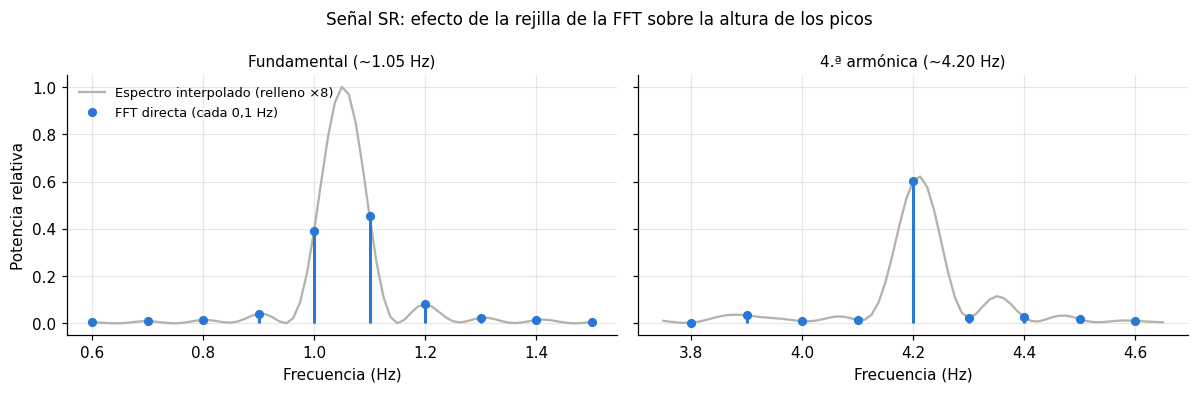

FFT directa en 1.0 Hz: potencia relativa = 0.391
FFT directa en 1.1 Hz: potencia relativa = 0.453
FFT directa en 4.2 Hz: potencia relativa = 0.602


In [38]:
x = preprocesar(senales["SR"])
x = x - x.mean()

# Mismo espectro (ventana rectangular) en la rejilla de 0,1 Hz y en una rejilla 8 veces más fina
P_d = np.abs(np.fft.rfft(x)) ** 2
f_d = np.fft.rfftfreq(len(x), d=1 / FS)
P_i = np.abs(np.fft.rfft(x, n=8 * len(x))) ** 2
f_i = np.fft.rfftfreq(8 * len(x), d=1 / FS)
ref = P_i.max()                       # misma escala para ambos
f0 = fc_ref[EJEMPLOS["SR"]] / 60

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (a, b) in zip(axes, [(0.6, 1.5), (3.75, 4.65)]):
    m_i = (f_i >= a) & (f_i <= b)
    m_d = (f_d >= a - 1e-9) & (f_d <= b + 1e-9)
    ax.plot(f_i[m_i], P_i[m_i] / ref, color="#B4B2A9", lw=1.5,
            label="Espectro interpolado (relleno ×8)")
    ax.vlines(f_d[m_d], 0, P_d[m_d] / ref, color="#2a78d6", lw=2)
    ax.plot(f_d[m_d], P_d[m_d] / ref, "o", color="#2a78d6", markersize=5,
            label="FFT directa (cada 0,1 Hz)")
    ax.set_xlabel("Frecuencia (Hz)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
axes[0].set_title(f"Fundamental (~{f0:.2f} Hz)", fontsize=10)
axes[1].set_title(f"4.ª armónica (~{4 * f0:.2f} Hz)", fontsize=10)
axes[0].set_ylabel("Potencia relativa")
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle("Señal SR: efecto de la rejilla de la FFT sobre la altura de los picos", fontsize=11)
plt.tight_layout(); plt.show()

for fx in [1.0, 1.1, 4.2]:
    print(f"FFT directa en {fx:.1f} Hz: potencia relativa = {P_d[np.argmin(np.abs(f_d - fx))] / ref:.3f}")

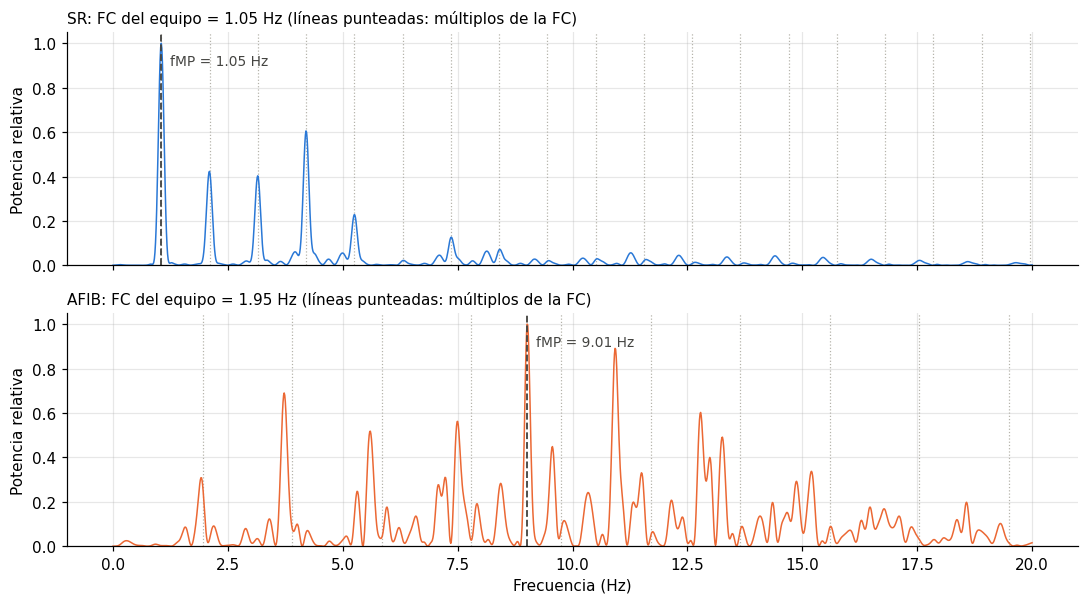

SR: fMP = 1.050 Hz
AFIB: fMP = 9.013 Hz


In [39]:
fig, axes = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True)
for ax, (ritmo, x), color in zip(axes, senales.items(), ["#2a78d6", "#eb6834"]):
    s = preprocesar(x)
    f, P = espectro_potencia(s)
    fmp = frecuencia_max_potencia(s)
    f0 = fc_ref[EJEMPLOS[ritmo]] / 60
    m = f <= 20

    ax.plot(f[m], P[m], color=color, lw=1)
    for k in range(1, int(20 // f0) + 1):                     # múltiplos de la FC
        ax.axvline(k * f0, color="#B4B2A9", lw=0.8, ls=":", zorder=0)
    ax.axvline(fmp, color="#444441", lw=1.2, ls="--")
    ax.text(fmp + 0.2, 0.9, f"fMP = {fmp:.2f} Hz", fontsize=9, color="#444441")
    ax.set_title(f"{ritmo}: FC del equipo = {f0:.2f} Hz (líneas punteadas: múltiplos de la FC)",
                 fontsize=10, loc="left")
    ax.set_ylabel("Potencia relativa"); ax.set_ylim(0, 1.05)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
axes[-1].set_xlabel("Frecuencia (Hz)")
plt.tight_layout(); plt.show()

for ritmo, x in senales.items():
    print(f"{ritmo}: fMP = {frecuencia_max_potencia(preprocesar(x)):.3f} Hz")

### Interpretación

**Registro SR.** La fMP es 1,05 Hz, igual a la frecuencia cardíaca medida por el electrocardiógrafo (63 lpm = 1,05 Hz). El espectro es un peine de armónicas exactas de la frecuencia del pulso, como se espera de un ritmo regular. Esto coincide con lo que reportan Kotriwar et al. [18] para sujetos sanos: la frecuencia del pulso concentra la mayor potencia.

**Registro AFIB.** La fMP es 9,0 Hz, muy por encima de la frecuencia ventricular (117 lpm = 1,95 Hz). En la fibrilación auricular los intervalos RR son irregulares [15], así que la señal deja de ser periódica: la energía de la frecuencia del pulso y sus armónicas se dispersa, en lugar de concentrarse en picos estrechos, y el máximo pasa a estar en las frecuencias propias de la forma del complejo QRS. Esto coincide cualitativamente con [18], que describe que en pacientes la potencia en la frecuencia del pulso se reduce y se redistribuye hacia frecuencias más altas. Aquí el desplazamiento llega a ~9 Hz, más que los 4–5 Hz que reportan, aunque [18] estudia otras enfermedades y usa derivaciones precordiales en lugar de la derivación II.

**Lección metodológica.** En la señal SR, la fundamental (1,05 Hz) y la 4.ª armónica (4,2 Hz) tienen potencias del mismo orden (0,62 veces la fundamental). Una FFT directa sobre 10 s da como resultado 4,2 Hz, solo porque la fundamental cae entre dos puntos de la rejilla de 0,1 Hz y su altura se subestima a cerca del 40 % [23]. Con ventana de Hann y relleno con ceros, el resultado es robusto: los tres métodos corregidos coinciden en 1,05 Hz. Por eso se usa esta configuración para toda la base de datos.

**Verificación propuesta para el punto 6.** En los registros con ritmo regular (SB, SR y ST) se espera que la fMP coincida con `VentricularRate / 60`. Comparar ambos valores en toda la base permitirá comprobar que el cálculo funciona y cuantificar en qué ritmos la fMP deja de reflejar la frecuencia del pulso.

**Límite superior de búsqueda.** La fMP se busca entre 0,3 y 40 Hz. El límite superior excluye la interferencia de la red eléctrica (50 Hz en China) [2], que quedó como residuo en algunas señales a pesar del filtrado de la base. En 9 de 10 605 registros (0,08 %) el máximo absoluto del espectro estaba en ~50 Hz. Con el límite, en el registro de flutter auricular `MUSE_20180712_153749_14000`, por ejemplo, la fMP pasa de 49,96 Hz a 2,18 Hz, prácticamente su frecuencia cardíaca (2,23 Hz).

---
# 5. Suma de frecuencias significativas en bicoherencia (sFSB)

*Con el fin de cuantificar el grado de acoplamiento de fase entre las frecuencias de cada ECG, se contaron los pares con bicoherencia significativa.*

Para cada señal se cuenta cuántos pares de frecuencias $(f_1, f_2)$ tienen una bicoherencia significativa, es decir, mayor que el umbral $\sqrt{9.2/(2N)}$ [21]. Un número alto indica que muchas componentes de frecuencia están acopladas en fase entre sí. Esto es esperable en una señal con estructura armónica regular, como un latido que se repite siempre igual [18], [19].

El conteo se calcula de dos maneras, porque el enunciado y el artículo no coinciden exactamente:
1. **sFSB (todos los pares):** número de pares significativos en toda la región triangular de 0 a 20 Hz (100 pares con segmentos de 1 s). Es la lectura literal del enunciado.
2. **sFSB con f₀:** número de pares significativos que incluyen la **frecuencia del pulso** $f_0$. Es lo que hacen Kotriwar et al. [18], quienes reportan que en sujetos sanos la frecuencia del pulso está acoplada con muchas frecuencias más altas y que este acoplamiento disminuye en los pacientes.

Para la segunda versión hace falta estimar $f_0$ en cada señal. La fMP del punto 4 no sirve, porque en la mayoría de las señales cae en una armónica y no en el pulso. Tampoco sirve buscar el máximo del espectro en la banda de 0,5 a 3,5 Hz: al compararlo con la frecuencia cardíaca del electrocardiógrafo en una muestra de 66 registros (6 por ritmo), solo acertó en el 56 % de los casos, porque en las frecuencias cardíacas bajas la 2.ª o la 3.ª armónica también cae en esa banda y suele tener más potencia.

Por eso $f_0$ se estima en el dominio del tiempo, detectando los complejos QRS con un procedimiento basado en el algoritmo de Pan y Tompkins [24]:
1. Filtro pasa-banda de 5 a 15 Hz, que conserva la energía del QRS y atenúa las ondas P y T.
2. Derivada, elevada al cuadrado, para resaltar las pendientes pronunciadas del QRS sin importar su polaridad.
3. Promedio móvil de 150 ms, para obtener una envolvente de energía.
4. Detección de picos de la envolvente con una separación mínima de 0,24 s (máximo 250 lpm) y una altura mínima del 30 % de su percentil 99,5. Luego cada pico se ajusta al punto de mayor amplitud de la señal en ±100 ms.

La frecuencia del pulso es la frecuencia promedio: $f_0 = (n_{picos} - 1) / (t_{último} - t_{primero})$. Con este método, $f_0$ coincidió con la frecuencia del electrocardiógrafo (±0,1 Hz) en 65 de las 66 señales de prueba (98,5 %). Usar el promedio y no la mediana de los intervalos RR fue clave en los ritmos irregulares: con la mediana, el acierto bajaba al 83 %. Después, $f_0$ se ubica en la casilla más cercana de la rejilla de bicoherencia, que tiene una resolución de 1 Hz.

Las dos versiones se guardan para todas las señales, en espera de confirmar con el profesor cuál usar.

In [40]:
# Filtro pasa-banda de 5 a 15 Hz para resaltar los complejos QRS [24]
B_QRS, A_QRS = butter(2, [5, 15], btype="bandpass", fs=FS)

def detectar_picos_r(x, fs=FS, umbral=0.3, distancia_min=0.24):
    """Devuelve los índices de los picos R (basado en Pan y Tompkins [24])."""
    y = filtfilt(B_QRS, A_QRS, x - np.mean(x))              # 1. filtro pasa-banda (sin desfase)
    energia = np.gradient(y) ** 2                            # 2. derivada al cuadrado
    ventana = int(0.15 * fs)
    energia = np.convolve(energia, np.ones(ventana) / ventana, mode="same")   # 3. promedio móvil
    picos, _ = find_peaks(energia, distance=int(distancia_min * fs),          # 4. picos
                          height=umbral * np.percentile(energia, 99.5))
    # Ajuste fino: mover cada pico al punto de mayor amplitud de la señal en ±100 ms
    desv = np.abs(x - np.median(x))
    r = int(0.1 * fs)
    picos = np.array([max(p - r, 0) + np.argmax(desv[max(p - r, 0):p + r + 1]) for p in picos],
                     dtype=int)
    return np.unique(picos)

def estimar_f0(x, fs=FS):
    """Frecuencia del pulso (Hz) = frecuencia cardíaca promedio a partir de los picos R."""
    picos = detectar_picos_r(x, fs)
    if len(picos) < 2:
        return np.nan
    return (len(picos) - 1) / ((picos[-1] - picos[0]) / fs)

def mascara_pares_f0(f, f0):
    """Matriz booleana: True en los pares (f1, f2) donde f1 o f2 es la casilla más cercana a f0."""
    k0 = np.argmin(np.abs(f - f0))
    I1, I2 = np.meshgrid(np.arange(len(f)), np.arange(len(f)), indexing="ij")
    return (I1 == k0) | (I2 == k0)

def contar_bicoherencia_significativa(x, fs=FS, L=LONG_SEGMENTO, fmax=FMAX_BIS):
    """Punto 5: cuenta los pares (f1, f2) con bicoherencia mayor que el umbral."""
    f, _, B, N = biespectro_bicoherencia(x, fs, L, fmax)
    u = umbral_bicoherencia(N)
    validos = ~np.isnan(B)
    signif  = validos & (B > u)

    f0 = estimar_f0(x, fs)
    if np.isnan(f0):                                         # no se detectaron latidos
        n_f0, s_f0, f0_rejilla = 0, np.nan, np.nan
    else:
        con_f0 = mascara_pares_f0(f, f0)
        n_f0 = int((validos & con_f0).sum())
        s_f0 = int((signif & con_f0).sum())
        f0_rejilla = f[np.argmin(np.abs(f - f0))]

    return {"N": N, "umbral": u, "pares": int(validos.sum()), "sFSB": int(signif.sum()),
            "f0 (Hz)": f0, "f0 en rejilla (Hz)": f0_rejilla,
            "pares con f0": n_f0, "sFSB con f0": s_f0}

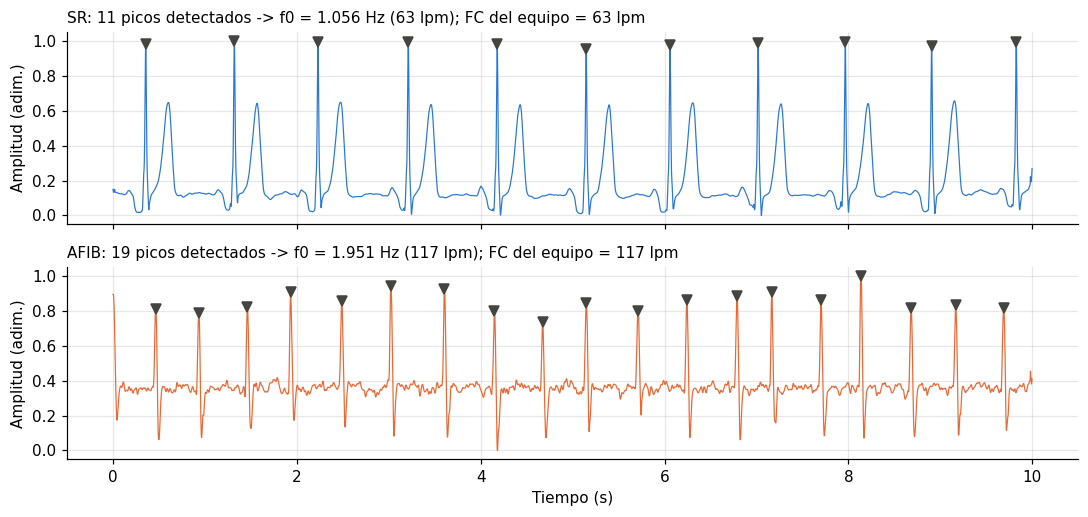

In [41]:
t = np.arange(len(senales["SR"])) / FS
fig, axes = plt.subplots(2, 1, figsize=(10, 4.8), sharex=True)
for ax, (ritmo, x), color in zip(axes, senales.items(), ["#2a78d6", "#eb6834"]):
    s = preprocesar(x)
    picos = detectar_picos_r(s)
    f0 = estimar_f0(s)
    ax.plot(t, s, color=color, lw=0.8)
    ax.plot(t[picos], s[picos], "v", color="#444441", markersize=6)
    ax.set_title(f"{ritmo}: {len(picos)} picos detectados -> f0 = {f0:.3f} Hz ({60 * f0:.0f} lpm); "
                 f"FC del equipo = {fc_ref[EJEMPLOS[ritmo]]} lpm", fontsize=10, loc="left")
    ax.set_ylabel("Amplitud (adim.)")
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
axes[-1].set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

In [42]:
filas = []
for ritmo, x in senales.items():
    r = contar_bicoherencia_significativa(preprocesar(x))
    r["Ritmo"] = ritmo
    r["FC del equipo (Hz)"] = fc_ref[EJEMPLOS[ritmo]] / 60
    filas.append(r)

tabla_sfsb = pd.DataFrame(filas).set_index("Ritmo")
tabla_sfsb["% signif."] = (100 * tabla_sfsb["sFSB"] / tabla_sfsb["pares"]).round(1)
tabla_sfsb["% signif. con f0"] = (100 * tabla_sfsb["sFSB con f0"] / tabla_sfsb["pares con f0"]).round(1)
tabla_sfsb.round(3).T          # .T muestra la tabla traspuesta (más fácil de leer)

Ritmo,SR,AFIB
N,10.000,10.000
umbral,0.678,0.678
pares,100.000,100.000
sFSB,92.000,61.000
f0 (Hz),1.056,1.951
f0 en rejilla (Hz),1.000,2.000
pares con f0,19.000,18.000
sFSB con f0,19.000,17.000
FC del equipo (Hz),1.050,1.950
% signif.,92.000,61.000


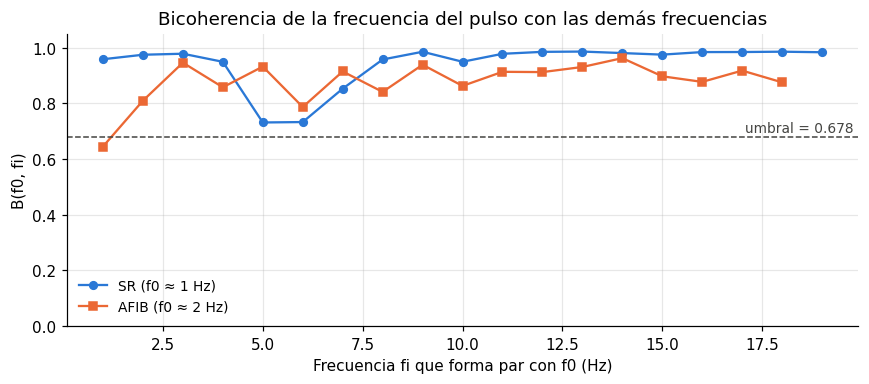

In [43]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for (ritmo, x), color, marca in zip(senales.items(), ["#2a78d6", "#eb6834"], ["o", "s"]):
    s = preprocesar(x)
    f, _, B, N = biespectro_bicoherencia(s)
    k0 = np.argmin(np.abs(f - estimar_f0(s)))
    # B(f0, fi): se toma la columna k0 y, donde está fuera del triángulo, la fila k0
    Bf0 = np.where(np.isnan(B[:, k0]), B[k0, :], B[:, k0])
    ok = ~np.isnan(Bf0)
    ax.plot(f[ok], Bf0[ok], marker=marca, markersize=5, lw=1.5, color=color,
            label=f"{ritmo} (f0 ≈ {f[k0]:.0f} Hz)")

u = umbral_bicoherencia(N)
ax.axhline(u, color="#444441", ls="--", lw=1)
ax.text(19.8, u + 0.02, f"umbral = {u:.3f}", ha="right", fontsize=9, color="#444441")
ax.set_xlabel("Frecuencia fi que forma par con f0 (Hz)"); ax.set_ylabel("B(f0, fi)")
ax.set_ylim(0, 1.05)
ax.set_title("Bicoherencia de la frecuencia del pulso con las demás frecuencias")
ax.legend(frameon=False, fontsize=9, loc="lower left")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [44]:
filas = []
for L in [250, 500, 1000]:
    for ritmo, x in senales.items():
        r = contar_bicoherencia_significativa(preprocesar(x), L=L)
        filas.append({"Segmento (muestras)": L, "Δf (Hz)": FS / L, "N": r["N"],
                      "umbral": round(r["umbral"], 3), "Ritmo": ritmo,
                      "% signif.": round(100 * r["sFSB"] / r["pares"], 1),
                      "% signif. con f0": round(100 * r["sFSB con f0"] / r["pares con f0"], 1)})

sensibilidad = pd.DataFrame(filas).pivot_table(
    index=["Segmento (muestras)", "Δf (Hz)", "N", "umbral"],
    columns="Ritmo", values=["% signif.", "% signif. con f0"])
sensibilidad

% signif.       % signif. con f0       
Ritmo                                      AFIB    SR             AFIB     SR
Segmento (muestras) Δf (Hz) N  umbral                                        
250                 2.0     20 0.480      100.0  96.0            100.0   88.9
500                 1.0     10 0.678       61.0  92.0             94.4  100.0
1000                0.5     5  0.959        4.2  15.8             27.8   68.4

### Interpretación

**Con la configuración elegida (segmentos de 1 s).** El registro SR tiene 92 de 100 pares significativos y el registro AFIB 61. La frecuencia del pulso del registro SR está acoplada con **todas** las frecuencias con las que forma par (19 de 19), con valores de bicoherencia cercanos a 1. Esto coincide con lo reportado por Kotriwar et al. [18] para sujetos sanos: un latido regular produce armónicas con relaciones de fase fijas. En el registro AFIB la bicoherencia con su frecuencia del pulso (~2 Hz) también es alta en la mayoría de los pares (17 de 18), pero es más variable. Con solo dos señales esto es una observación, no una conclusión; la comparación entre grupos se hace en los puntos 7 y 8.

**La sFSB depende mucho de cómo se segmenta la señal.** Al cambiar la longitud del segmento, el resultado cambia radicalmente:
- Con segmentos de 0,5 s (N = 20, umbral 0,48), casi todos los pares son significativos en ambas señales, y el registro AFIB llega incluso al 100 %. El umbral es bajo y la resolución de 2 Hz agrupa varias armónicas en cada casilla.
- Con segmentos de 2 s (N = 5, umbral 0,96), casi ningún par es significativo, porque el umbral está cerca de 1, el máximo posible.

La configuración de 1 s es la única que deja un umbral intermedio y, en estos dos ejemplos, separa ambos ritmos. Es una elección impuesta por la corta duración de los registros (10 s), que no permite usar segmentos largos como en [18] (8192 muestras sobre 60 s).

**Cautela al interpretar.** Como se mostró en la sección 3.4, con la normalización de la fórmula (4) el umbral produce cerca de 6 % de falsos positivos en ruido puro, en lugar del 1 % nominal. Por lo tanto, la sFSB debe usarse para **comparar** entre grupos procesados de la misma manera, y no interpretarse como el número exacto de acoplamientos reales.

---
# 6. Rutina sobre toda la base de datos

*Con el fin de obtener las características espectrales de todos los pacientes y verificar que tienen sentido fisiológico (comparándolas con la frecuencia cardíaca del electrocardiógrafo), se aplicó la rutina de los puntos 3 a 5 a toda la base.*

Se aplica a cada uno de los registros de la base el procedimiento de los puntos 3 a 5, sobre la derivación II:
1. Preprocesamiento: eliminación de la tendencia (fórmula 1) y compresión (fórmula 2).
2. Frecuencia de máxima potencia, **fMP** (punto 4).
3. Bicoherencia (fórmulas 3 y 4) y conteo de pares significativos, **sFSB** (punto 5).

Los resultados se guardan en un DataFrame con las columnas pedidas (**Registro, Estado, fMP, sFSB**) y algunas columnas adicionales que se usarán en los puntos 7 y 8: el conteo de pares con la frecuencia del pulso (`sFSB_f0`), la frecuencia del pulso estimada (`f0`), el grupo de ritmo de la sección 2.4, la edad, el sexo y la frecuencia cardíaca medida por el electrocardiógrafo.

**Robustez.** En una base de más de 10 000 archivos es común que alguno esté vacío, incompleto o dañado. La rutina revisa cada señal antes de procesarla y, si encuentra un problema, lo anota en la columna `Error` y sigue con el siguiente archivo, en lugar de detenerse.

**Eficiencia.** Solo se lee la columna de la derivación II de cada archivo, y los resultados se guardan en `resultados_punto6_v2.csv`, para no tener que recalcularlos cada vez que se abre el notebook.

In [45]:
import time

MUESTRAS_ESPERADAS = 5000      # 10 s a 500 Hz

def leer_derivacion_ii(nombre_archivo, carpeta=CARPETA_ECG):
    """Lee solo la columna de la derivación II (columna 1) de un registro."""
    ruta = os.path.join(carpeta, nombre_archivo + ".csv")
    return pd.read_csv(ruta, header=None, usecols=[1]).iloc[:, 0].to_numpy(dtype=float)

def procesar_registro(nombre_archivo, carpeta=CARPETA_ECG):
    """Aplica los puntos 3 a 5 a un registro. Si algo falla, lo anota en 'Error'."""
    resultado = {"Registro": nombre_archivo, "fMP": np.nan, "sFSB": np.nan,
                 "sFSB_f0": np.nan, "f0": np.nan, "Error": ""}
    try:
        x = leer_derivacion_ii(nombre_archivo, carpeta)

        # Controles de calidad antes de procesar
        if len(x) != MUESTRAS_ESPERADAS:
            raise ValueError(f"tiene {len(x)} muestras en lugar de {MUESTRAS_ESPERADAS}")
        if np.isnan(x).any():
            raise ValueError("contiene valores faltantes (NaN)")
        if np.ptp(x) == 0:                      # ptp = máximo - mínimo
            raise ValueError("señal constante (sin variación)")

        s = preprocesar(x)                                   # fórmulas (1) y (2)
        conteo = contar_bicoherencia_significativa(s)        # fórmulas (3), (4) y punto 5
        resultado.update({"fMP": frecuencia_max_potencia(s), # punto 4
                          "sFSB": conteo["sFSB"],
                          "sFSB_f0": conteo["sFSB con f0"],
                          "f0": conteo["f0 (Hz)"]})
    except FileNotFoundError:
        resultado["Error"] = "archivo no encontrado"
    except Exception as e:
        resultado["Error"] = str(e)
    return resultado

# Prueba con un registro conocido y con uno que no existe
print(procesar_registro(EJEMPLOS["SR"]))
print(procesar_registro("ARCHIVO_INVENTADO"))

{'Registro': 'MUSE_20180209_172046_21000', 'fMP': np.float64(1.05), 'sFSB': 92, 'sFSB_f0': 19, 'f0': np.float64(1.0559662090813093), 'Error': ''}
{'Registro': 'ARCHIVO_INVENTADO', 'fMP': nan, 'sFSB': nan, 'sFSB_f0': nan, 'f0': nan, 'Error': 'archivo no encontrado'}


In [46]:
muestra = diag["FileName"].sample(50, random_state=0)     # 50 registros al azar (reproducible)

inicio = time.perf_counter()
prueba = [procesar_registro(n) for n in muestra]
duracion = time.perf_counter() - inicio

errores_prueba = sum(r["Error"] != "" for r in prueba)
print(f"50 archivos en {duracion:.1f} s  ->  {1000 * duracion / 50:.0f} ms por archivo")
print(f"Tiempo estimado para {len(diag)} archivos: {len(diag) * duracion / 50 / 60:.1f} min")
print(f"Archivos con error en la prueba: {errores_prueba}")

50 archivos en 0.6 s  ->  13 ms por archivo
Tiempo estimado para 10646 archivos: 2.3 min
Archivos con error en la prueba: 0


In [47]:
RUTA_RESULTADOS = "resultados_punto6_v2.csv"   # v2: con f0 por picos R y fMP limitada a 40 Hz
RECALCULAR = False     # True = volver a procesar todo aunque ya exista el archivo de resultados

if os.path.exists(RUTA_RESULTADOS) and not RECALCULAR:
    res = pd.read_csv(RUTA_RESULTADOS, keep_default_na=False, na_values=[""])
    print(f"Resultados cargados de '{RUTA_RESULTADOS}' ({len(res)} registros).")
else:
    nombres = diag["FileName"].tolist()
    filas = []
    inicio = time.perf_counter()
    for i, nombre in enumerate(nombres, start=1):
        filas.append(procesar_registro(nombre))
        if i % 500 == 0 or i == len(nombres):              # informe de avance cada 500 archivos
            transcurrido = time.perf_counter() - inicio
            restante = transcurrido / i * (len(nombres) - i)
            print(f"{i:5d}/{len(nombres)} archivos  |  {transcurrido / 60:4.1f} min  |  "
                  f"faltan ~{restante / 60:4.1f} min")
    res = pd.DataFrame(filas)
    res.to_csv(RUTA_RESULTADOS, index=False)
    print(f"Resultados guardados en '{RUTA_RESULTADOS}'.")

Resultados cargados de 'resultados_punto6_v2.csv' (10646 registros).


In [48]:
# Información clínica de cada registro (de Diagnostics.xlsx)
info = diag[["FileName", "Rhythm", "Grupo", "PatientAge", "Gender", "VentricularRate"]].rename(
    columns={"FileName": "Registro", "Rhythm": "Estado", "PatientAge": "Edad",
             "Gender": "Sexo", "VentricularRate": "FC_equipo"})

resultados = info.merge(res, on="Registro", how="left")
resultados["Error"] = resultados["Error"].fillna("")
for c in ["sFSB", "sFSB_f0"]:
    resultados[c] = resultados[c].astype("Int64")       # enteros que admiten valores faltantes

# Columnas pedidas primero, luego las adicionales
resultados = resultados[["Registro", "Estado", "fMP", "sFSB",
                         "sFSB_f0", "f0", "Grupo", "Edad", "Sexo", "FC_equipo", "Error"]]

n_err = (resultados["Error"] != "").sum()
print(f"Registros procesados: {len(resultados)}")
print(f"Registros con error:  {n_err}")
if n_err:
    print("\nTipos de error:")
    print(resultados.loc[resultados["Error"] != "", "Error"].value_counts())

resultados.head(10)

Registros procesados: 10646
Registros con error:  41

Tipos de error:
Error
señal constante (sin variación)         40
tiene 1926 muestras en lugar de 5000     1
Name: count, dtype: int64


,Registro,Estado,fMP,sFSB,sFSB_f0,f0,Grupo,Edad,Sexo,FC_equipo,Error
0,MUSE_20180113_171327_27000,AFIB,9.0125,61,17,1.951008,AFIB,85,MALE,117,
1,MUSE_20180112_073319_29000,SB,0.8625,100,19,0.861645,SB,59,FEMALE,52,
2,MUSE_20180111_165520_97000,SA,1.1250,98,18,1.112347,SR,20,FEMALE,67,
3,MUSE_20180113_121940_44000,SB,3.5750,100,19,0.888494,SB,66,MALE,53,
4,MUSE_20180112_122850_57000,AF,5.4125,50,13,2.703265,AFIB,73,FEMALE,162,
5,MUSE_20180112_120347_79000,SB,3.7750,82,17,0.943841,SB,46,FEMALE,57,
6,MUSE_20180114_075026_69000,AFIB,3.9000,61,1,1.632653,AFIB,80,FEMALE,98,
7,MUSE_20180209_172046_21000,SR,1.0500,92,19,1.055966,SR,46,MALE,63,
8,MUSE_20180114_075128_92000,SB,0.9625,100,19,0.975081,SB,45,MALE,59,
9,MUSE_20180118_174026_42000,SB,2.9125,100,19,0.973394,SB,47,FEMALE,58,


In [49]:
ok = resultados[resultados["Error"] == ""].copy()
ok["FC_equipo_Hz"] = ok["FC_equipo"] / 60

# ¿La fMP y la f0 estimada coinciden con la FC del electrocardiógrafo? (tolerancia 0,1 Hz = 6 lpm)
ok["fMP = FC"] = (ok["fMP"] - ok["FC_equipo_Hz"]).abs() <= 0.1
ok["f0 = FC"]  = (ok["f0"]  - ok["FC_equipo_Hz"]).abs() <= 0.1

verif = (ok.groupby("Estado")[["fMP = FC", "f0 = FC"]].mean() * 100).round(1)
verif.insert(0, "n", ok["Estado"].value_counts())
verif.sort_values("n", ascending=False)

,n,fMP = FC,f0 = FC
Estado,,,
SB,3888,32.3,98.6
SR,1826,11.1,98.2
AFIB,1780,16.0,87.1
ST,1568,12.1,94.1
SVT,547,36.9,95.6
AF,445,18.4,88.1
SA,399,38.1,96.5
AT,121,9.1,86.0
AVNRT,16,25.0,100.0


In [50]:
# ¿La fMP cae en un múltiplo entero k de la frecuencia cardíaca? (tolerancia 0,1 Hz)
ok["k"] = (ok["fMP"] / ok["FC_equipo_Hz"]).round().astype(int)
ok["fMP armónica de FC"] = (ok["fMP"] - ok["k"] * ok["FC_equipo_Hz"]).abs() <= 0.1

armonicas = (ok.groupby("Estado")["fMP armónica de FC"].mean() * 100).round(1).to_frame("% fMP = k·FC")
armonicas.insert(0, "n", ok["Estado"].value_counts())
armonicas["k más frecuente"] = (ok[ok["fMP armónica de FC"]]
                                .groupby("Estado")["k"].agg(lambda s: s.mode().iloc[0]))
armonicas.sort_values("n", ascending=False)

,n,% fMP = k·FC,k más frecuente
Estado,,,
SB,3888,96.8,1
SR,1826,95.5,3
AFIB,1780,26.9,1
ST,1568,93.6,3
SVT,547,98.9,2
AF,445,53.7,2
SA,399,58.9,1
AT,121,49.6,2
AVNRT,16,100.0,2


### Interpretación

**Registros procesados.** De los 10 646 registros, 10 605 (99,6 %) se procesaron correctamente. Los 41 restantes (0,39 %) se excluyeron por problemas de calidad de la base pública: en 40 la derivación II es una línea plana (señal constante), probablemente por un electrodo desconectado o un registro vacío, y uno está incompleto (1926 muestras en lugar de 5000).

**Validación de la frecuencia del pulso (f₀).** La f₀ estimada a partir de los picos R coincide con la frecuencia cardíaca medida por el electrocardiógrafo (±0,1 Hz = ±6 lpm) en más del 94 % de los registros con ritmos regulares (SB 98,6 %, SR 98,2 %, SA 96,5 %, SVT 95,6 %, ST 94,1 %) y en el 86–88 % de los ritmos irregulares (AFIB 87,1 %, AF 88,1 %, AT 86,0 %). En los ritmos irregulares la amplitud del QRS varía de latido a latido y algunos latidos pequeños no superan el umbral del detector. Esto confirma que el detector basado en Pan y Tompkins [24] es fiable para estimar la frecuencia del pulso en toda la base.

**La fMP casi nunca es la frecuencia del pulso, pero sí una de sus armónicas.** La fMP coincide con la frecuencia cardíaca solo en el 9–38 % de los registros (por ejemplo, 11,1 % en SR). Sin embargo, en los ritmos regulares cae en un **múltiplo exacto** de la frecuencia cardíaca en el 94–99 % de los casos (SB 96,8 %, SR 95,5 %, ST 93,6 %, SVT 98,9 %). Esto confirma que el espectro está bien calculado: la señal es un peine de armónicas, y la de mayor potencia depende de la forma del complejo P-QRS-T. La armónica más frecuente es la 1.ª en SB, la 2.ª en SVT y la 3.ª en SR y ST.

En los ritmos irregulares esta estructura desaparece: la fMP es una armónica de la frecuencia cardíaca solo en el 26,8 % de las fibrilaciones auriculares. Esto concuerda con la irregularidad de los intervalos RR propia de la FA [15], que dispersa la energía en lugar de concentrarla en armónicas. En la irregularidad sinusal (59,1 %) también se observa, aunque en menor grado, por la variación de la frecuencia con la respiración. El flutter auricular (53,7 %) y la taquicardia auricular (49,6 %) quedan en una posición intermedia; en ellos la conducción al ventrículo puede ser regular o variable [15].

**Diferencia con la literatura.** Kotriwar et al. [18] reportan que en sujetos sanos la fMP coincide con la frecuencia del pulso (~1 Hz). En esta base, en cambio, la fundamental es la componente de mayor potencia solo en el 11 % de los registros con ritmo sinusal normal. Algunas posibles razones: [18] usa derivaciones precordiales (V1–V6) en lugar de la derivación II, registros de 60 s en lugar de 10 s, y otro preprocesamiento. Por lo tanto, en esta base la fMP refleja a la vez la frecuencia cardíaca y la morfología del latido, y debe interpretarse con eso en mente en los puntos 7 y 8.

---
# 7. Estadística descriptiva por arritmia

*Con el fin de identificar qué características espectrales diferencian a las arritmias, y de evaluar si esas diferencias se deben a la arritmia o a la frecuencia cardíaca, se describieron la fMP y la sFSB por grupo y en función de la frecuencia cardíaca.*

Se describen las características espectrales calculadas en los puntos 4 a 6 (**fMP**, **sFSB** y **sFSB con f₀**) para el subconjunto de análisis definido en la sección 2.4: pacientes de 18 años o más, agrupados en SB, SR, AFIB, GSVT y ST. Se excluyen los registros que no se pudieron procesar en el punto 6.

Como las tres variables tienen distribuciones asimétricas y valores atípicos, además de la media y la desviación estándar se reportan la **mediana** y el **rango intercuartílico** (RIC = Q3 − Q1), que no se ven afectados por los valores extremos.

Primero se comparan los grupos directamente. Luego se analiza la relación de cada variable con la frecuencia cardíaca, porque los grupos se definen en buena parte por ella (por ejemplo, SB < 60 lpm y ST > 100 lpm; sección 2.6.1) y eso puede confundir la comparación.

In [51]:
# Subconjunto de la sección 2.4, sin los registros con error del punto 6
datos = resultados[resultados["Registro"].isin(subconj["FileName"]) & (resultados["Error"] == "")].copy()
datos["Grupo"] = pd.Categorical(datos["Grupo"], categories=ORDEN_GRUPOS, ordered=True)

excluidos = subconj.groupby("Grupo").size() - datos.groupby("Grupo", observed=True).size()
pd.DataFrame({"En el subconjunto (2.4)": subconj.groupby("Grupo").size(),
              "Excluidos por error (punto 6)": excluidos,
              "Analizados": datos.groupby("Grupo", observed=True).size()}).loc[ORDEN_GRUPOS]

,En el subconjunto (2.4),Excluidos por error (punto 6),Analizados
Grupo,,,
SB,3871,1,3870
SR,2081,0,2081
AFIB,2225,0,2225
GSVT,721,40,681
ST,1483,0,1483


In [52]:
VARIABLES = {"fMP": "fMP (Hz)", "sFSB": "sFSB (pares)", "sFSB_f0": "sFSB con f0 (pares)"}

def describir(s):
    """Estadística descriptiva de una serie numérica (ignora valores faltantes)."""
    s = s.dropna().astype(float)
    return pd.Series({"n": len(s), "media": s.mean(), "DE": s.std(), "mediana": s.median(),
                      "Q1": s.quantile(0.25), "Q3": s.quantile(0.75),
                      "RIC": s.quantile(0.75) - s.quantile(0.25),
                      "mín": s.min(), "máx": s.max(), "asimetría": skew(s)})

tablas = {nombre: datos.groupby("Grupo", observed=True)[var].apply(describir).unstack()
          for var, nombre in VARIABLES.items()}
desc7 = pd.concat(tablas, axis=0).round(2)
desc7["n"] = desc7["n"].astype(int)
desc7

n  media     DE  mediana     Q1      Q3    RIC  \
                    Grupo                                                      
fMP (Hz)            SB     3870   2.67   1.73     2.76   0.96    3.69   2.72   
                    SR     2081   3.79   1.93     3.66   2.60    4.54   1.94   
                    AFIB   2225   4.17   2.74     3.58   2.44    4.95   2.51   
                    GSVT    681   4.73   2.00     4.76   3.12    5.70   2.58   
                    ST     1483   5.24   2.09     5.26   3.64    6.21   2.57   
sFSB (pares)        SB     3870  93.02   9.25    97.00  86.00  100.00  14.00   
                    SR     2081  82.79  12.67    83.00  75.00   94.00  19.00   
                    AFIB   2225  73.77  18.98    76.00  62.00   90.00  28.00   
                    GSVT    681  60.41  15.31    61.00  50.00   70.00  20.00   
                    ST     1483  63.92  11.89    66.00  57.00   71.00  14.00   
sFSB con f0 (pares) SB     3856  17.76   2.73    18.00  18.00   19.00   1.00   
                    SR     2078  16.06   3.90    17.00  15.00   19.00   4.00   
                    AFIB   2197  13.99   4.91    16.00  12.00   18.00   6.00   
                    GSVT    678  12.72   3.85    14.00  10.00   16.00   6.00   
                    ST     1470  14.36   4.07    16.00  14.00   17.00   3.00   

                             mín     máx  asimetría  
                    Grupo                            
fMP (Hz)            SB      0.54   17.98       1.60  
                    SR      0.70   18.18       1.53  
                    AFIB    0.30   20.40       2.04  
                    GSVT    0.61   17.31       1.93  
                    ST      0.79   22.95       0.81  
sFSB (pares)        SB     31.00  100.00      -1.78  
                    SR     20.00  100.00      -0.67  
                    AFIB    0.00  100.00      -0.61  
                    GSVT   12.00  100.00       0.01  
                    ST     20.00  100.00      -0.38  
sFSB con f0 (pares) SB      0.00   19.00      -4.52  
                    SR      0.00   19.00      -2.21  
                    AFIB    0.00   19.00      -1.24  
                    GSVT    0.00   19.00      -0.79  
                    ST      0.00   19.00      -1.99

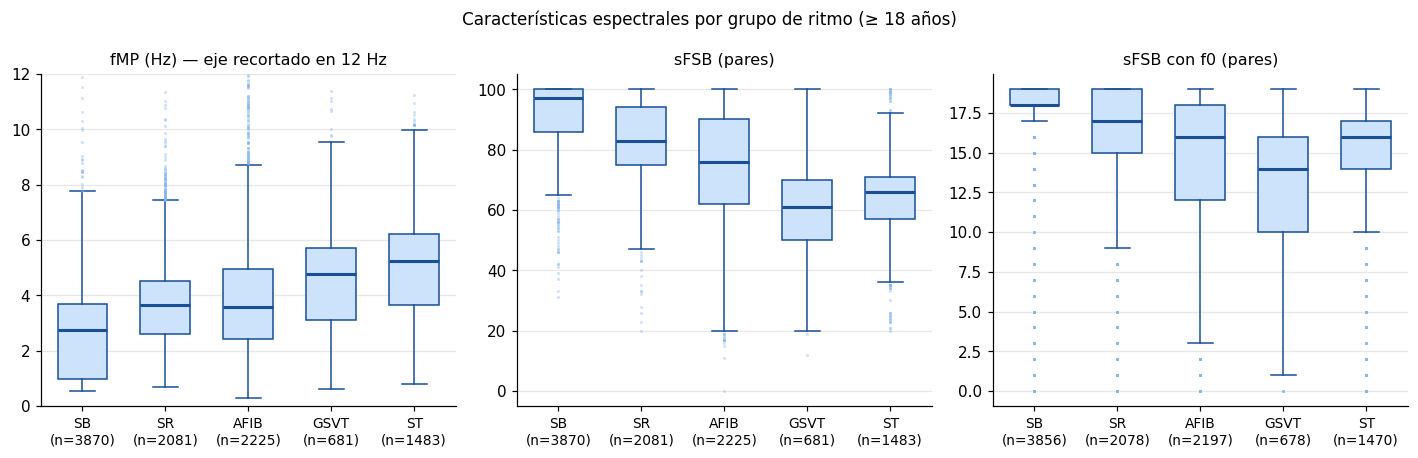

In [53]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for ax, (var, nombre) in zip(axes, VARIABLES.items()):
    grupos = [datos.loc[datos["Grupo"] == g, var].dropna().astype(float) for g in ORDEN_GRUPOS]
    ax.boxplot(grupos, widths=0.6, patch_artist=True,
               boxprops=dict(facecolor="#cde2fb", edgecolor="#184f95"),
               medianprops=dict(color="#184f95", lw=2),
               whiskerprops=dict(color="#184f95"), capprops=dict(color="#184f95"),
               flierprops=dict(marker="o", markersize=2, markerfacecolor="#86b6ef",
                               markeredgecolor="none", alpha=0.4))
    ax.set_xticks(range(1, len(ORDEN_GRUPOS) + 1),
                  [f"{g}\n(n={len(s)})" for g, s in zip(ORDEN_GRUPOS, grupos)], fontsize=9)
    ax.set_title(nombre, fontsize=10.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3); ax.set_axisbelow(True)

axes[0].set_ylim(0, 12)                                   # 96 valores de fMP > 12 Hz quedan fuera
axes[0].set_title("fMP (Hz) — eje recortado en 12 Hz", fontsize=10.5)
fig.suptitle("Características espectrales por grupo de ritmo (≥ 18 años)", fontsize=11)
plt.tight_layout(); plt.show()

### Comparación directa entre grupos

- **fMP.** Aumenta con la frecuencia cardíaca típica de cada grupo: la mediana es menor en SB (2,76 Hz) y mayor en ST (5,26 Hz) y GSVT (4,76 Hz). SR y AFIB tienen medianas parecidas (3,66 y 3,58 Hz), pero AFIB tiene mayor dispersión (DE 2,74 Hz) y más valores atípicos altos, lo que concuerda con la falta de estructura armónica de la FA (punto 6). Las cinco distribuciones son asimétricas a la derecha (asimetría entre 0,8 y 2,0).
- **sFSB.** Es máxima en SB (mediana 97 de 100 pares) y disminuye en SR (83), AFIB (76), ST (66) y GSVT (61). AFIB tiene la mayor dispersión (DE 19,0; RIC 28), con registros que van de 0 a 100 pares significativos.
- **sFSB con f₀.** Sigue el mismo orden: el acoplamiento de la frecuencia del pulso con las demás frecuencias es casi completo en SB (mediana 18 de ~19 pares posibles) y menor en AFIB (16) y GSVT (14).

A primera vista, esto coincide con la hipótesis de Kotriwar et al. [18]: los ritmos sinusales lentos tienen más acoplamiento de fase que las arritmias. Sin embargo, el orden de los grupos sigue de cerca su frecuencia cardíaca típica (SB < SR < AFIB < ST < GSVT), así que antes de atribuir las diferencias a la arritmia hay que revisar el efecto de la frecuencia cardíaca.

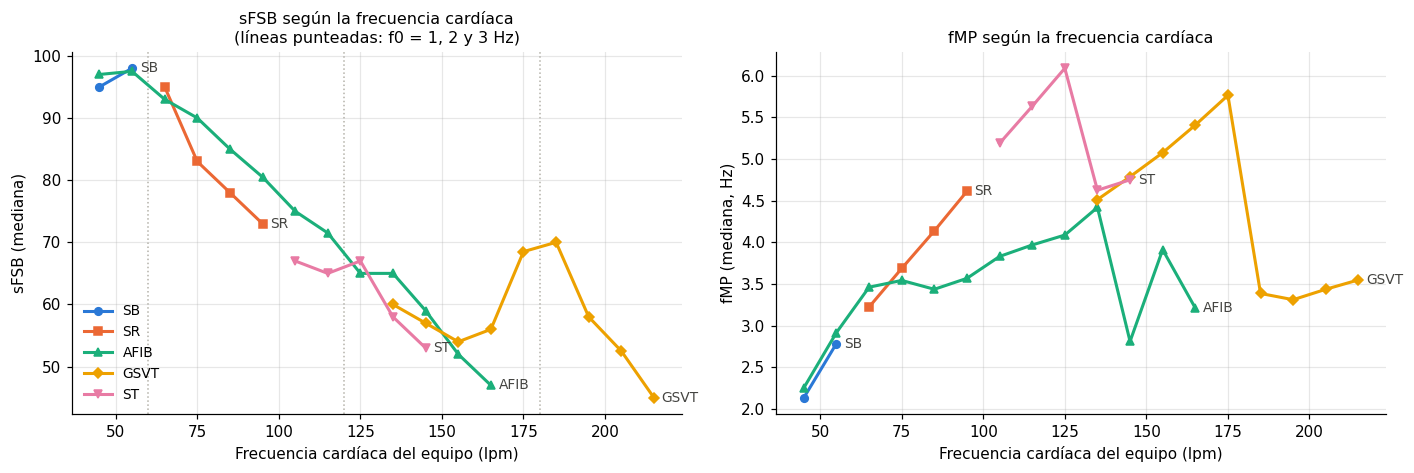

In [54]:
COLOR_GRUPO = {"SB": "#2a78d6", "SR": "#eb6834", "AFIB": "#1baf7a", "GSVT": "#eda100", "ST": "#e87ba4"}
MARCA_GRUPO = {"SB": "o", "SR": "s", "AFIB": "^", "GSVT": "D", "ST": "v"}
N_MIN_BIN = 20       # solo se grafican intervalos con al menos 20 registros

datos["FC_bin"] = (datos["FC_equipo"] // 10) * 10 + 5     # centro de intervalos de 10 lpm

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharex=True)
for ax, var, nombre in [(axes[0], "sFSB", "sFSB (mediana)"), (axes[1], "fMP", "fMP (mediana, Hz)")]:
    for g in ORDEN_GRUPOS:
        d = datos[datos["Grupo"] == g]
        por_bin = d.groupby("FC_bin")[var].agg(["median", "count"])
        por_bin = por_bin[por_bin["count"] >= N_MIN_BIN]
        ax.plot(por_bin.index, por_bin["median"].astype(float), marker=MARCA_GRUPO[g],
                markersize=5, lw=2, color=COLOR_GRUPO[g], label=g)
        ax.annotate(g, (por_bin.index[-1], float(por_bin["median"].iloc[-1])),   # nombre al final
                    xytext=(5, 0), textcoords="offset points", va="center", fontsize=9, color="#444441")
    ax.set_xlabel("Frecuencia cardíaca del equipo (lpm)"); ax.set_ylabel(nombre)
    ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)

for fc in [60, 120, 180]:                                 # f0 = 1, 2 y 3 Hz
    axes[0].axvline(fc, color="#B4B2A9", ls=":", lw=1, zorder=0)
axes[0].set_title("sFSB según la frecuencia cardíaca\n(líneas punteadas: f0 = 1, 2 y 3 Hz)", fontsize=10.5)
axes[1].set_title("fMP según la frecuencia cardíaca", fontsize=10.5)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
plt.tight_layout(); plt.show()

In [55]:
BINS_FC = [60, 70, 80, 90, 100, 110, 120]
datos["Rango FC"] = pd.cut(datos["FC_equipo"], BINS_FC)

emp_med = datos.pivot_table(index="Rango FC", columns="Grupo", values="sFSB",
                            aggfunc="median", observed=False)
emp_n   = datos.pivot_table(index="Rango FC", columns="Grupo", values="sFSB",
                            aggfunc="count", observed=False)
emp_med = emp_med.where(emp_n >= N_MIN_BIN)           # se ocultan las celdas con menos de 20 registros

rho, p = spearmanr(datos["FC_equipo"], datos["sFSB"].astype(float))
print(f"Correlación de Spearman entre FC y sFSB (todos los grupos): rho = {rho:.2f}, p = {p:.1e}")
for g in ORDEN_GRUPOS:
    d = datos[datos["Grupo"] == g]
    r, _ = spearmanr(d["FC_equipo"], d["sFSB"].astype(float))
    print(f"   dentro de {g:4s}: rho = {r:+.2f}")

emp_med.astype(float).round(1)

Correlación de Spearman entre FC y sFSB (todos los grupos): rho = -0.68, p = 0.0e+00
   dentro de SB  : rho = +0.38
   dentro de SR  : rho = -0.58
   dentro de AFIB: rho = -0.61
   dentro de GSVT: rho = -0.07
   dentro de ST  : rho = -0.10


Grupo,SB,SR,AFIB,GSVT,ST
Rango FC,,,,,
"(60, 70]",NaN,93.0,91.0,NaN,NaN
"(70, 80]",NaN,82.0,90.0,NaN,NaN
"(80, 90]",NaN,78.0,85.0,NaN,NaN
"(90, 100]",NaN,72.5,80.0,NaN,NaN
"(100, 110]",NaN,NaN,75.0,67.0,67.0
"(110, 120]",NaN,NaN,70.0,NaN,65.0


### Efecto de la frecuencia cardíaca

**La sFSB depende fuertemente de la frecuencia cardíaca.** Entre todos los registros, la correlación de Spearman entre la frecuencia cardíaca y la sFSB es ρ = −0,68: a mayor frecuencia, menos pares significativos. La gráfica muestra además un patrón llamativo: la sFSB es máxima cerca de **60 lpm** (f₀ ≈ 1 Hz) y GSVT tiene un repunte justo en **~180 lpm** (f₀ ≈ 3 Hz); en ST se insinúa uno menor cerca de 120 lpm (f₀ ≈ 2 Hz). Esto se explica por la rejilla de 1 Hz de la bicoherencia (sección 3.4). Cuando f₀ es un número entero de Hz, todas sus armónicas caen exactamente sobre las casillas de la rejilla; cuando no lo es, caen entre casillas y la fase medida en cada casilla es menos estable de un segmento a otro. Esto también explica que la correlación sea positiva dentro de SB (al acercarse a 60 lpm la sFSB aumenta) y negativa dentro de SR y AFIB (al alejarse de 60 lpm la sFSB disminuye).

**A igual frecuencia cardíaca, la FA no tiene menos acoplamiento que el ritmo sinusal.** En la comparación directa, AFIB tiene menos pares significativos que SR (mediana 76 frente a 83). Pero al comparar pacientes en el mismo rango de frecuencia cardíaca, la relación se invierte: entre 70 y 100 lpm, AFIB tiene **más** pares significativos que SR (por ejemplo, 85 frente a 78 entre 80 y 90 lpm). La diferencia directa se debe a que los pacientes con FA tienen en promedio una frecuencia más alta (mediana 94 frente a 74 lpm). Esto es un ejemplo de **confusión**: una tercera variable, la frecuencia cardíaca, crea o invierte una diferencia aparente entre grupos. Una posible explicación es que la bicoherencia no cambia al desplazar la señal en el tiempo (sección 3.4), por lo que en segmentos de 1 s refleja sobre todo la consistencia de la **forma** del complejo QRS dentro de cada segmento, más que la regularidad del ritmo. Esta explicación es una hipótesis y no se verifica en este trabajo.

**La fMP es la armónica más cercana a una "zona preferida" del espectro.** En los ritmos regulares la fMP crece con la frecuencia cardíaca y luego "salta" hacia abajo: en ST pasa de ~6,1 Hz a ~4,6 Hz al cruzar 130 lpm, y en GSVT de ~5,8 Hz a ~3,4 Hz al cruzar 180 lpm. Esto ocurre cuando la armónica de mayor potencia cambia (por ejemplo, de la 3.ª a la 2.ª) para mantenerse en la zona de ~3–6 Hz, donde se concentra la energía de la forma del latido (ondas T y QRS). En la FA, sin armónicas definidas, la fMP se queda en esa zona (~3,5–4 Hz) casi independientemente de la frecuencia cardíaca.

**Calidad de los datos.** Los 40 registros excluidos por tener la derivación II plana son todos SVT (5,5 % del grupo GSVT). Esto puede introducir un sesgo si esos registros tenían características particulares. Llama la atención que, sin ellos, quedan 547 SVT, muy cerca de los 542 reportados por Zheng et al. [2] en el conjunto de 40 258 pacientes (sección 2.5). Es una coincidencia que no se puede verificar con los datos disponibles.

**Consecuencia para el punto 8.** Las pruebas estadísticas deben hacerse de dos formas: comparando los grupos directamente, y **controlando la frecuencia cardíaca**. Si solo se hiciera la comparación directa, se atribuirían a la arritmia diferencias que en realidad se deben a la frecuencia cardíaca.

---
# 8. Pruebas estadísticas

*Con el fin de determinar si las diferencias observadas en el punto 7 son estadísticamente significativas, y si se mantienen al controlar la frecuencia cardíaca y la edad, se aplicaron las siguientes pruebas.*

**Pregunta:** ¿hay diferencias estadísticamente significativas en las características espectrales (fMP, sFSB y sFSB con f₀) entre los grupos de ritmo?

**Procedimiento:**
1. **Normalidad.** Se evalúa con la prueba de D'Agostino-Pearson [25], que combina la asimetría y la curtosis y es adecuada para muestras grandes. Si los datos no son normales, se usan pruebas no paramétricas, basadas en rangos.
2. **Prueba global: Kruskal-Wallis** [10]. H₀: las cinco distribuciones son iguales. El tamaño del efecto se mide con ε², la fracción de la variabilidad de los rangos explicada por el grupo [11].
3. **Comparaciones por pares: U de Mann-Whitney** [26], con corrección de Bonferroni por las 10 comparaciones [7]. El tamaño del efecto se mide con el **δ de Cliff** [27]: δ = P(X₁ > X₂) − P(X₁ < X₂), que va de −1 a 1. Un δ positivo significa que el primer grupo tiende a tener valores mayores. Se interpreta como despreciable (|δ| < 0,147), pequeño (< 0,33), mediano (< 0,474) o grande (≥ 0,474) [28].
4. **Control de la frecuencia cardíaca.** Como se vio en el punto 7, la sFSB depende fuertemente de la frecuencia cardíaca. Por eso las comparaciones se repiten **dentro de rangos de 10 lpm** donde dos grupos se solapan: SR frente a AFIB entre 60 y 100 lpm, y AFIB frente a ST entre 100 y 120 lpm, con corrección de Bonferroni por las 6 comparaciones de cada variable.

**Por qué reportar el tamaño del efecto.** Con miles de registros por grupo, las pruebas detectan como "significativas" diferencias muy pequeñas que pueden no tener importancia práctica. El valor p indica si una diferencia es real, y el tamaño del efecto indica si es grande.

In [56]:
filas = []
for var, nombre in VARIABLES.items():
    for g in ORDEN_GRUPOS:
        s = datos.loc[datos["Grupo"] == g, var].dropna().astype(float)
        estadistico, p = normaltest(s)                       # D'Agostino-Pearson [25]
        filas.append({"Variable": nombre, "Grupo": g, "n": len(s),
                      "Asimetría": round(skew(s), 2), "K²": round(estadistico, 1), "p": p})

normalidad = pd.DataFrame(filas)
normalidad["¿Normal? (p > 0,05)"] = np.where(normalidad["p"] > 0.05, "Sí", "No")
normalidad.style.format({"p": "{:.1e}"})

,Variable,Grupo,n,Asimetría,K²,p,"¿Normal? (p > 0,05)"
0,fMP (Hz),SB,3870,1.600000,1386.200000,9.9e-302,No
1,fMP (Hz),SR,2081,1.530000,727.700000,9.4e-159,No
2,fMP (Hz),AFIB,2225,2.040000,944.000000,1.0e-205,No
3,fMP (Hz),GSVT,681,1.930000,311.500000,2.3e-68,No
4,fMP (Hz),ST,1483,0.810000,274.800000,2.1e-60,No
5,sFSB (pares),SB,3870,-1.780000,1385.400000,1.4e-301,No
6,sFSB (pares),SR,2081,-0.670000,158.400000,4.1e-35,No
7,sFSB (pares),AFIB,2225,-0.610000,126.500000,3.5e-28,No
8,sFSB (pares),GSVT,681,0.010000,0.900000,6.4e-01,Sí
9,sFSB (pares),ST,1483,-0.380000,70.900000,4.0e-16,No


In [57]:
filas = []
for var, nombre in VARIABLES.items():
    grupos = [datos.loc[datos["Grupo"] == g, var].dropna().astype(float) for g in ORDEN_GRUPOS]
    H, p = kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    filas.append({"Variable": nombre, "n": n, "H": round(H, 1), "gl": len(grupos) - 1,
                  "p": "< 1e-300" if p == 0 else f"{p:.1e}", "ε²": round(H / (n - 1), 3)})

kw8 = pd.DataFrame(filas).set_index("Variable")
kw8

,n,H,gl,p,ε²
Variable,,,,,
fMP (Hz),10340,2152.5,4,< 1e-300,0.208
sFSB (pares),10340,4769.2,4,< 1e-300,0.461
sFSB con f0 (pares),10279,3328.2,4,< 1e-300,0.324


In [58]:
def delta_cliff(a, b):
    """δ de Cliff a partir del estadístico U de Mann-Whitney [27]."""
    U, _ = mannwhitneyu(a, b, alternative="two-sided")
    return 2 * U / (len(a) * len(b)) - 1

def magnitud_delta(d):
    """Umbrales de Romano et al. [28]."""
    d = abs(d)
    if d < 0.147: return "despreciable"
    if d < 0.33:  return "pequeña"
    if d < 0.474: return "mediana"
    return "grande"

PARES = list(combinations(ORDEN_GRUPOS, 2))      # 10 pares
filas = []
for var, nombre in VARIABLES.items():
    for g1, g2 in PARES:
        a = datos.loc[datos["Grupo"] == g1, var].dropna().astype(float)
        b = datos.loc[datos["Grupo"] == g2, var].dropna().astype(float)
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        d = delta_cliff(a, b)
        filas.append({"Variable": nombre, "Comparación": f"{g1} vs {g2}",
                      "Mediana 1": a.median(), "Mediana 2": b.median(),
                      "p Bonferroni": min(p * len(PARES), 1.0),
                      "δ de Cliff": round(d, 2), "Magnitud": magnitud_delta(d)})

posthoc = pd.DataFrame(filas)
posthoc["¿Significativo?"] = np.where(posthoc["p Bonferroni"] < 0.05, "Sí", "No")
display(posthoc.style.format({"p Bonferroni": "{:.1e}", "Mediana 1": "{:.2f}", "Mediana 2": "{:.2f}"}))

# Resumen compacto: δ de Cliff de cada comparación para las tres variables
resumen_delta = posthoc.pivot(index="Comparación", columns="Variable", values="δ de Cliff")
resumen_delta.loc[[f"{a} vs {b}" for a, b in PARES], list(VARIABLES.values())]

,Variable,Comparación,Mediana 1,Mediana 2,p Bonferroni,δ de Cliff,Magnitud,¿Significativo?
0,fMP (Hz),SB vs SR,2.76,3.66,2.1e-151,-0.410000,mediana,Sí
1,fMP (Hz),SB vs AFIB,2.76,3.58,2.5e-135,-0.380000,mediana,Sí
2,fMP (Hz),SB vs GSVT,2.76,4.76,1.4e-135,-0.600000,grande,Sí
3,fMP (Hz),SB vs ST,2.76,5.26,0.0e+00,-0.670000,grande,Sí
4,fMP (Hz),SR vs AFIB,3.66,3.58,1.0e+00,-0.020000,despreciable,No
5,fMP (Hz),SR vs GSVT,3.66,4.76,1.8e-31,-0.300000,pequeña,Sí
6,fMP (Hz),SR vs ST,3.66,5.26,1.1e-113,-0.450000,mediana,Sí
7,fMP (Hz),AFIB vs GSVT,3.58,4.76,2.5e-25,-0.270000,pequeña,Sí
8,fMP (Hz),AFIB vs ST,3.58,5.26,6.5e-84,-0.380000,mediana,Sí
9,fMP (Hz),GSVT vs ST,4.76,5.26,3.5e-11,-0.190000,pequeña,Sí


Variable,fMP (Hz),sFSB (pares),sFSB con f0 (pares)
Comparación,,,
SB vs SR,-0.41,0.51,0.33
SB vs AFIB,-0.38,0.66,0.62
SB vs GSVT,-0.60,0.91,0.86
SB vs ST,-0.67,0.93,0.78
SR vs AFIB,-0.02,0.27,0.30
SR vs GSVT,-0.30,0.75,0.57
SR vs ST,-0.45,0.74,0.38
AFIB vs GSVT,-0.27,0.43,0.27
AFIB vs ST,-0.38,0.37,0.04


### Comparación directa entre grupos

**Ninguna variable es normal** (14 de 15 combinaciones con p < 0,05 en la prueba de D'Agostino-Pearson [25]), lo que justifica el uso de pruebas no paramétricas.

**Sí hay diferencias estadísticamente significativas entre los grupos en las tres variables** (Kruskal-Wallis, p < 0,001 en todos los casos). El efecto es mayor para la sFSB (ε² = 0,46) que para la sFSB con f₀ (ε² = 0,32) y la fMP (ε² = 0,21).

En las comparaciones por pares, 28 de 30 son significativas tras la corrección de Bonferroni:
- **fMP:** aumenta de SB a ST. Las diferencias de SB con GSVT y ST son grandes (δ = −0,60 y −0,67). La única comparación no significativa es **SR frente a AFIB** (medianas 3,66 y 3,58 Hz; δ = −0,02): la fMP no distingue la fibrilación auricular del ritmo sinusal.
- **sFSB:** las diferencias son grandes entre SB y todos los demás grupos (δ de 0,51 a 0,93) y entre SR y las taquicardias (GSVT y ST, δ ≈ 0,75). Entre SR y AFIB la diferencia es significativa pero pequeña (δ = 0,27).
- **sFSB con f₀:** sigue un patrón parecido. AFIB y ST no difieren (δ = 0,04).

Sin embargo, el orden de los grupos en las tres variables coincide con su frecuencia cardíaca típica, por lo que estas diferencias deben revisarse controlando por ella.

In [59]:
COMPARACIONES_FC = [("SR", "AFIB", 60, 70), ("SR", "AFIB", 70, 80), ("SR", "AFIB", 80, 90),
                    ("SR", "AFIB", 90, 100), ("AFIB", "ST", 100, 110), ("AFIB", "ST", 110, 120)]
filas = []
for var, nombre in VARIABLES.items():
    for g1, g2, lo, hi in COMPARACIONES_FC:
        en_rango = (datos["FC_equipo"] > lo) & (datos["FC_equipo"] <= hi)
        a = datos.loc[en_rango & (datos["Grupo"] == g1), var].dropna().astype(float)
        b = datos.loc[en_rango & (datos["Grupo"] == g2), var].dropna().astype(float)
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        d = delta_cliff(a, b)
        filas.append({"Variable": nombre, "FC (lpm)": f"{lo}–{hi}", "Comparación": f"{g1} vs {g2}",
                      "n1": len(a), "n2": len(b), "Mediana 1": a.median(), "Mediana 2": b.median(),
                      "p Bonferroni": min(p * len(COMPARACIONES_FC), 1.0),
                      "δ de Cliff": round(d, 2), "Magnitud": magnitud_delta(d)})

estratificado = pd.DataFrame(filas)
estratificado["¿Significativo?"] = np.where(estratificado["p Bonferroni"] < 0.05, "Sí", "No")
estratificado.style.format({"p Bonferroni": "{:.1e}", "Mediana 1": "{:.2f}", "Mediana 2": "{:.2f}"})

,Variable,FC (lpm),Comparación,n1,n2,Mediana 1,Mediana 2,p Bonferroni,δ de Cliff,Magnitud,¿Significativo?
0,fMP (Hz),60–70,SR vs AFIB,727,219,3.26,3.46,8.3e-03,-0.140000,despreciable,Sí
1,fMP (Hz),70–80,SR vs AFIB,720,328,3.71,3.56,1.0e+00,0.020000,despreciable,No
2,fMP (Hz),80–90,SR vs AFIB,405,339,4.19,3.54,1.7e-04,0.180000,pequeña,Sí
3,fMP (Hz),90–100,SR vs AFIB,172,315,4.66,3.54,1.2e-09,0.350000,mediana,Sí
4,fMP (Hz),100–110,AFIB vs ST,231,888,3.89,5.20,1.9e-14,-0.340000,mediana,Sí
5,fMP (Hz),110–120,AFIB vs ST,185,320,3.96,5.68,2.9e-09,-0.330000,mediana,Sí
6,sFSB (pares),60–70,SR vs AFIB,727,219,93.00,91.00,6.3e-02,0.110000,despreciable,No
7,sFSB (pares),70–80,SR vs AFIB,720,328,82.00,90.00,5.4e-08,-0.220000,pequeña,Sí
8,sFSB (pares),80–90,SR vs AFIB,405,339,78.00,85.00,1.6e-10,-0.280000,pequeña,Sí
9,sFSB (pares),90–100,SR vs AFIB,172,315,72.50,80.00,1.9e-06,-0.280000,pequeña,Sí


### Efecto de controlar la frecuencia cardíaca

**sFSB.** Al comparar pacientes con frecuencias cardíacas similares, la diferencia entre ritmo sinusal y fibrilación auricular **cambia de sentido**. En la comparación directa, SR tiene más pares significativos que AFIB (δ = 0,27). Pero dentro de cada rango entre 70 y 100 lpm, AFIB tiene más pares significativos que SR (δ entre −0,22 y −0,28, efecto pequeño, p < 0,001), y entre 60 y 70 lpm no hay diferencia. Del mismo modo, a igual frecuencia cardíaca, AFIB tiene más pares significativos que ST (δ = 0,37 y 0,17). Es decir, la menor sFSB de la FA en la comparación directa se explica por su mayor frecuencia cardíaca, no por un menor acoplamiento de fase. Esto contradice la hipótesis de Kotriwar et al. [18], según la cual las patologías reducen el acoplamiento de fase.

**fMP.** A igual frecuencia cardíaca, la fMP de AFIB es menor que la de SR por encima de 80 lpm (δ = 0,18 y 0,35) y menor que la de ST (δ ≈ −0,33). Esto concuerda con lo observado en el punto 7: en la FA la fMP se queda en ~3,5–4 Hz, mientras que en los ritmos regulares sigue a la armónica de la frecuencia cardíaca que cae en esa zona.

**sFSB con f₀.** El sentido de la diferencia entre SR y AFIB cambia de un rango a otro (SR mayor entre 60 y 80 lpm, igual entre 80 y 90, AFIB mayor entre 90 y 100). Esto indica que esta variable está dominada por la posición de f₀ respecto a la rejilla de 1 Hz, y no es una característica confiable con la resolución disponible.

### Respuesta

**Sí hay diferencias estadísticamente significativas** en la fMP y en la sFSB entre los grupos de ritmo (Kruskal-Wallis, p < 0,001; ε² = 0,21 y 0,46). Casi todas las comparaciones por pares son significativas, con efectos de pequeños a grandes; la excepción es la fMP de SR frente a AFIB, que no difiere. Sin embargo, **gran parte de estas diferencias se explica por la frecuencia cardíaca** que define a cada grupo. Al controlarla, las diferencias entre ritmo sinusal y fibrilación auricular son pequeñas y, en la sFSB, de sentido opuesto al de la comparación directa. Por lo tanto, la fMP y la sFSB, tal como se calcularon sobre registros de 10 s, **no son por sí solas buenos marcadores de arritmia**: reflejan sobre todo la frecuencia cardíaca y la forma del latido.

**Limitaciones.**
- Además de la frecuencia cardíaca, los grupos difieren en **edad**: a igual frecuencia cardíaca, los pacientes con FA tienen una mediana de unos 75 años y los de SR unos 54. Este posible efecto se evalúa en la sección 8.8.
- La estratificación solo permite comparar grupos cuyas frecuencias cardíacas se solapan. SB (< 60 lpm) no puede compararse con ST (> 100 lpm) a igual frecuencia cardíaca.
- La resolución de 1 Hz de la bicoherencia, impuesta por la duración de 10 s de los registros, introduce una dependencia artificial de la sFSB con la frecuencia cardíaca (punto 7).

### Reporte de las pruebas estadísticas

Nivel de significancia: α = 0,05 en todas las pruebas, con corrección de Bonferroni en las comparaciones múltiples [7].

| | Prueba 1 | Prueba 2 | Prueba 3 | Prueba 4 |
|---|---|---|---|---|
| **Objetivo** | ¿La fMP difiere entre los 5 grupos? | ¿La sFSB difiere entre los 5 grupos? | ¿La fMP difiere entre SR y AFIB? | ¿La sFSB difiere entre SR y AFIB a igual FC (80–90 lpm)? |
| **Prueba** | Kruskal-Wallis [10] | Kruskal-Wallis [10] | U de Mann-Whitney [26] | U de Mann-Whitney [26] |
| **H₀** | La distribución de la fMP es igual en los 5 grupos | La distribución de la sFSB es igual en los 5 grupos | La fMP de SR y AFIB tiene la misma distribución | Con FC entre 80 y 90 lpm, la sFSB de SR y AFIB tiene la misma distribución |
| **H₁** | Al menos un grupo difiere | Al menos un grupo difiere | Las distribuciones difieren | Las distribuciones difieren |
| **Estadístico** | H = 2152,5 (gl = 4) | H = 4769,2 (gl = 4) | U = 2 269 358 | U = 49 208,5 |
| **p-valor** | < 0,001 | < 0,001 | 1,00 (Bonferroni) | 1,6 × 10⁻¹⁰ (Bonferroni) |
| **Tamaño del efecto** | ε² = 0,21 | ε² = 0,46 | δ = −0,02 (despreciable) | δ = −0,28 (pequeño) |
| **Decisión** | Se rechaza H₀ | Se rechaza H₀ | No se rechaza H₀ | Se rechaza H₀ |
| **Interpretación** | La frecuencia de máxima potencia cambia con el tipo de ritmo, principalmente porque sigue a la armónica de la frecuencia cardíaca que define a cada grupo | El acoplamiento de fase difiere entre ritmos, pero en gran parte por la frecuencia cardíaca (ρ = −0,68 con la FC) | La fMP no permite distinguir la fibrilación auricular del ritmo sinusal | A igual frecuencia cardíaca, la FA tiene **más** acoplamiento de fase que el ritmo sinusal, al contrario que en la comparación directa |

### 8.8 ¿La diferencia de edad entre grupos cambia el resultado?

Los pacientes con fibrilación auricular son en promedio unos 20 años mayores que los de ritmo sinusal, incluso a igual frecuencia cardíaca (mediana ~75 frente a ~54 años). La edad modifica el ECG: con los años cambian la morfología de las ondas y la conducción. Por eso, la diferencia entre SR y AFIB encontrada en la sección anterior podría deberse a la edad y no a la arritmia.

Con el fin de evaluar si la comparación es viable a pesar de esta diferencia, se comparan SR y AFIB **dentro del mismo rango de edad y de frecuencia cardíaca a la vez**: dos rangos de edad (50–64 y 65–79 años, donde hay suficientes pacientes de ambos grupos) por tres rangos de frecuencia cardíaca, con corrección de Bonferroni por las 6 comparaciones. Además, se mide la correlación entre la edad y la sFSB dentro de cada grupo.

In [60]:
filas = []
for e_lo, e_hi in [(50, 65), (65, 80)]:
    for lo, hi in [(70, 80), (80, 90), (90, 100)]:
        en = ((datos["FC_equipo"] > lo) & (datos["FC_equipo"] <= hi) &
              (datos["Edad"] >= e_lo) & (datos["Edad"] < e_hi))
        a = datos.loc[en & (datos["Grupo"] == "SR"), "sFSB"].astype(float)
        b = datos.loc[en & (datos["Grupo"] == "AFIB"), "sFSB"].astype(float)
        _, p = mannwhitneyu(a, b, alternative="two-sided")
        filas.append({"Edad (años)": f"{e_lo}–{e_hi - 1}", "FC (lpm)": f"{lo}–{hi}",
                      "n SR": len(a), "n AFIB": len(b),
                      "Mediana SR": a.median(), "Mediana AFIB": b.median(),
                      "p Bonferroni": min(p * 6, 1.0), "δ de Cliff": round(delta_cliff(a, b), 2)})

edad_fc = pd.DataFrame(filas)
edad_fc["¿Significativo?"] = np.where(edad_fc["p Bonferroni"] < 0.05, "Sí", "No")

for g in ["SR", "AFIB"]:
    d = datos[datos["Grupo"] == g]
    rho, p = spearmanr(d["Edad"], d["sFSB"].astype(float))
    print(f"{g}: correlación edad–sFSB rho = {rho:+.2f} (p = {p:.2g})")

edad_fc.style.format({"p Bonferroni": "{:.1e}", "Mediana SR": "{:.0f}", "Mediana AFIB": "{:.0f}"})

SR: correlación edad–sFSB rho = -0.05 (p = 0.022)
AFIB: correlación edad–sFSB rho = -0.01 (p = 0.57)


,Edad (años),FC (lpm),n SR,n AFIB,Mediana SR,Mediana AFIB,p Bonferroni,δ de Cliff,¿Significativo?
0,50–64,70–80,229,53,84,93,1.3e-02,-0.270000,Sí
1,50–64,80–90,128,67,77,87,1.1e-05,-0.420000,Sí
2,50–64,90–100,49,54,71,83,6.9e-04,-0.440000,Sí
3,65–79,70–80,175,154,81,90,2.2e-05,-0.300000,Sí
4,65–79,80–90,90,150,77,83,2.7e-03,-0.270000,Sí
5,65–79,90–100,35,143,74,76,7.1e-01,-0.170000,No


**Interpretación.** La comparación sí es viable si se controla la edad. Al comparar pacientes de la misma edad y la misma frecuencia cardíaca, la fibrilación auricular sigue teniendo más pares con bicoherencia significativa que el ritmo sinusal en las 6 combinaciones, de forma significativa en 5 de ellas y con efectos de pequeños a medianos (δ entre −0,17 y −0,44). Además, dentro de cada grupo la edad prácticamente no se relaciona con la sFSB (ρ = −0,05 en SR y −0,01 en AFIB). Por lo tanto, **la diferencia de edad no explica el resultado**: la variable de confusión importante es la frecuencia cardíaca, no la edad.

---
# 9. Análisis de resultados y conclusiones

## 9.1 Resumen del trabajo

Se analizaron los 10 646 registros de ECG de 12 derivaciones (10 s, 500 Hz) de la base de Chapman University y el Shaoxing People's Hospital [4]. Primero se hizo un análisis estadístico de los datos clínicos (punto 2) para entender la población y seleccionar un subconjunto de trabajo. Luego, sobre la derivación II de cada registro, se implementaron las fórmulas de Kotriwar et al. [18] para el preprocesamiento (eliminación de tendencia y compresión), el biespectro y la bicoherencia (punto 3). Con ellas se calcularon dos características espectrales: la frecuencia de máxima potencia, fMP (punto 4), y el número de pares de frecuencias con bicoherencia significativa, sFSB (punto 5). Ambas se calcularon para toda la base (punto 6) y se compararon entre grupos de arritmia de forma descriptiva (punto 7) y con pruebas estadísticas (punto 8).

## 9.2 Análisis de resultados

### La población de la base de datos (punto 2)

- **Prevalencia.** La bradicardia sinusal es el ritmo más frecuente (36,5 %), seguida del ritmo sinusal (17,2 %), la fibrilación auricular (16,7 %) y la taquicardia sinusal (14,7 %). AVNRT, AVRT y SAAWR tienen menos de 20 casos cada uno.
- **Sexo.** El ritmo está asociado al sexo, aunque con un efecto pequeño (χ² = 242,8; p < 0,001; V de Cramér = 0,15). La bradicardia sinusal es más frecuente en hombres; el ritmo sinusal, la taquicardia sinusal y la taquicardia supraventricular, en mujeres. Estas diferencias se mantienen al ajustar por edad (prueba de Mantel-Haenszel), y coinciden con la mayor frecuencia cardíaca de las mujeres y la mayor frecuencia de reentrada nodal en ellas [8]. La fibrilación auricular solo muestra una tendencia hacia los hombres, que desaparece al ajustar por edad (OR = 1,01).
- **Edad.** Es el factor más asociado al ritmo (Kruskal-Wallis, ε² = 0,21). La fibrilación auricular aumenta con la edad (0 % en menores de 18 años, 44,8 % en mayores de 80), como en la población general [12], y la irregularidad sinusal predomina en jóvenes (mediana 29 años) [14].
- **Calidad de los datos.** Las estadísticas de la base coinciden con las publicadas por sus autores [4], y las etiquetas son coherentes con la frecuencia cardíaca medida por el equipo (más del 99 % de SB, SR y ST en su rango). Se detectó un error en la Tabla 6 de Zheng et al. [2]: la columna de hombres de cuatro ritmos reporta en realidad mujeres (su suma da 23 571 y no los 22 599 del texto). También se encontró que 40 registros de SVT tienen la derivación II plana.

### Las fórmulas y su adaptación a registros de 10 s (punto 3)

- Las fórmulas del biespectro y la bicoherencia se validaron con señales sintéticas: la bicoherencia vale 0,999 cuando las fases están acopladas y 0,132 cuando no, aunque el espectro de potencia es idéntico en ambos casos.
- El método de [18] fue diseñado para registros de 60 s y hubo que adaptarlo a registros de 10 s. El polinomio de grado 20 deformaba la señal (eliminaba el 12,7 % de la potencia entre 0 y 2,5 Hz), por lo que se usó grado 3. Para la bicoherencia solo fue posible usar segmentos de 1 s (N = 10), lo que da una resolución en frecuencia de 1 Hz.
- El umbral de significancia $\sqrt{9.2/(2N)}$ corresponde al 99 % y no al 80 % que indica el artículo [21]. Además, con la normalización de la fórmula (4), produce un 6,2 % de falsos positivos en ruido puro.

### Frecuencia de máxima potencia (puntos 4 y 6)

- Un cálculo ingenuo de la FFT puede dar una fMP errónea: en el registro SR de ejemplo daba 4,2 Hz en lugar de 1,05 Hz, por el efecto de *scalloping* [23]. Con ventana de Hann y relleno con ceros, el resultado es robusto.
- En la base completa, la fMP coincide con la frecuencia cardíaca solo en el 9–38 % de los registros, pero en los ritmos regulares cae en un **múltiplo exacto** de ella en el 94–99 % de los casos. Es decir, la fMP es la armónica del pulso que queda en la zona de ~3–6 Hz, donde se concentra la energía de la forma del latido. En la fibrilación auricular, sin armónicas definidas (solo el 26,8 % de los casos), la fMP se queda en esa zona (~3,5–4 Hz) casi independientemente de la frecuencia cardíaca.
- Esto difiere de [18], donde en sujetos sanos la fMP coincide con la frecuencia del pulso. Una posible razón es el uso de la derivación II en lugar de las precordiales y de registros más cortos.

### Bicoherencia significativa (puntos 5 y 6)

- Para la versión del conteo con la frecuencia del pulso, se desarrolló un detector de picos R basado en Pan y Tompkins [24]. Su frecuencia coincide con la del electrocardiógrafo (±6 lpm) en el 94–99 % de los registros con ritmos regulares y en el 86–88 % de los irregulares.
- La sFSB depende mucho de la longitud de los segmentos: con 0,5 s casi todos los pares son significativos y con 2 s casi ninguno.

### Diferencias entre arritmias (puntos 7 y 8)

- **Comparación directa.** Hay diferencias estadísticamente significativas entre los grupos en la fMP (Kruskal-Wallis, ε² = 0,21) y en la sFSB (ε² = 0,46), y 28 de 30 comparaciones por pares son significativas tras la corrección de Bonferroni. La fMP aumenta de SB (mediana 2,76 Hz) a ST (5,26 Hz), y la sFSB disminuye de SB (97 pares) a GSVT (61). La fMP no distingue la fibrilación auricular del ritmo sinusal (δ de Cliff = −0,02).
- **Efecto de la frecuencia cardíaca.** El orden de los grupos sigue su frecuencia cardíaca típica, y la sFSB está fuertemente correlacionada con ella (ρ de Spearman = −0,68). Además, la sFSB es máxima cuando la frecuencia del pulso es un número entero de Hz (60, 120 y 180 lpm), porque sus armónicas coinciden con la rejilla de 1 Hz de la bicoherencia.
- **Comparación a igual frecuencia cardíaca.** La diferencia entre ritmo sinusal y fibrilación auricular **cambia de sentido**. En la comparación directa, SR tiene más pares significativos (δ = 0,27), pero entre 70 y 100 lpm AFIB tiene más (δ entre −0,22 y −0,28; p < 0,001). Es un caso de **confusión** por la frecuencia cardíaca, y contradice la hipótesis de [18] de que las patologías reducen el acoplamiento de fase.
- **Control de la edad.** El resultado se mantiene al comparar pacientes de la misma edad y la misma frecuencia cardíaca (sección 8.8), y la edad casi no se relaciona con la sFSB dentro de cada grupo. La diferencia de edad entre los grupos no explica el hallazgo.

## 9.3 Decisiones metodológicas y análisis de sensibilidad

Durante el trabajo fue necesario tomar varias decisiones que el enunciado y los artículos no definen para registros de 10 s:

| Decisión | Alternativa | Justificación |
|---|---|---|
| Pacientes de 18 años o más | Todas las edades | En niños, las etiquetas de bradicardia y taquicardia usan umbrales de adulto [13] (sección 2.3) |
| Taquicardia sinusal como grupo aparte | Dentro de GSVT | Zheng et al. [2], [4] no indican dónde va (sección 2.4) |
| Polinomio de grado 3 | Grado 20 [18] | El grado 20 deforma las señales de 10 s (sección 3.2) |
| Segmentos de 1 s (N = 10) | Segmentos más largos | Con N ≤ 4 el umbral es mayor que 1 (secciones 3.4 y 5) |
| Contar todos los pares significativos | Solo los pares con f₀ [18] | Lectura literal del enunciado; ambos se calcularon (punto 5) |

Para verificar que las conclusiones no dependen de las dos primeras decisiones, los análisis principales se repitieron con las alternativas:

In [61]:
GRUPO_RITMO_BASE = {"SB": "SB", "AFIB": "AFIB", "AF": "AFIB",
                    "SVT": "GSVT", "AT": "GSVT", "AVNRT": "GSVT", "AVRT": "GSVT", "SAAWR": "GSVT",
                    "SR": "SR", "SA": "SR"}

def escenario(edad_min, st_en_gsvt):
    """Repite los análisis principales con otra edad mínima u otra agrupación de ST."""
    agrupacion = dict(GRUPO_RITMO_BASE, ST="GSVT" if st_en_gsvt else "ST")
    d = resultados[(resultados["Error"] == "") & (resultados["Edad"] >= edad_min)].copy()
    d["Grupo"] = d["Estado"].map(agrupacion)
    grupos = [g for g in ["SB", "SR", "AFIB", "GSVT", "ST"] if g in d["Grupo"].unique()]

    fila = {"n": len(d)}
    for var in ["fMP", "sFSB"]:
        H, _ = kruskal(*[d.loc[d["Grupo"] == g, var].astype(float) for g in grupos])
        fila[f"ε² {var}"] = round(H / (len(d) - 1), 3)
    sr, af = d["Grupo"] == "SR", d["Grupo"] == "AFIB"
    fila["δ sFSB SR vs AFIB (directo)"] = round(delta_cliff(d.loc[sr, "sFSB"].astype(float),
                                                            d.loc[af, "sFSB"].astype(float)), 2)
    for lo, hi in [(70, 80), (80, 90), (90, 100)]:
        en = (d["FC_equipo"] > lo) & (d["FC_equipo"] <= hi)
        fila[f"δ sFSB SR vs AFIB ({lo}–{hi} lpm)"] = round(
            delta_cliff(d.loc[en & sr, "sFSB"].astype(float), d.loc[en & af, "sFSB"].astype(float)), 2)
    fila["δ fMP SR vs AFIB (directo)"] = round(delta_cliff(d.loc[sr, "fMP"], d.loc[af, "fMP"]), 2)
    return fila

sensibilidad = pd.DataFrame({
    "Elegido (≥ 18 años, ST aparte)": escenario(18, False),
    "ST dentro de GSVT": escenario(18, True),
    "Todas las edades": escenario(0, False),
})
sensibilidad

,"Elegido (≥ 18 años, ST aparte)",ST dentro de GSVT,Todas las edades
n,10340.000,10340.000,10605.000
ε² fMP,0.208,0.206,0.212
ε² sFSB,0.461,0.461,0.462
δ sFSB SR vs AFIB (directo),0.270,0.270,0.260
δ sFSB SR vs AFIB (70–80 lpm),-0.220,-0.220,-0.230
δ sFSB SR vs AFIB (80–90 lpm),-0.280,-0.280,-0.280
δ sFSB SR vs AFIB (90–100 lpm),-0.280,-0.280,-0.290
δ fMP SR vs AFIB (directo),-0.020,-0.020,-0.030


Los resultados son prácticamente idénticos en los tres escenarios, por lo que **las conclusiones no dependen** de la edad mínima elegida ni de dónde se agrupe la taquicardia sinusal.

## 9.4 Limitaciones

- **Duración de los registros.** Con 10 s, la bicoherencia solo puede estimarse con resolución de 1 Hz y 10 segmentos. Esto crea una dependencia artificial de la sFSB con la frecuencia cardíaca, y el umbral de significancia no está calibrado para la normalización de la fórmula (4).
- **Una sola derivación.** Se analizó solo la derivación II. Zheng et al. [2] reportan que usar las 12 derivaciones mejora la clasificación.
- **Control de la edad.** La edad se controló solo en la comparación entre SR y AFIB (sección 8.8), con rangos amplios de 15 años y únicamente en las edades con suficientes pacientes de ambos grupos (50–79 años).
- **Población hospitalaria.** Las prevalencias corresponden a pacientes de un hospital a quienes se les indicó un ECG, no a la población general.
- **Calidad de los datos.** 41 registros (0,39 %) no se pudieron analizar, 40 de ellos del grupo GSVT.

## 9.5 Conclusiones

1. **La edad es el factor clínico más asociado al tipo de ritmo en esta base**, más que el sexo. La fibrilación auricular es una arritmia de personas mayores y la irregularidad sinusal, de jóvenes. Estas tendencias coinciden con la literatura, lo que respalda la calidad de la base.
2. **Las fórmulas de Kotriwar et al. no pueden aplicarse sin adaptación a registros de 10 s.** El grado del polinomio, la longitud de los segmentos y el cálculo del espectro cambian los resultados, y cada decisión tuvo que justificarse y validarse.
3. **Las características espectrales sí difieren entre arritmias, pero sobre todo porque cada arritmia tiene una frecuencia cardíaca distinta.** La fMP sigue a las armónicas de la frecuencia cardíaca, y la sFSB depende de cómo esas armónicas coinciden con la resolución de la bicoherencia.
4. **La hipótesis de que la fibrilación auricular reduce el acoplamiento de fase no se confirma.** Al comparar pacientes con la misma frecuencia cardíaca y la misma edad, la fibrilación auricular muestra igual o más acoplamiento que el ritmo sinusal.
5. **Por sí solas, la fMP y la sFSB no son buenos marcadores para distinguir arritmias** en registros cortos. Para un clasificador sería necesario combinarlas con la frecuencia cardíaca y con medidas de regularidad del ritmo, como la variabilidad de los intervalos RR.
6. **La principal lección del trabajo es metodológica:** comparar grupos sin controlar las variables de confusión puede llevar a conclusiones opuestas a las correctas. Validar cada paso, por ejemplo con señales sintéticas o con la frecuencia cardíaca medida por el equipo, fue lo que permitió detectar los errores y las confusiones a tiempo.

---
# Referencias

[1] M. Gadaleta *et al.*, "Prediction of atrial fibrillation from at-home single-lead ECG signals without arrhythmias," *npj Digit. Med.*, vol. 6, Art. no. 229, 2023, doi: 10.1038/s41746-023-00966-w.

[2] J. Zheng *et al.*, "Optimal multi-stage arrhythmia classification approach," *Sci. Rep.*, vol. 10, Art. no. 2898, 2020, doi: 10.1038/s41598-020-59821-7.

[3] L.-R. Liu *et al.*, "An arrhythmia classification approach via deep learning using single-lead ECG without QRS wave detection," *Heliyon*, vol. 10, no. 5, Art. no. e27200, 2024, doi: 10.1016/j.heliyon.2024.e27200.

[4] J. Zheng, J. Zhang, S. Danioko, H. Yao, H. Guo, and C. Rakovski, "A 12-lead electrocardiogram database for arrhythmia research covering more than 10,000 patients," *Sci. Data*, vol. 7, Art. no. 48, 2020, doi: 10.1038/s41597-020-0386-x.

[5] A. Agresti, *Categorical Data Analysis*, 2nd ed. Hoboken, NJ, USA: Wiley, 2002.

[6] J. Cohen, *Statistical Power Analysis for the Behavioral Sciences*, 2nd ed. Hillsdale, NJ, USA: Lawrence Erlbaum Associates, 1988.

[7] J. M. Bland and D. G. Altman, "Multiple significance tests: The Bonferroni method," *BMJ*, vol. 310, no. 6973, p. 170, 1995, doi: 10.1136/bmj.310.6973.170.

[8] O. Bernal and C. Moro, "Cardiac arrhythmias in women," *Rev. Esp. Cardiol.*, vol. 59, no. 6, pp. 609–618, 2006, doi: 10.1016/S1885-5857(07)60011-5.

[9] E. J. Benjamin, D. Levy, S. M. Vaziri, R. B. D'Agostino, A. J. Belanger, and P. A. Wolf, "Independent risk factors for atrial fibrillation in a population-based cohort: The Framingham Heart Study," *JAMA*, vol. 271, no. 11, pp. 840–844, 1994, doi: 10.1001/jama.1994.03510350050036.

[10] W. H. Kruskal and W. A. Wallis, "Use of ranks in one-criterion variance analysis," *J. Am. Stat. Assoc.*, vol. 47, no. 260, pp. 583–621, 1952, doi: 10.1080/01621459.1952.10483441.

[11] M. Tomczak and E. Tomczak, "The need to report effect size estimates revisited. An overview of some recommended measures of effect size," *Trends Sport Sci.*, vol. 1, no. 21, pp. 19–25, 2014.

[12] A. S. Go *et al.*, "Prevalence of diagnosed atrial fibrillation in adults: National implications for rhythm management and stroke prevention: The AnTicoagulation and Risk Factors in Atrial Fibrillation (ATRIA) Study," *JAMA*, vol. 285, no. 18, pp. 2370–2375, 2001, doi: 10.1001/jama.285.18.2370.

[13] S. Fleming *et al.*, "Normal ranges of heart rate and respiratory rate in children from birth to 18 years of age: A systematic review of observational studies," *Lancet*, vol. 377, no. 9770, pp. 1011–1018, 2011, doi: 10.1016/S0140-6736(10)62226-X.

[14] P. Lubocka and R. Sabiniewicz, "Respiratory sinus arrhythmia in children—Predictable or random?," *Front. Cardiovasc. Med.*, vol. 8, Art. no. 643846, 2021, doi: 10.3389/fcvm.2021.643846.

[15] R. L. Page *et al.*, "2015 ACC/AHA/HRS guideline for the management of adult patients with supraventricular tachycardia," *J. Am. Coll. Cardiol.*, vol. 67, no. 13, pp. e27–e115, 2016, doi: 10.1016/j.jacc.2015.08.856.

[16] F. M. Kusumoto *et al.*, "2018 ACC/AHA/HRS guideline on the evaluation and management of patients with bradycardia and cardiac conduction delay," *J. Am. Coll. Cardiol.*, vol. 74, no. 7, pp. e51–e156, 2019, doi: 10.1016/j.jacc.2018.10.044.

[17] N. Mantel and W. Haenszel, "Statistical aspects of the analysis of data from retrospective studies of disease," *J. Natl. Cancer Inst.*, vol. 22, no. 4, pp. 719–748, 1959.

[18] Y. Kotriwar, S. Kachhara, K. P. Harikrishnan, and G. Ambika, "Higher order spectral analysis of ECG signals," arXiv:1809.08451, 2018.

[19] C. L. Nikias and J. M. Mendel, "Signal processing with higher-order spectra," *IEEE Signal Process. Mag.*, vol. 10, no. 3, pp. 10–37, 1993, doi: 10.1109/79.221324.

[20] Y. C. Kim and E. J. Powers, "Digital bispectral analysis and its applications to nonlinear wave interactions," *IEEE Trans. Plasma Sci.*, vol. 7, no. 2, pp. 120–131, 1979, doi: 10.1109/TPS.1979.4317207.

[21] S. Elgar and R. T. Guza, "Statistics of bicoherence," *IEEE Trans. Acoust., Speech, Signal Process.*, vol. 36, no. 10, pp. 1667–1668, 1988, doi: 10.1109/29.7555.

[22] I. J. Rampil, "A primer for EEG signal processing in anesthesia," *Anesthesiology*, vol. 89, no. 4, pp. 980–1002, 1998, doi: 10.1097/00000542-199810000-00023.

[23] F. J. Harris, "On the use of windows for harmonic analysis with the discrete Fourier transform," *Proc. IEEE*, vol. 66, no. 1, pp. 51–83, 1978, doi: 10.1109/PROC.1978.10837.

[24] J. Pan and W. J. Tompkins, "A real-time QRS detection algorithm," *IEEE Trans. Biomed. Eng.*, vol. BME-32, no. 3, pp. 230–236, 1985, doi: 10.1109/TBME.1985.325532.

[25] R. B. D'Agostino and E. S. Pearson, "Tests for departure from normality. Empirical results for the distributions of b₂ and √b₁," *Biometrika*, vol. 60, no. 3, pp. 613–622, 1973, doi: 10.1093/biomet/60.3.613.

[26] H. B. Mann and D. R. Whitney, "On a test of whether one of two random variables is stochastically larger than the other," *Ann. Math. Statist.*, vol. 18, no. 1, pp. 50–60, 1947, doi: 10.1214/aoms/1177730491.

[27] N. Cliff, "Dominance statistics: Ordinal analyses to answer ordinal questions," *Psychol. Bull.*, vol. 114, no. 3, pp. 494–509, 1993, doi: 10.1037/0033-2909.114.3.494.

[28] J. Romano, J. D. Kromrey, J. Coraggio, and J. Skowronek, "Appropriate statistics for ordinal level data: Should we really be using t-test and Cohen's d for evaluating group differences on the NSSE and other surveys?," presented at the Annu. Meeting of the Florida Association of Institutional Research, Cocoa Beach, FL, USA, 2006.